# 04 · Modern models and comparative diagnostics

# Part A · Rossmann daily store sales

In [1]:
import json, hashlib, warnings, platform, sys, os, gc, gzip, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from scipy import stats
from IPython.display import Image, display


from importlib.metadata import version as package_version

PACKAGE_VERSIONS = {
    name: package_version(name)
    for name in [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "lightgbm",
        "xgboost",
        "catboost",
        "torch",
        "matplotlib",
        "cloudpickle",
    ]
}

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option(
    "display.max_rows",
    None,
    "display.max_columns",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    220,
    "display.float_format",
    lambda v: f"{0.0 if abs(v)<0.00005 else v:,.4f}",
)

ROOT = Path("..").resolve()
RAW = ROOT / "dataset" / "raw"
INTERIM, PROCESSED, SPLITS = (
    ROOT / "outputs" / "data" / "interim",
    ROOT / "outputs" / "data" / "processed",
    ROOT / "outputs" / "data" / "splits",
)
TABLES, FIGURES, MANIFESTS, CONFIGS = (
    ROOT / "outputs" / "tables",
    ROOT / "outputs" / "figures",
    ROOT / "outputs" / "manifests",
    ROOT / "outputs" / "configs",
)
for d in (INTERIM, PROCESSED, SPLITS, TABLES, FIGURES, MANIFESTS, CONFIGS):
    d.mkdir(parents=True, exist_ok=True)

_serif = "Times New Roman"
assert any(
    f.name == _serif for f in font_manager.fontManager.ttflist
), "Times New Roman is required"
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": [_serif, "Liberation Serif", "DejaVu Serif"],
        "font.size": 18,
        "axes.labelsize": 18,
        "axes.titlesize": 20,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "savefig.bbox": "tight",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "mathtext.sf": "Times New Roman",
        "mathtext.tt": "Times New Roman",
        "mathtext.cal": "Times New Roman",
        "mathtext.default": "regular",
        "mathtext.fallback": None,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
PALETTE = [
    "#0072B2",
    "#E69F00",
    "#009E73",
    "#D55E00",
    "#CC79A7",
    "#56B4E9",
    "#000000",
]  # Okabe–Ito, colour-blind safe

RUN_ID = "NB04_" + pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
TABLES = ROOT / "outputs" / "tables" / RUN_ID
FIGURES = ROOT / "outputs" / "figures" / "png" / RUN_ID
PDF_FIGURES = ROOT / "outputs" / "figures" / "pdf" / RUN_ID
for folder in (TABLES, FIGURES, PDF_FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

FIGURE_PARTS = {}


def save_fig(fig, name):
    """18–20 pt masters; wide multi-panel masters are exported as separate panels, without shrinking text."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    text_items = [
        t
        for t in fig.findobj(match=matplotlib.text.Text)
        if t.get_visible() and t.get_text().strip()
    ]
    actual_fonts = {
        font_manager.FontProperties(
            fname=font_manager.findfont(
                t.get_fontproperties(), fallback_to_default=False
            )
        ).get_name()
        for t in text_items
    }
    assert actual_fonts == {_serif}, f"Unexpected figure font: {actual_fonts}"
    assert all(
        18 <= t.get_fontsize() <= 20 for t in text_items
    ), "Every visible master label must be 18–20 pt"
    master_bbox = fig.get_tightbbox(renderer).padded(0.08)
    axes = fig.axes
    has_colorbar = any(ax.get_label() == "<colorbar>" for ax in axes)
    separate = (
        not has_colorbar
        and master_bbox.width > 13.0
        and len(axes) > 1
        and all(
            abs(a.get_position().x0 - b.get_position().x0) > 0.01
            or abs(a.get_position().y0 - b.get_position().y0) > 0.01
            for i, a in enumerate(axes)
            for b in axes[i + 1 :]
        )
    )
    panels = (
        [
            (
                name + chr(97 + i),
                ax.get_tightbbox(renderer)
                .transformed(fig.dpi_scale_trans.inverted())
                .padded(0.08),
            )
            for i, ax in enumerate(axes)
        ]
        if separate
        else [(name, master_bbox)]
    )
    FIGURE_PARTS[name] = [key for key, _ in panels]
    for key, bbox in panels:
        fig.savefig(FIGURES / f"{key}.png", dpi=350, bbox_inches=bbox)
        fig.savefig(FIGURES / f"{key}_600dpi.png", dpi=600, bbox_inches=bbox)
        fig.savefig(PDF_FIGURES / f"{key}.pdf", bbox_inches=bbox)
    fig.clear()
    fig.set_size_inches(1, 1)
    fig.canvas.draw()
    plt.close(fig)
    gc.collect()


def show_fig(name, width=1000):
    from IPython.display import display

    for key in FIGURE_PARTS[name]:
        display(Image(filename=str(FIGURES / f"{key}.png"), width=1000))


def tidy(df, note="n/a"):
    """Display copy of a table: missing cells are marked explicitly (not applicable / not available) instead of NaN; underflowed p-values are shown as bounds."""
    out = df.copy()
    for c in out.columns:
        if "p-value" in str(c) or str(c).startswith("p ") or str(c) == "p":
            out[c] = [
                (
                    "< 1e-300"
                    if (isinstance(v, float) and v == 0.0)
                    else (f"{v:.3g}" if isinstance(v, (float, np.floating)) else v)
                )
                for v in out[c]
            ]
    return out.astype(object).where(out.notna(), note)


def label_panels(axes, labels="abcdefghij"):
    """Letter each panel of a multi-panel canvas below its x-axis label: (a), (b), ... so that panels can be cited in the text."""
    for ax, l in zip(np.ravel(axes), labels):
        ax.set_xlabel((ax.get_xlabel() + "\n" if ax.get_xlabel() else "") + f"({l})")


def save_table(df, name, caption, index=True, float_format="%.4f"):
    clean = tidy(df)
    clean.to_csv(TABLES / f"{name}.csv", index=index)
    (TABLES / f"{name}.tex").write_text(
        clean.to_latex(
            index=index,
            caption=caption,
            label=f"tab:{name}",
            float_format=lambda v: (
                (float_format % (0.0 if float(float_format % v) == 0 else v))
                if isinstance(float_format, str)
                else float_format(v)
            ),
            escape=True,
        )
    )
    return tidy(df)


# ---- study design, features, preprocessing parameters (all fitted on train in NB02) ----
design = json.loads((CONFIGS / "study_design.json").read_text())
prep = json.loads((CONFIGS / "preprocessing.json").read_text())
FEATURES, CATEGORICAL, NUMERIC, GROUPS = (
    prep["features"],
    prep["categorical"],
    prep["numeric"],
    prep["groups"],
)
data = pd.read_parquet(
    PROCESSED / "rossmann_features.parquet",
    filters=[("partition", "in", ["train", "valid"])],
)
PART = {
    p: data[data["partition"] == p].reset_index(drop=True) for p in ("train", "valid")
}  # locked / external partitions are not loaded before NB06

PART["train"] = PART["train"][
    PART["train"]["Date"] <= design["fit_label_cutoff"]
].reset_index(drop=True)
PART["valid"] = PART["valid"][
    PART["valid"]["Date"] <= design["selection_label_cutoff"]
].reset_index(drop=True)


def fold_stats(fit_df):
    """Imputation and scaling parameters estimated on a fold's fit rows only (used for inner-fold out-of-fold predictions)."""
    return {
        "median": fit_df[NUMERIC].median().fillna(0).to_dict(),
        "mean": fit_df[NUMERIC].mean().fillna(0).to_dict(),
        "std": fit_df[NUMERIC].std().replace(0, 1).fillna(1).to_dict(),
        "categorical_levels": {
            c: sorted(fit_df[c].dropna().unique().tolist()) for c in CATEGORICAL
        },
    }


def design_matrix(df, kind, stats=None):
    """kind = 'tree': raw features, NaN kept, categoricals as integer codes.
    kind = 'dense': median imputation + missing indicators + standardisation + one-hot categoricals (for linear / kNN / neural models);
    the parameters come from preprocessing.json (fitted on train in notebook 02) unless fold-specific `stats` are given.
    """
    X = df[FEATURES].copy()
    if kind == "tree":
        return X
    st = stats or prep
    for c in prep["missing_indicator_for"]:
        X[f"{c}__na"] = X[c].isna().astype(np.float32)
    for c in NUMERIC:
        X[c] = ((X[c].fillna(st["median"][c]) - st["mean"][c]) / st["std"][c]).astype(
            np.float32
        )
    for c in CATEGORICAL:
        for lvl in prep["categorical_levels"][c]:
            X[f"{c}__{lvl}"] = (
                (X[c] == lvl)
                & (lvl in st.get("categorical_levels", prep["categorical_levels"])[c])
            ).astype(np.float32)
        X = X.drop(columns=c)
    return X


# ---- metrics ------------------------------------------------------------------
def rmspe(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = y != 0
    return float(np.sqrt(np.mean(((y[m] - p[m]) / y[m]) ** 2)))


def point_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {
        "RMSPE": rmspe(y, p),
        "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE": float(np.mean(np.abs(y - p))),
        "sMAPE": float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p)))),
        "R2": float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)),
    }


def interval_metrics(y, lo, hi):
    y, lo, hi = (np.asarray(a, float) for a in (y, lo, hi))
    return {
        "PICP90": float(np.mean((y >= lo) & (y <= hi))),
        "MPIW90": float(np.mean(hi - lo)),
        "MPIW90_rel": float(np.mean((hi - lo) / y)),
    }


def bootstrap_ci(y, p, clusters, B=2000, seed=SEED, metric="RMSPE"):
    """Store-cluster bootstrap: resample stores, retaining each complete observed history."""
    y, p = np.asarray(y, float), np.asarray(p, float)
    d = pd.factorize(pd.Series(clusters))[0]
    nd = d.max() + 1
    if metric == "RMSPE":
        v = ((y - p) / y) ** 2
    elif metric == "RMSE":
        v = (y - p) ** 2
    else:
        v = np.abs(y - p)
    s = np.bincount(d, weights=v, minlength=nd)
    n = np.bincount(d, minlength=nd).astype(float)
    g = np.random.default_rng(seed)
    idx = g.integers(0, nd, size=(B, nd))
    stat = s[idx].sum(1) / n[idx].sum(1)
    if metric in ("RMSPE", "RMSE"):
        stat = np.sqrt(stat)
    return float(np.percentile(stat, 2.5)), float(np.percentile(stat, 97.5))


# ---- run registry ---------------------------------------------------------------
experiment = json.loads((CONFIGS / "current_experiment.json").read_text())
EXPERIMENT_ID = experiment["experiment_id"]


assert PART["train"].Date.max() <= pd.Timestamp(design["fit_label_cutoff"])
assert PART["valid"].Date.max() <= pd.Timestamp(design["selection_label_cutoff"])

RUNS = ROOT / "outputs" / "artifacts" / "runs" / EXPERIMENT_ID
RUNS.mkdir(parents=True, exist_ok=True)
EXPERIMENT_MANIFEST = MANIFESTS / "Runs" / EXPERIMENT_ID
EXPERIMENT_MANIFEST.mkdir(parents=True, exist_ok=True)
REGISTRY = EXPERIMENT_MANIFEST / "result_registry.csv"


def save_run(
    model_name,
    notebook,
    stage,
    df_eval,
    pred,
    config,
    fit_seconds,
    lo=None,
    hi=None,
    extra=None,
    model_obj=None,
):
    pred = np.asarray(pred, float)
    assert (
        len(pred) == len(df_eval) and df_eval["row_id"].is_unique
    ), "Prediction rows must align uniquely"
    assert np.isfinite(pred).all() and (pred > 0).all(), "Invalid point forecast"
    assert (
        np.isfinite(df_eval["Sales"]).all() and (df_eval["Sales"] > 0).all()
    ), "Invalid positive-target evaluation rows"
    if lo is not None or hi is not None:
        assert lo is not None and hi is not None
        lo, hi = np.asarray(lo, float), np.asarray(hi, float)
        assert lo.shape == pred.shape and hi.shape == pred.shape
        assert (
            np.isfinite(lo).all()
            and np.isfinite(hi).all()
            and (lo >= 0).all()
            and (lo <= hi).all()
        ), "Invalid predictive interval"
    run_id = f"{notebook}_{model_name}_{stage}".replace(" ", "_").replace("/", "-")
    rd = RUNS / run_id
    rd.mkdir(parents=True, exist_ok=True)
    out = pd.DataFrame(
        {
            "row_id": df_eval["row_id"].values,
            "Store": df_eval["Store"].values,
            "Date": df_eval["Date"].values,
            "y": df_eval["Sales"].values,
            "pred": pred,
        }
    )
    if lo is not None:
        out["lo90"], out["hi90"] = lo, hi
    prediction_dir = rd / ("OOF_Predictions" if stage == "inner_oof" else "Predictions")
    prediction_dir.mkdir(exist_ok=True)
    out.to_csv(prediction_dir / "predictions.csv", index=False)
    alias = rd / "predictions.csv"
    if not alias.exists():
        alias.symlink_to(prediction_dir.relative_to(rd) / "predictions.csv")
    json.dump(
        {
            "model": model_name,
            "notebook": notebook,
            "stage": stage,
            "seed": config.get("seed", SEED),
            "config": config,
            "features": FEATURES,
            "fit_seconds": fit_seconds,
            "experiment_id": EXPERIMENT_ID,
            "fit_label_cutoff": design["fit_label_cutoff"],
            "selection_label_cutoff": design["selection_label_cutoff"],
            "cpu_threads": N_JOBS,
            "python": sys.version.split()[0],
            "package_versions": PACKAGE_VERSIONS,
            "notebook_run_id": RUN_ID,
            "timestamp": pd.Timestamp.utcnow().isoformat(),
        },
        open(rd / "config.json", "w"),
        indent=2,
        default=lambda v: (
            v.tolist()
            if isinstance(v, np.ndarray)
            else v.item() if isinstance(v, np.generic) else str(v)
        ),
    )
    if model_obj is not None:
        import cloudpickle

        (rd / "Models").mkdir(exist_ok=True)
        with gzip.open(rd / "Models" / "model.pkl.gz", "wb", compresslevel=1) as f:
            cloudpickle.dump(model_obj, f)
        if not (rd / "model.pkl").exists():
            (rd / "model.pkl").symlink_to("Models/model.pkl.gz")
    m = point_metrics(out["y"], out["pred"])
    m["RMSPE_lo"], m["RMSPE_hi"] = bootstrap_ci(out["y"], out["pred"], out["Store"])
    if lo is not None:
        m.update(interval_metrics(out["y"], lo, hi))
    row = {
        "run_id": run_id,
        "notebook": notebook,
        "model": model_name,
        "stage": stage,
        **m,
        "fit_seconds": fit_seconds,
        **(extra or {}),
        "timestamp": pd.Timestamp.utcnow().isoformat(),
    }
    reg = pd.read_csv(REGISTRY) if REGISTRY.exists() else pd.DataFrame()
    if len(reg):
        reg = reg[reg["run_id"] != run_id]
    pd.concat([reg, pd.DataFrame([row])], ignore_index=True).to_csv(
        REGISTRY, index=False
    )
    return row


def load_registry(stage=None, notebook=None):
    reg = pd.read_csv(REGISTRY)
    if stage:
        reg = reg[reg["stage"] == stage]
    if notebook:
        reg = reg[
            reg["notebook"].isin(
                notebook if isinstance(notebook, (list, tuple)) else [notebook]
            )
        ]
    return reg.reset_index(drop=True)


N_TRIALS = (
    8  # identical random-search budget for every tunable model (NB03, NB04, NB05)
)
N_JOBS = 4  # CPU threads for model fitting
INNER_FOLDS = prep[
    "inner_folds"
]  # expanding-window folds inside train (NB02, Table 2.12)

## 1. Tensors, device and common training budget

In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import stats
from scipy.stats import norm

torch.set_num_threads(N_JOBS)
torch.manual_seed(SEED)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
NB = "NB04"
tr, va = PART["train"], PART["valid"]
y_tr, y_va = tr["log_sales"].values.astype(np.float32), va["log_sales"].values.astype(
    np.float32
)
Y_MU, Y_SD = float(y_tr.mean()), float(y_tr.std())


def tensors(df, stats_=None):
    dense = design_matrix(df, "dense", stats_)
    num_cols = [c for c in dense.columns if "__" not in c or c.endswith("__na")]
    Xn = torch.tensor(dense[num_cols].values, dtype=torch.float32)
    Xc = torch.tensor(
        np.stack(
            [
                (
                    pd.Categorical(
                        df[c], categories=prep["categorical_levels"][c]
                    ).codes
                    + 1
                )
                for c in CATEGORICAL
            ],
            1,
        ).astype(np.int64)
    )
    if stats_ is not None:
        for j, c in enumerate(CATEGORICAL):
            Xc[~torch.tensor(df[c].isin(stats_["categorical_levels"][c]).values), j] = 0
    return Xn, Xc


Xn_tr, Xc_tr = tensors(tr)
Xn_va, Xc_va = tensors(va)
CARD = [1 + len(prep["categorical_levels"][c]) for c in CATEGORICAL]
N_NUM = Xn_tr.shape[1]
order = np.argsort(tr["Date"].values, kind="stable")
tail_idx = torch.tensor(
    order[-150_000:]
)  # most recent 150k training rows (chronological tail)


def register(row):
    reg = pd.read_csv(REGISTRY) if REGISTRY.exists() else pd.DataFrame()
    if len(reg):
        reg = reg[reg["run_id"] != row["run_id"]]
    pd.concat([reg, pd.DataFrame([row])], ignore_index=True).to_csv(
        REGISTRY, index=False
    )


print(
    f"numeric inputs {N_NUM} | categorical cardinalities {CARD} | search subsample {len(tail_idx):,} rows"
)

numeric inputs 60 | categorical cardinalities [8, 4, 5, 5, 4, 7] | search subsample 150,000 rows


## 2. Network definitions

In [3]:
class Embeds(nn.Module):
    def __init__(self, card, d):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(c, d) for c in card])

    def forward(self, xc):
        return torch.cat([e(xc[:, i]) for i, e in enumerate(self.embs)], 1)


class MLP(nn.Module):
    def __init__(self, width=512, depth=3, dropout=0.1, d_emb=8, out=1):
        super().__init__()
        self.emb = Embeds(CARD, d_emb)
        layers, d_in = [], N_NUM + d_emb * len(CARD)
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.ReLU(), nn.Dropout(dropout)]
            d_in = width
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(d_in, out)

    def forward(self, xn, xc):
        return self.head(self.body(torch.cat([xn, self.emb(xc)], 1)))


class ResBlock(nn.Module):
    def __init__(self, d, hidden, dropout):
        super().__init__()
        self.norm = nn.BatchNorm1d(d)
        self.l1 = nn.Linear(d, hidden)
        self.l2 = nn.Linear(hidden, d)
        self.dp = nn.Dropout(dropout)

    def forward(self, x):
        return x + self.l2(self.dp(F.relu(self.l1(self.norm(x)))))


class ResNet(nn.Module):
    def __init__(self, d=256, depth=3, dropout=0.1, d_emb=8, out=1):
        super().__init__()
        self.emb = Embeds(CARD, d_emb)
        self.inp = nn.Linear(N_NUM + d_emb * len(CARD), d)
        self.blocks = nn.Sequential(
            *[ResBlock(d, 2 * d, dropout) for _ in range(depth)]
        )
        self.norm = nn.BatchNorm1d(d)
        self.head = nn.Linear(d, out)

    def forward(self, xn, xc):
        return self.head(
            F.relu(self.norm(self.blocks(self.inp(torch.cat([xn, self.emb(xc)], 1)))))
        )


class FTTransformer(nn.Module):
    """Feature tokenizer + transformer encoder + CLS readout (Gorishniy et al., 2021), compact configuration, trained on MPS when available."""

    def __init__(self, d=48, depth=2, heads=4, dropout=0.1, out=1):
        super().__init__()
        self.w_num = nn.Parameter(torch.randn(N_NUM, d) * 0.02)
        self.b_num = nn.Parameter(torch.zeros(N_NUM, d))
        self.emb = nn.ModuleList([nn.Embedding(c, d) for c in CARD])
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d,
            heads,
            2 * d,
            dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.enc = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, out)

    def forward(self, xn, xc):
        tok = xn.unsqueeze(-1) * self.w_num + self.b_num
        cat = torch.stack([e(xc[:, i]) for i, e in enumerate(self.emb)], 1)
        x = torch.cat([self.cls.expand(xn.shape[0], -1, -1), tok, cat], 1)
        return self.head(self.norm(self.enc(x)[:, 0]))


def gaussian_nll(out, y):
    mu, log_var = out[:, 0], out[:, 1].clamp(-8, 4)
    return 0.5 * (log_var + (y - mu) ** 2 / log_var.exp()).mean()


@torch.no_grad()
def predict_net(net, Xn, Xc, bs=1024, mc=0, mu_sd=None):
    original_device = next(net.parameters()).device
    net.to(DEVICE)
    net.eval()
    if mc:
        for m in net.modules():
            if isinstance(m, nn.Dropout):
                m.train()
    mus, lvs = [], []
    for i in range(0, len(Xn), bs):
        out = net(Xn[i : i + bs].to(DEVICE), Xc[i : i + bs].to(DEVICE))
        mus.append(out[:, 0].cpu())
        lvs.append(
            (
                out[:, 1].clamp(-8, 4)
                if out.shape[1] > 1
                else torch.zeros_like(out[:, 0])
            ).cpu()
        )
    m_, s_ = mu_sd or (Y_MU, Y_SD)
    mu = torch.cat(mus).numpy() * s_ + m_
    lv = torch.cat(lvs).numpy() + 2 * np.log(s_)
    net.to(original_device)
    return mu, lv


def fit_net(
    make,
    cfg,
    idx=None,
    max_epochs=30,
    patience=5,
    loss="mse",
    seed=SEED,
    data=None,
    fixed_epochs=None,
):
    """Early stopping on validation RMSPE (default), or exactly `fixed_epochs` epochs on `data` = (Xn, Xc, y_standardised) without any validation (inner folds).
    Returns the network, its best validation RMSPE (NaN for fixed epochs), the number of epochs run and the per-epoch history.
    """
    torch.manual_seed(seed)
    net = make(cfg).to(DEVICE)
    opt = torch.optim.AdamW(
        net.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    if data is not None:
        Xn, Xc, y = data
    else:
        Xn, Xc, y = (
            (Xn_tr, Xc_tr, torch.tensor((y_tr - Y_MU) / Y_SD))
            if idx is None
            else (
                Xn_tr[idx],
                Xc_tr[idx],
                torch.tensor((y_tr[idx.numpy()] - Y_MU) / Y_SD),
            )
        )
    n, bs = len(y), cfg.get("batch_size", 1024)
    best, best_state, bad, hist = np.inf, None, 0, []
    best_epoch = 0
    for ep in range(fixed_epochs or max_epochs):
        net.to(DEVICE)
        net.train()
        perm = torch.randperm(n)
        tl = 0.0
        for i in range(0, n, bs):
            j = perm[i : i + bs]
            opt.zero_grad()
            out = net(Xn[j].to(DEVICE), Xc[j].to(DEVICE))
            l = (
                F.mse_loss(out[:, 0], y[j].to(DEVICE))
                if loss == "mse"
                else gaussian_nll(out, y[j].to(DEVICE))
            )
            l.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tl += float(l.detach()) * len(j)
        if fixed_epochs:
            hist.append({"epoch": ep + 1, "train_loss": tl / n})
            print(
                f"Fixed epoch {ep+1}/{fixed_epochs}: train loss={tl/n:.6f}", flush=True
            )
            continue
        score = rmspe(va["Sales"], np.exp(predict_net(net, Xn_va, Xc_va)[0]))
        hist.append({"epoch": ep + 1, "train_loss": tl / n, "valid_RMSPE": score})
        print(
            f"Epoch {ep+1}: train loss={tl/n:.6f}, validation RMSPE={score:.6f}",
            flush=True,
        )
        if score < best - 1e-5:
            best, best_state, bad = (
                score,
                {k: v.clone() for k, v in net.state_dict().items()},
                0,
            )
            best_epoch = ep + 1
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    net.cpu().eval()
    history = pd.DataFrame(hist)
    history.attrs["best_epoch"] = best_epoch if best_state is not None else len(hist)
    history["selected_checkpoint"] = history["epoch"] == history.attrs["best_epoch"]
    return net, best, len(hist), history


from scipy.special import logsumexp, ndtr
from collections import deque


def mixture_quantile(mu, variance, weights, probability, steps=32):
    """Gaussian-mixture quantile on the log scale, from the actual mixture CDF."""
    sd = np.sqrt(np.maximum(variance, 1e-8))
    lower = np.min(np.where(weights > 0, mu - 12 * sd, np.inf), axis=1)
    upper = np.max(np.where(weights > 0, mu + 12 * sd, -np.inf), axis=1)
    for _ in range(steps):
        middle = (lower + upper) / 2
        cdf = (weights * ndtr((middle[:, None] - mu) / sd)).sum(1)
        lower = np.where(cdf < probability, middle, lower)
        upper = np.where(cdf >= probability, middle, upper)
    return (lower + upper) / 2

## 3. Point-forecast networks: MLP, ResNet, FT-Transformer

In [4]:
histories, timing, n_params = {}, {}, {}


def search_net(name, make, space, max_epochs_search=12):
    g = np.random.default_rng(SEED)
    trials = []
    for t in range(N_TRIALS):
        cfg = {}
        for k, v in space.items():
            if isinstance(v, list):
                cfg[k] = v[g.integers(len(v))]
            else:
                lo, hi, kind = v
                cfg[k] = (
                    float(np.exp(g.uniform(np.log(lo), np.log(hi))))
                    if kind == "log"
                    else (
                        int(g.integers(lo, hi + 1))
                        if kind == "int"
                        else float(g.uniform(lo, hi))
                    )
                )
        print(f"{name}: configuration {t+1}/{N_TRIALS}", flush=True)
        t0 = time.time()
        _, score, ep, _ = fit_net(
            make, cfg, idx=tail_idx, max_epochs=max_epochs_search, patience=3
        )
        trials.append(
            {
                "trial": t,
                **cfg,
                "epochs": ep,
                "valid_RMSPE": score,
                "seconds": time.time() - t0,
            }
        )
        td = RUNS / "Trials" / name
        td.mkdir(parents=True, exist_ok=True)
        pd.DataFrame(trials).to_csv(td / "completed_trials.csv", index=False)
        gc.collect()
    trials = pd.DataFrame(trials).sort_values("valid_RMSPE").reset_index(drop=True)
    _ = save_table(
        trials.drop(columns="trial"),
        f"tab4_trials_{name}",
        f"Random-search trials for {name} on the 150k-row training tail ({N_TRIALS} configurations).",
    )
    return trials


def finalize_net(name, make, trials, space, loss="mse", max_epochs=30, patience=5):
    cfg = {k: trials.loc[0, k] for k in space}
    for k in cfg:
        if isinstance(space[k], list) and isinstance(space[k][0], (int, np.integer)):
            cfg[k] = int(cfg[k])
    t0 = time.time()
    net, score, ep, hist = fit_net(
        make, cfg, loss=loss, max_epochs=max_epochs, patience=patience
    )
    fit_s = time.time() - t0
    t0 = time.time()
    mu, lv = predict_net(net, Xn_va, Xc_va)
    pred_s = time.time() - t0
    histories[name] = hist
    timing[name] = (trials["seconds"].sum(), fit_s, pred_s)
    n_params[name] = sum(p.numel() for p in net.parameters())
    r = save_run(
        name,
        NB,
        "valid",
        va,
        np.exp(mu),
        {
            **cfg,
            "epochs": ep,
            "best_epoch": int(hist.attrs["best_epoch"]),
            "n_params": n_params[name],
        },
        fit_s,
        extra={"n_trials": N_TRIALS},
        model_obj=net,
    )
    return net, cfg, r


mlp_space = {
    "width": [256, 512, 1024],
    "depth": [2, 3, 4],
    "dropout": (0.0, 0.3, "float"),
    "lr": (1e-4, 3e-3, "log"),
    "weight_decay": (1e-6, 1e-3, "log"),
}
mlp_trials = search_net(
    "mlp", lambda c: MLP(c["width"], c["depth"], c["dropout"]), mlp_space
)
mlp, mlp_cfg, r_mlp = finalize_net(
    "MLP", lambda c: MLP(c["width"], c["depth"], c["dropout"]), mlp_trials, mlp_space
)


mlp: configuration 1/8
Epoch 1: train loss=0.110526, validation RMSPE=0.192065
Epoch 2: train loss=0.066270, validation RMSPE=0.209674
Epoch 3: train loss=0.058652, validation RMSPE=0.201116
Epoch 4: train loss=0.054607, validation RMSPE=0.206137
mlp: configuration 2/8
Epoch 1: train loss=0.120058, validation RMSPE=0.234544
Epoch 2: train loss=0.068503, validation RMSPE=0.237845
Epoch 3: train loss=0.063420, validation RMSPE=0.241492
Epoch 4: train loss=0.060205, validation RMSPE=0.233890
Epoch 5: train loss=0.057277, validation RMSPE=0.247857
Epoch 6: train loss=0.057100, validation RMSPE=0.232296
Epoch 7: train loss=0.054990, validation RMSPE=0.226341
Epoch 8: train loss=0.053625, validation RMSPE=0.226067
Epoch 9: train loss=0.052120, validation RMSPE=0.221213
Epoch 10: train loss=0.052339, validation RMSPE=0.221525
Epoch 11: train loss=0.051496, validation RMSPE=0.220179
Epoch 12: train loss=0.050824, validation RMSPE=0.230879
mlp: configuration 3/8
Epoch 1: train loss=0.270229, va

In [5]:
res_space = {
    "d": [128, 256, 512],
    "depth": [2, 3, 4],
    "dropout": (0.0, 0.3, "float"),
    "lr": (1e-4, 3e-3, "log"),
    "weight_decay": (1e-6, 1e-3, "log"),
}
res_trials = search_net(
    "resnet", lambda c: ResNet(c["d"], c["depth"], c["dropout"]), res_space
)
resnet, res_cfg, r_res = finalize_net(
    "ResNet", lambda c: ResNet(c["d"], c["depth"], c["dropout"]), res_trials, res_space
)


resnet: configuration 1/8
Epoch 1: train loss=0.098948, validation RMSPE=0.193903
Epoch 2: train loss=0.057045, validation RMSPE=0.185178
Epoch 3: train loss=0.052958, validation RMSPE=0.202772
Epoch 4: train loss=0.049497, validation RMSPE=0.191564
Epoch 5: train loss=0.048076, validation RMSPE=0.183408
Epoch 6: train loss=0.046656, validation RMSPE=0.204184
Epoch 7: train loss=0.044715, validation RMSPE=0.193078
Epoch 8: train loss=0.044532, validation RMSPE=0.185623
resnet: configuration 2/8
Epoch 1: train loss=0.117949, validation RMSPE=0.190911
Epoch 2: train loss=0.065183, validation RMSPE=0.194748
Epoch 3: train loss=0.058788, validation RMSPE=0.191660
Epoch 4: train loss=0.056067, validation RMSPE=0.196666
resnet: configuration 3/8
Epoch 1: train loss=0.221684, validation RMSPE=0.189859
Epoch 2: train loss=0.072261, validation RMSPE=0.223624
Epoch 3: train loss=0.063169, validation RMSPE=0.238172
Epoch 4: train loss=0.056996, validation RMSPE=0.208355
resnet: configuration 4/8


In [6]:
ft_space = {
    "d": [32, 48, 64],
    "depth": [1, 2, 3],
    "heads": [4],
    "dropout": (0.0, 0.2, "float"),
    "lr": (1e-4, 1e-3, "log"),
    "weight_decay": (1e-6, 1e-4, "log"),
}
ft_trials = search_net(
    "ft_transformer",
    lambda c: FTTransformer(c["d"], c["depth"], c["heads"], c["dropout"]),
    ft_space,
    max_epochs_search=10,
)
ftt, ft_cfg, r_ft = finalize_net(
    "FT-Transformer",
    lambda c: FTTransformer(c["d"], c["depth"], c["heads"], c["dropout"]),
    ft_trials,
    ft_space,
    max_epochs=25,
    patience=5,
)


ft_transformer: configuration 1/8
Epoch 1: train loss=0.222691, validation RMSPE=0.258683
Epoch 2: train loss=0.116831, validation RMSPE=0.270610
Epoch 3: train loss=0.100565, validation RMSPE=0.280239
Epoch 4: train loss=0.092520, validation RMSPE=0.300951
ft_transformer: configuration 2/8
Epoch 1: train loss=0.206278, validation RMSPE=0.325658
Epoch 2: train loss=0.094263, validation RMSPE=0.431462
Epoch 3: train loss=0.078481, validation RMSPE=0.468933
Epoch 4: train loss=0.071321, validation RMSPE=0.470987
ft_transformer: configuration 3/8
Epoch 1: train loss=0.219864, validation RMSPE=0.230636
Epoch 2: train loss=0.087232, validation RMSPE=0.280549
Epoch 3: train loss=0.076354, validation RMSPE=0.244957
Epoch 4: train loss=0.064971, validation RMSPE=0.202754
Epoch 5: train loss=0.061569, validation RMSPE=0.238482
Epoch 6: train loss=0.059604, validation RMSPE=0.224644
Epoch 7: train loss=0.056512, validation RMSPE=0.228708
ft_transformer: configuration 4/8
Epoch 1: train loss=0.28

In [7]:
# Search tables: retain small nonzero regularisation values in scientific notation.
with pd.option_context("display.float_format", lambda value: f"{value:.6g}"):
    for search_name, search_trials in [
        ("mlp", mlp_trials),
        ("resnet", res_trials),
        ("ft_transformer", ft_trials),
    ]:
        print(f"{search_name}: all eight random-search trials")
        display(
            save_table(
                search_trials.drop(columns="trial"),
                f"tab4_trials_{search_name}",
                f"Random-search trials for {search_name} on the 150k-row training tail ({N_TRIALS} configurations); six significant digits preserve small nonzero regularisation.",
                float_format="%.6g",
            )
        )


mlp: all eight random-search trials


,width,depth,dropout,lr,weight_decay,epochs,valid_RMSPE,seconds
0,256,3,0.22582,0.000576693,0.00030039,4,0.183117,11.4598
1,256,3,0.0899975,0.00020386,0.000420603,4,0.184371,9.94973
2,1024,2,0.191974,0.000490018,1.29271e-05,4,0.192065,15.9825
3,512,3,0.109554,0.000194369,6.08972e-05,4,0.194661,11.2942
4,512,3,0.101644,0.00025733,4.77528e-06,4,0.196388,11.354
5,1024,3,0.129274,0.000954109,1.09275e-06,4,0.21474,14.5157
6,512,3,0.237155,0.00217274,3.40455e-06,12,0.220179,34.4106
7,1024,3,0.0894908,0.00268115,0.000574845,4,0.372144,14.3693


resnet: all eight random-search trials


,d,depth,dropout,lr,weight_decay,epochs,valid_RMSPE,seconds
0,512,2,0.191974,0.000490018,1.29271e-05,8,0.183408,35.5364
1,512,3,0.129274,0.000954109,1.09275e-06,4,0.186334,20.8349
2,512,3,0.0894908,0.00268115,0.000574845,4,0.189859,20.5642
3,256,3,0.237155,0.00217274,3.40455e-06,4,0.190911,16.6826
4,256,3,0.101644,0.00025733,4.77528e-06,8,0.195793,32.9319
5,256,3,0.109554,0.000194369,6.08972e-05,8,0.198233,32.761
6,128,3,0.22582,0.000576693,0.00030039,6,0.20355,25.2211
7,128,3,0.0899975,0.00020386,0.000420603,6,0.213127,24.036


ft_transformer: all eight random-search trials


,d,depth,heads,dropout,lr,weight_decay,epochs,valid_RMSPE,seconds
0,64,2,4,0.0596606,0.000926749,6.91354e-05,7,0.202754,269.785
1,64,1,4,0.127983,0.000293271,5.50809e-06,4,0.258683,87.1822
2,32,2,4,0.0599983,0.000161963,5.61369e-05,4,0.259365,118.692
3,64,2,4,0.0861824,0.000460448,1.06092e-06,4,0.267733,151.834
4,32,2,4,0.150546,0.000327457,4.48529e-05,4,0.294495,120.402
5,48,2,4,0.0677625,0.000189627,2.83574e-06,4,0.305686,157.307
6,48,2,4,0.158104,0.000803792,2.26311e-06,4,0.325658,162.993
7,48,2,4,0.0730362,0.000156819,1.54786e-05,4,0.342509,156.303


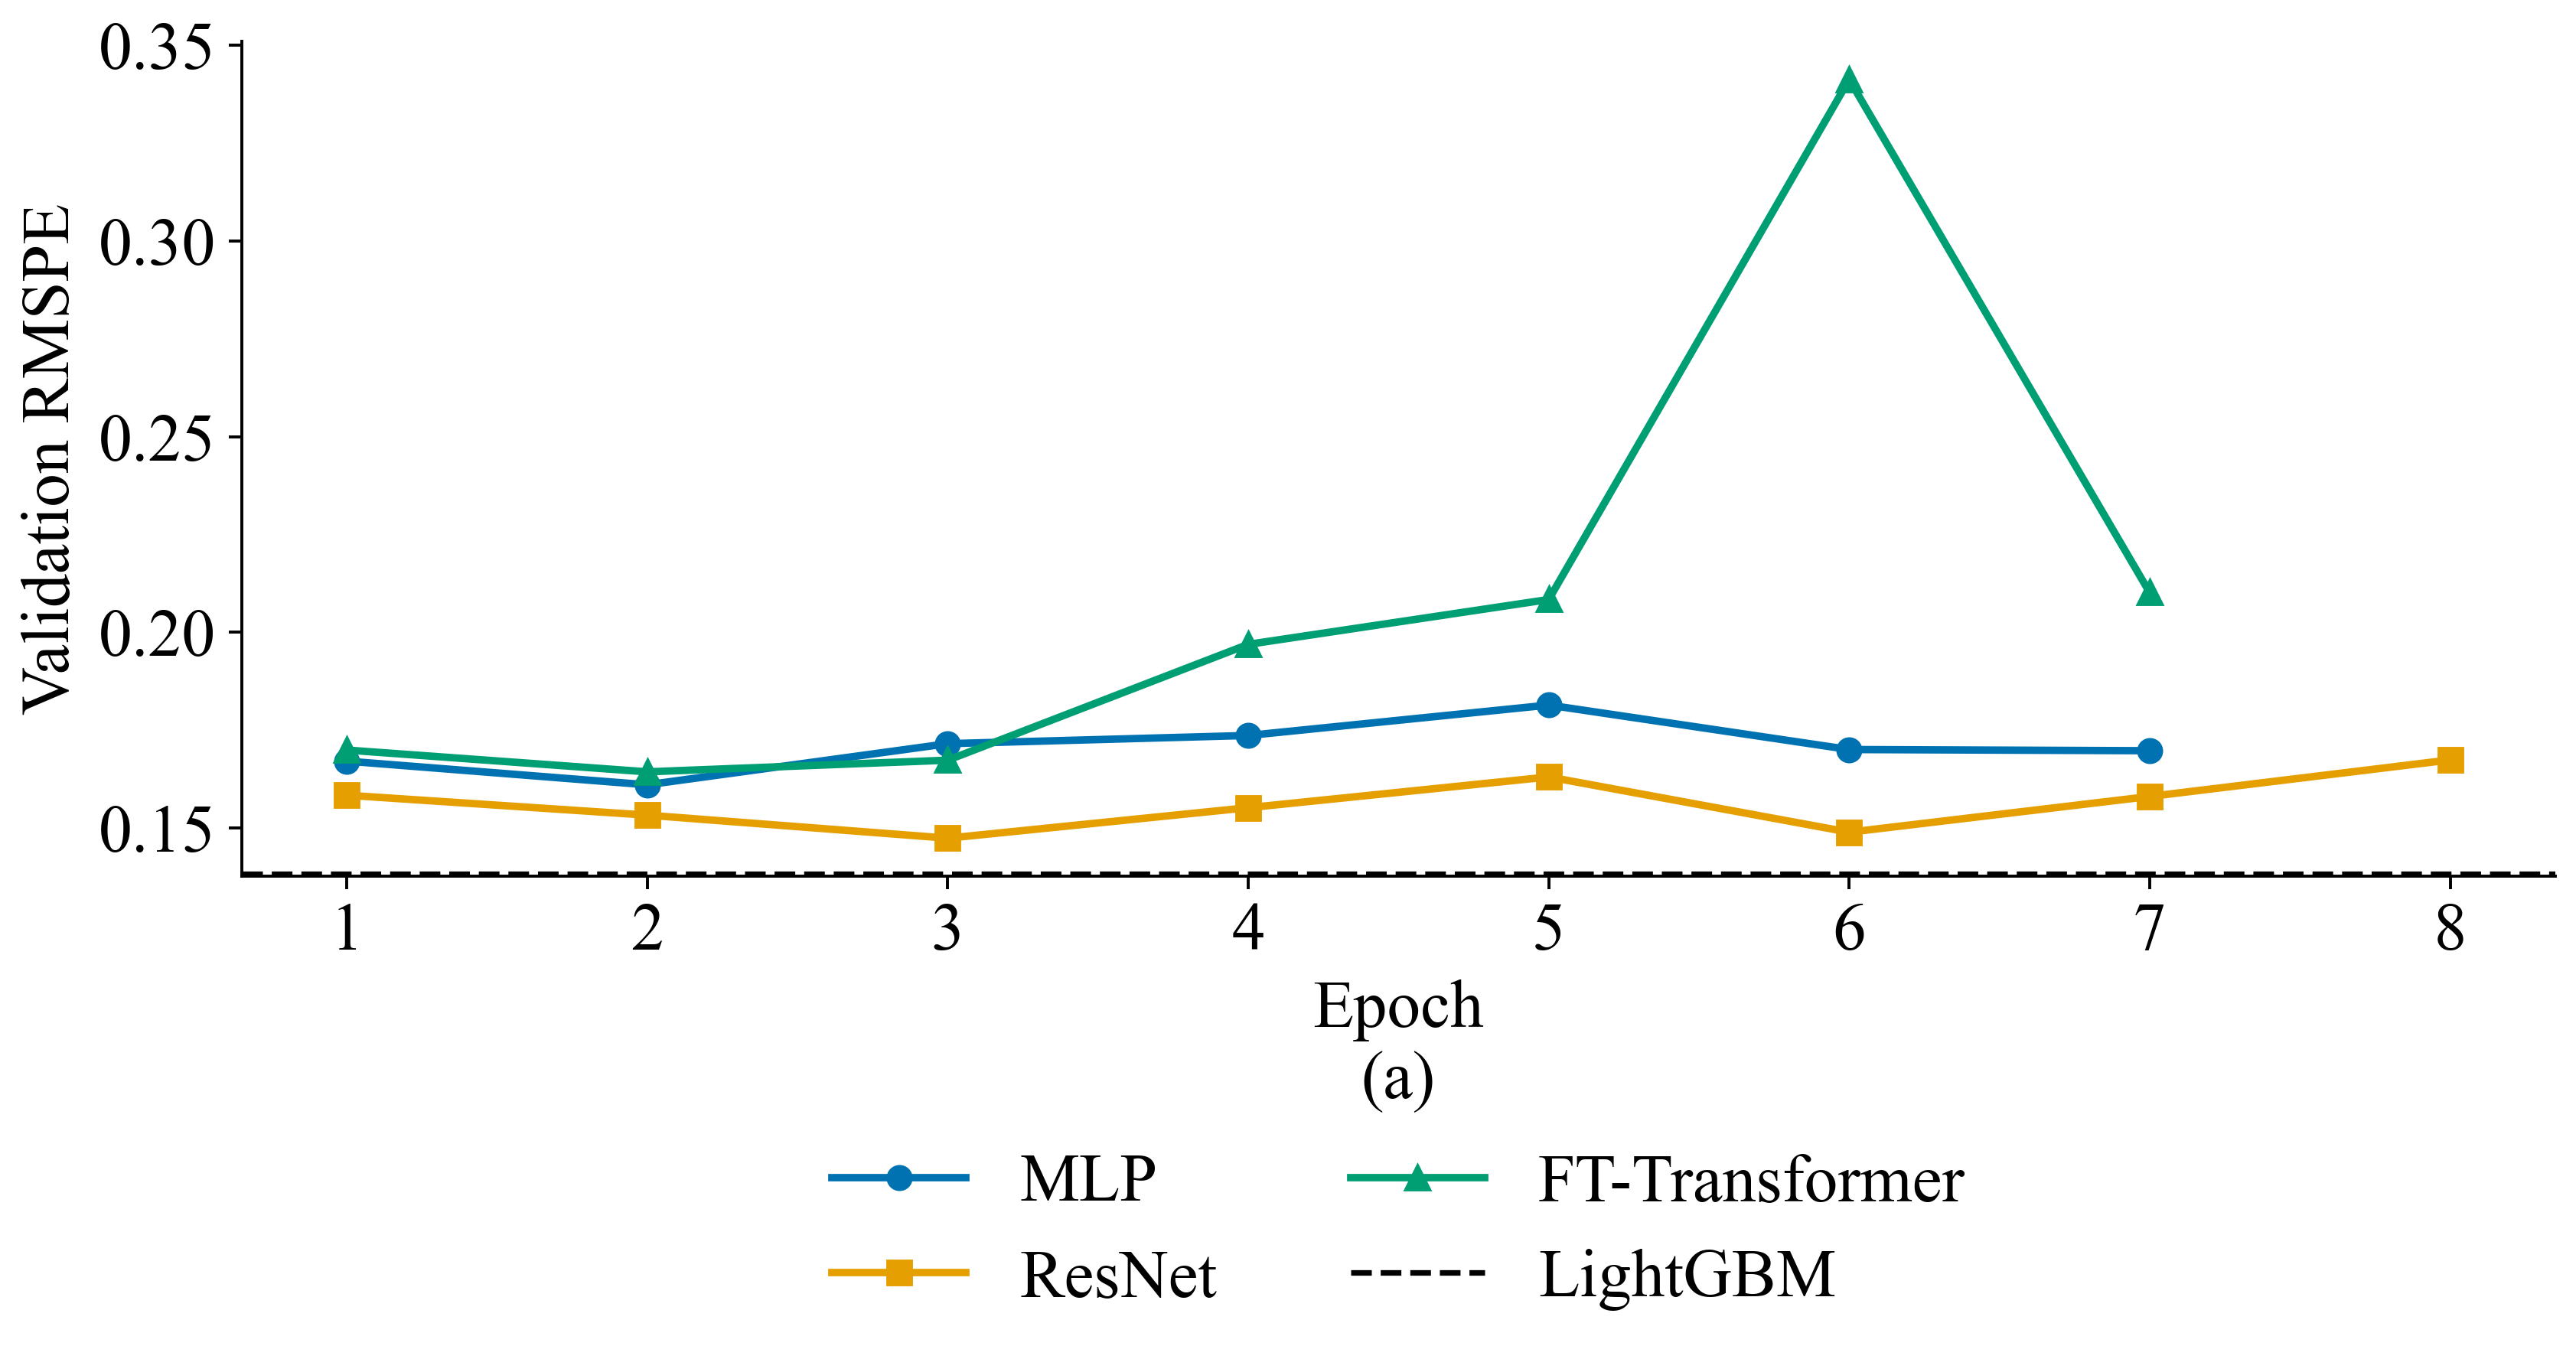

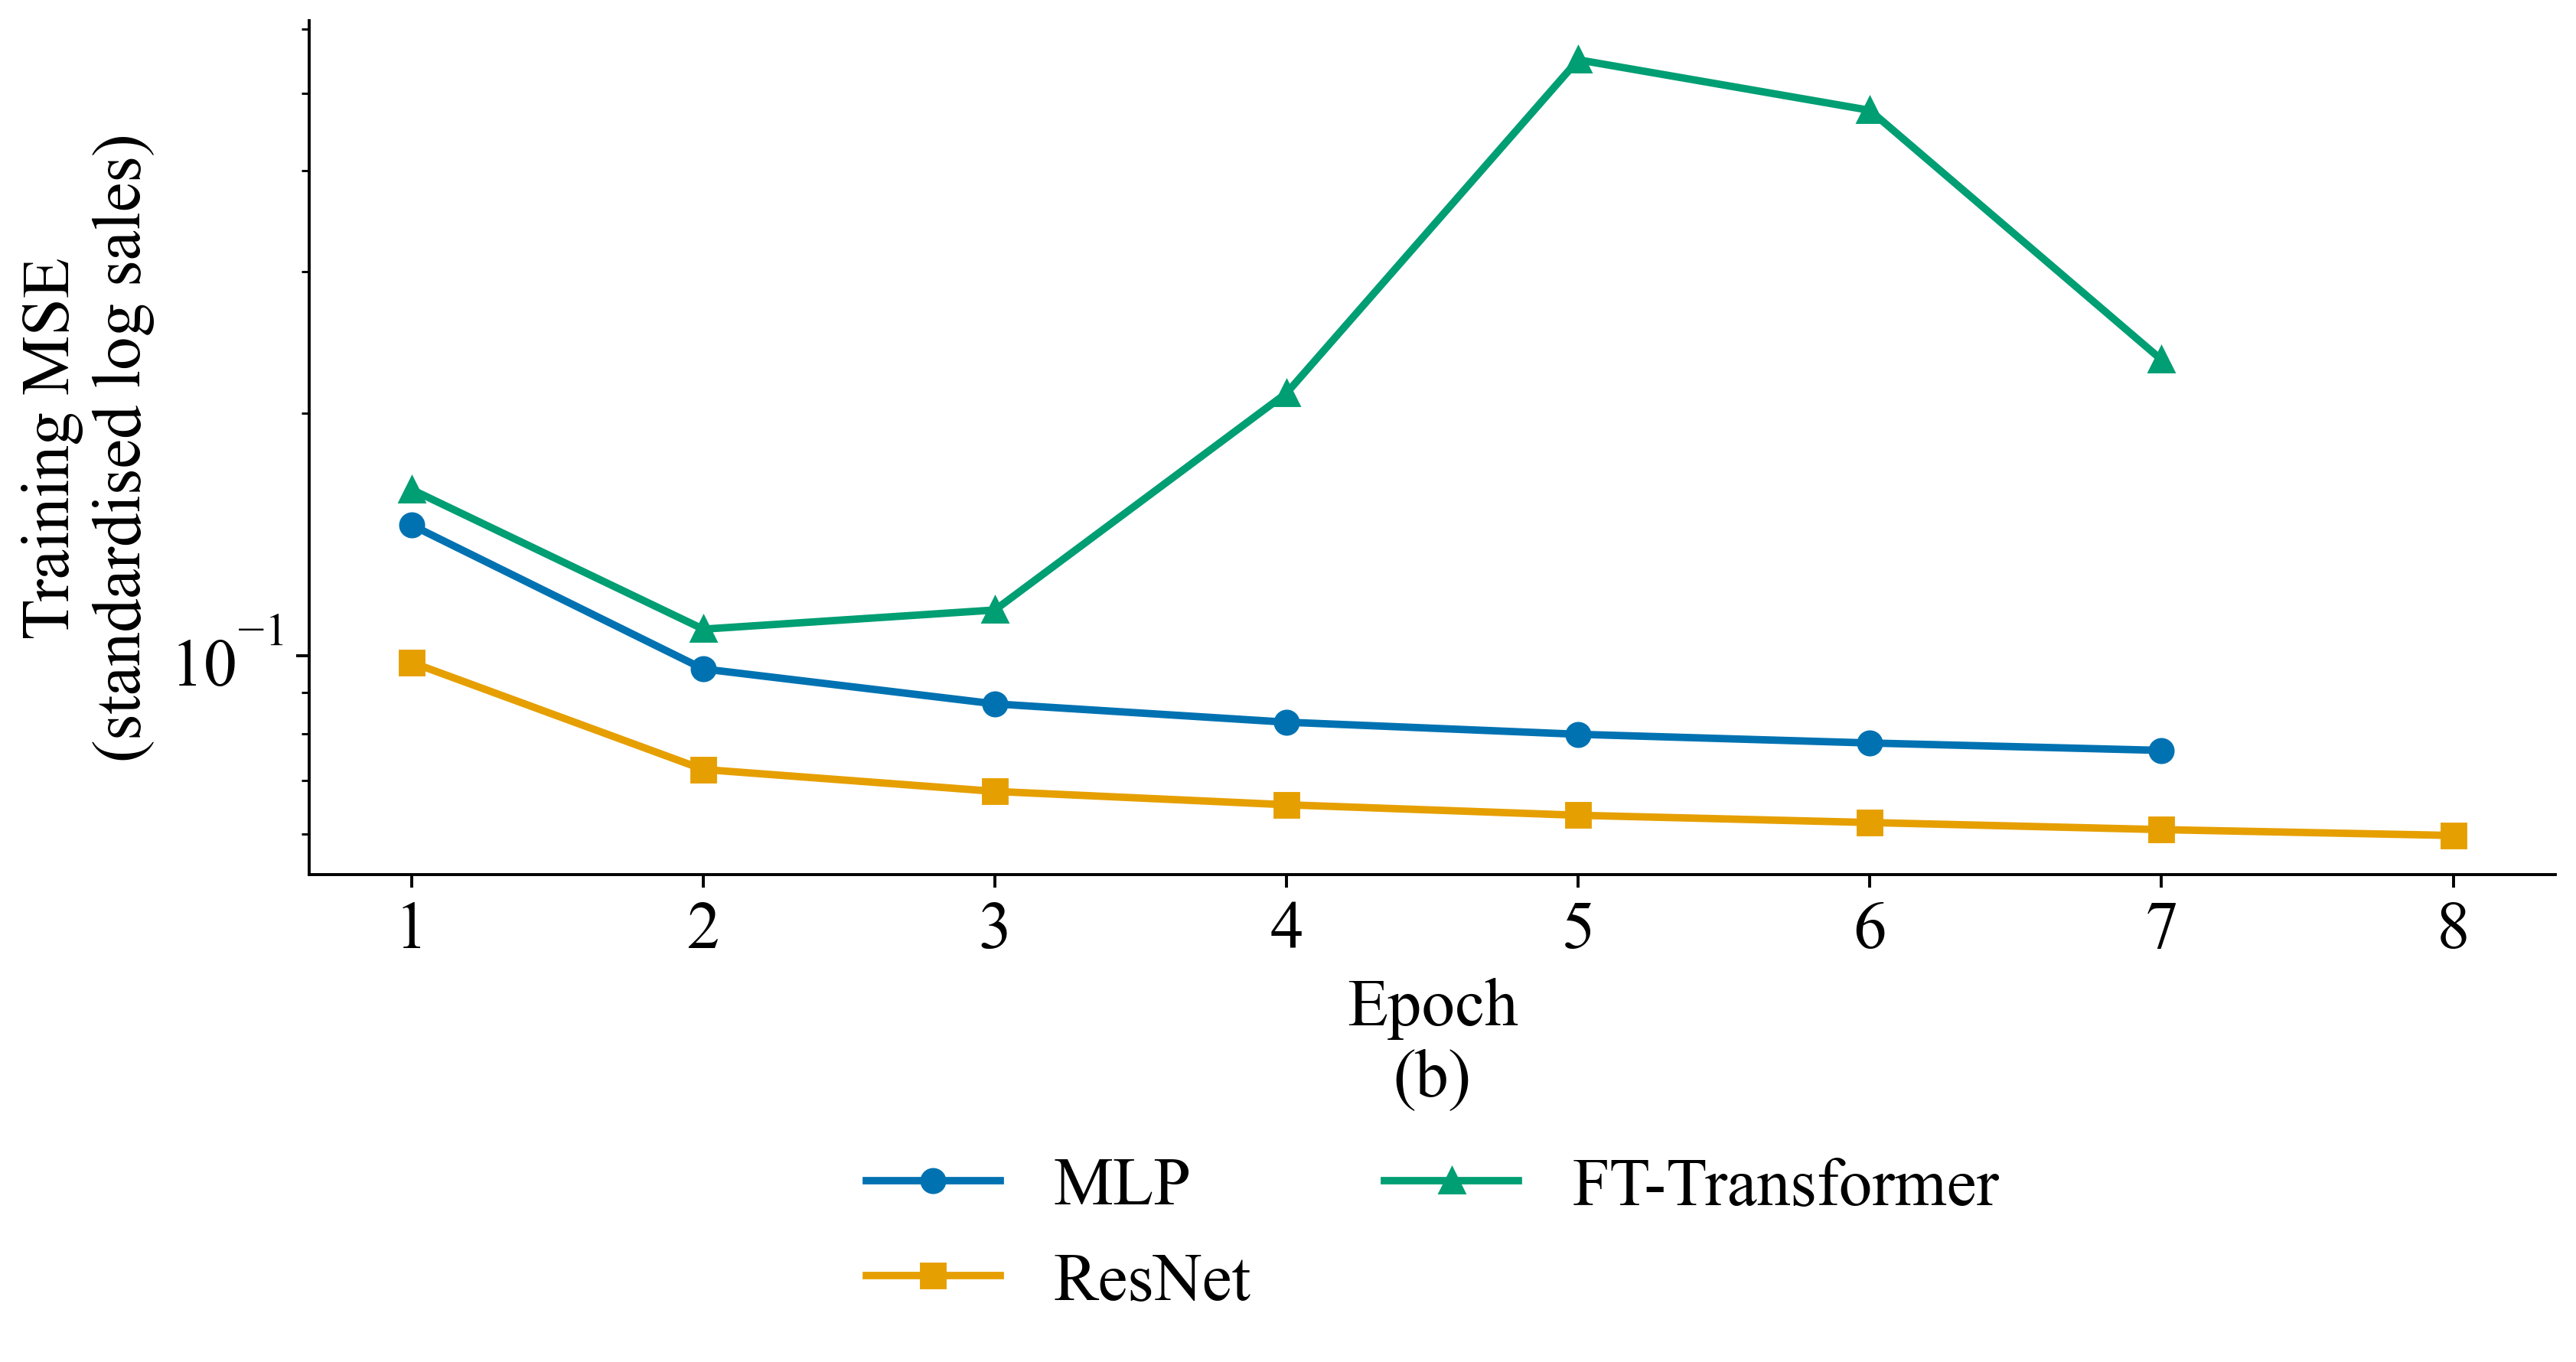

In [8]:
for panel, (metric, ylabel) in enumerate(
    [
        ("valid_RMSPE", "Validation RMSPE"),
        ("train_loss", "Training MSE\n(standardised log sales)"),
    ]
):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    for i, (name, h) in enumerate(histories.items()):
        ax.plot(
            h["epoch"],
            h[metric],
            marker=["o", "s", "^"][i],
            lw=2,
            color=PALETTE[i],
            label=name,
        )
    if panel == 0:
        ax.axhline(
            load_registry("valid", "NB03").set_index("model").loc["LightGBM", "RMSPE"],
            color="black",
            ls="--",
            label="LightGBM",
        )
    else:
        ax.set_yscale("log")
    ax.set_xlabel("Epoch\n(" + chr(97 + panel) + ")")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.26), ncol=2)
    fig.tight_layout()
    name = "fig4_1_training_dynamics" + chr(97 + panel)
    save_fig(fig, name)
    show_fig(name)

pd.concat(histories, names=["model"]).to_csv(
    TABLES / "fig4_1_training_histories_numeric.csv"
)


## 4. Probabilistic neural baselines: deep ensemble and MC dropout

In [9]:
t0 = time.time()
members = []
member_epochs = []
for s in range(5):
    print(f"Deep ensemble member {s+1}/5; seed={SEED+s}", flush=True)
    net, _, _, member_history = fit_net(
        lambda c: MLP(c["width"], c["depth"], c["dropout"], out=2),
        mlp_cfg,
        loss="nll",
        seed=SEED + s,
    )
    members.append(net)
    member_epochs.append(int(member_history.attrs["best_epoch"]))
    member_history.to_csv(
        TABLES / f"deep_ensemble_seed_{SEED+s}_training_numeric.csv", index=False
    )
mus, vars_ = [], []
t1 = time.time()
for net in members:
    mu, lv = predict_net(net, Xn_va, Xc_va)
    mus.append(mu)
    vars_.append(np.exp(lv))
mus, vars_ = np.array(mus), np.array(vars_)
mix_mu = mus.mean(0)
mix_var = (vars_ + mus**2).mean(0) - mix_mu**2
fit_s = t1 - t0
timing["Deep ensemble (5 x MLP, Gaussian NLL)"] = (0.0, fit_s, time.time() - t1)
n_params["Deep ensemble (5 x MLP, Gaussian NLL)"] = 5 * sum(
    p.numel() for p in members[0].parameters()
)
mix_weights = np.full(mus.T.shape, 1 / len(members))
mix_median = mixture_quantile(mus.T, vars_.T, mix_weights, 0.5)
lo = np.exp(mixture_quantile(mus.T, vars_.T, mix_weights, 0.05))
hi = np.exp(mixture_quantile(mus.T, vars_.T, mix_weights, 0.95))
np.savez_compressed(
    RUNS / "NB04_deep_ensemble_valid_components.npz",
    mu=mus.T,
    variance=vars_.T,
    weights=mix_weights,
)
r_de = save_run(
    "Deep ensemble (5 x MLP, Gaussian NLL)",
    NB,
    "valid",
    va,
    np.exp(mix_median),
    {
        **mlp_cfg,
        "members": 5,
        "member_seeds": list(range(SEED, SEED + 5)),
        "member_best_epochs": member_epochs,
    },
    fit_s,
    lo=lo,
    hi=hi,
    extra={"n_trials": 0, "architecture_selection": "MLP eight-trial search"},
    model_obj=members,
)


Deep ensemble member 1/5; seed=2026
Epoch 1: train loss=-0.551019, validation RMSPE=0.167530
Epoch 2: train loss=-0.743994, validation RMSPE=0.171832
Epoch 3: train loss=-0.802948, validation RMSPE=0.176657
Epoch 4: train loss=-0.835964, validation RMSPE=0.181457
Epoch 5: train loss=-0.857007, validation RMSPE=0.179662
Epoch 6: train loss=-0.872388, validation RMSPE=0.185729
Deep ensemble member 2/5; seed=2027
Epoch 1: train loss=-0.553425, validation RMSPE=0.167639
Epoch 2: train loss=-0.743383, validation RMSPE=0.165241
Epoch 3: train loss=-0.802684, validation RMSPE=0.166733
Epoch 4: train loss=-0.835553, validation RMSPE=0.184619
Epoch 5: train loss=-0.857200, validation RMSPE=0.175758
Epoch 6: train loss=-0.871548, validation RMSPE=0.179658
Epoch 7: train loss=-0.882628, validation RMSPE=0.178493
Deep ensemble member 3/5; seed=2028
Epoch 1: train loss=-0.530935, validation RMSPE=0.179396
Epoch 2: train loss=-0.744273, validation RMSPE=0.179531
Epoch 3: train loss=-0.806272, valida

In [10]:
t0 = time.time()
mc_cfg = {**mlp_cfg, "dropout": max(mlp_cfg["dropout"], 0.1)}
mc_net, _, _, mc_history = fit_net(
    lambda c: MLP(c["width"], c["depth"], c["dropout"]), mc_cfg
)
mc_history.to_csv(TABLES / "mc_dropout_training_numeric.csv", index=False)
t1 = time.time()
torch.manual_seed(SEED)
samples = np.array([predict_net(mc_net, Xn_va, Xc_va, mc=1)[0] for _ in range(50)])
resid_sd = float(
    np.std((y_va - samples.mean(0))[va.Date <= "2015-04-24"])
)  # aleatoric scale from validation residuals (homoscedastic)
mc_mu, mc_sd = samples.mean(0), np.sqrt(samples.var(0) + resid_sd**2)
fit_s = t1 - t0
timing["MC-dropout MLP"] = (0.0, fit_s, time.time() - t1)
n_params["MC-dropout MLP"] = sum(p.numel() for p in mc_net.parameters())
r_mc = save_run(
    "MC-dropout MLP",
    NB,
    "valid",
    va,
    np.exp(mc_mu),
    {
        **mc_cfg,
        "best_epoch": int(mc_history.attrs["best_epoch"]),
        "mc_samples": 50,
        "residual_sd": resid_sd,
        "scale_fit_end": "2015-04-24",
    },
    fit_s,
    lo=np.exp(mc_mu - 1.645 * mc_sd),
    hi=np.exp(mc_mu + 1.645 * mc_sd),
    extra={"n_trials": 0, "architecture_selection": "MLP eight-trial search"},
    model_obj=mc_net,
)
prob_tab = pd.DataFrame([r_de, r_mc]).set_index("model")[
    ["RMSPE", "RMSPE_lo", "RMSPE_hi", "PICP90", "MPIW90_rel"]
]
save_table(
    prob_tab,
    "tab4_1_probabilistic_baselines",
    "Point accuracy and 90 % interval coverage and relative width of the probabilistic neural baselines on the validation period.",
)


Epoch 1: train loss=0.145259, validation RMSPE=0.167142
Epoch 2: train loss=0.096205, validation RMSPE=0.163564
Epoch 3: train loss=0.086985, validation RMSPE=0.172282
Epoch 4: train loss=0.082569, validation RMSPE=0.174179
Epoch 5: train loss=0.079864, validation RMSPE=0.179924
Epoch 6: train loss=0.077850, validation RMSPE=0.169675
Epoch 7: train loss=0.076253, validation RMSPE=0.170808


,RMSPE,RMSPE_lo,RMSPE_hi,PICP90,MPIW90_rel
model,,,,,
"Deep ensemble (5 x MLP, Gaussian NLL)",0.1652,0.1479,0.1890,0.8786,0.4285
MC-dropout MLP,0.1589,0.1429,0.1835,0.9251,0.4938


In [11]:
levels = [0.5, 0.8, 0.9, 0.95, 0.99]
y_obs = va["Sales"].values
rel_rows = []
for name, mu_, sd_ in [
    ("Deep ensemble (5 x MLP, Gaussian NLL)", mix_mu, np.sqrt(mix_var)),
    ("MC-dropout MLP", mc_mu, mc_sd),
]:
    for q in levels:
        # Match the actually saved MC 90% interval (rounded normal multiplier).
        z = 1.645 if name == "MC-dropout MLP" and q == 0.9 else norm.ppf(0.5 + q / 2)
        l_, h_ = np.exp(mu_ - z * sd_), np.exp(mu_ + z * sd_)
        if name.startswith("Deep ensemble"):
            l_ = np.exp(mixture_quantile(mus.T, vars_.T, mix_weights, (1 - q) / 2))
            h_ = np.exp(mixture_quantile(mus.T, vars_.T, mix_weights, (1 + q) / 2))
        rel_rows.append(
            {
                "model": name,
                "nominal coverage": q,
                "empirical coverage": float(np.mean((y_obs >= l_) & (y_obs <= h_))),
                "mean relative width": float(np.mean((h_ - l_) / y_obs)),
            }
        )
qlgb = pd.read_csv(RUNS / "NB03_LightGBM_(quantile_90%_PI)_valid" / "predictions.csv")
rel_rows.append(
    {
        "model": "LightGBM (quantile 90% PI)",
        "nominal coverage": 0.9,
        "empirical coverage": float(
            np.mean((qlgb["y"] >= qlgb["lo90"]) & (qlgb["y"] <= qlgb["hi90"]))
        ),
        "mean relative width": float(
            np.mean((qlgb["hi90"] - qlgb["lo90"]) / qlgb["y"])
        ),
    }
)
reliability = pd.DataFrame(rel_rows).set_index(["model", "nominal coverage"])
reliability["coverage gap"] = reliability[
    "empirical coverage"
] - reliability.index.get_level_values(1)
_ = save_table(
    reliability,
    "tab4_2_interval_reliability",
    "Reliability of the prediction intervals on the validation period: empirical coverage and mean relative width at five nominal levels (quantile LightGBM only at 90 %).",
)


## 5. Classical ensembles of the NB03 boosters

In [12]:
from scipy.optimize import nnls

base = ["LightGBM", "XGBoost", "CatBoost"]
P = np.column_stack(
    [
        pd.read_csv(RUNS / f"NB03_{b}_valid" / "predictions.csv")["pred"].values
        for b in base
    ]
)
assert (
    pd.read_csv(RUNS / "NB03_LightGBM_valid" / "predictions.csv")["row_id"].values
    == va["row_id"].values
).all()
r_avg = save_run(
    "Uniform average (3 boosters)", NB, "valid", va, P.mean(1), {"members": base}, 0.0
)
# rolling-origin NNLS stacking on the log scale: weights refitted weekly from validation days with available labels (lag 7)
logP, logy = np.log(P), y_va.astype(float)
dates = va["Date"].values
day0 = dates.min()
dnum = ((dates - day0) / np.timedelta64(1, "D")).astype(int)
w_hist, pred_stack = [], np.full(len(va), np.nan)
for wk in range(0, dnum.max() + 1, 7):
    cur = (dnum >= wk) & (dnum < wk + 7)
    known = (
        dnum <= wk - design["label_lag_days"]
    )  # outcomes available by the first day of the week
    if known.sum() < 1000:
        w = np.ones(3) / 3
    else:
        w, _ = nnls(logP[known], logy[known])
        w = w / w.sum() if w.sum() > 0 else np.ones(3) / 3
    pred_stack[cur] = np.exp(logP[cur] @ w)
    w_hist.append(
        {"week_start": pd.Timestamp(day0) + pd.Timedelta(days=wk), **dict(zip(base, w))}
    )
r_stk = save_run(
    "NNLS stacking (rolling, 3 boosters)",
    NB,
    "valid",
    va,
    pred_stack,
    {"members": base, "refit": "weekly, 7-day lag"},
    0.0,
)
save_table(
    pd.DataFrame(w_hist).set_index("week_start"),
    "tab4_3_stacking_weights",
    "Weekly NNLS stacking weights (log scale) estimated from validation days with available labels.",
)

,LightGBM,XGBoost,CatBoost
week_start,,,
2015-01-01,0.3333,0.3333,0.3333
2015-01-08,0.3333,0.3333,0.3333
2015-01-15,0.1789,0.8211,0.0000
2015-01-22,0.5348,0.4502,0.0150
2015-01-29,0.6042,0.2855,0.1103
2015-02-05,0.5676,0.2991,0.1333
2015-02-12,0.4866,0.3326,0.1808
2015-02-19,0.5050,0.3065,0.1885
2015-02-26,0.4219,0.3187,0.2594


## 6. Stability of the networks across inner folds

In [13]:
fold_sets = {
    f: (
        tr[tr["Date"] <= b["fit_end"]],
        tr[(tr["Date"] >= b["eval_start"]) & (tr["Date"] <= b["eval_end"])],
    )
    for f, b in INNER_FOLDS.items()
}


def net_oof(name, make, cfg, epochs):
    parts, secs, fold_metadata = [], [], []
    for f, (fit, ev) in fold_sets.items():
        print(
            f"{name}: forward fold {f}; fit={len(fit):,}, evaluate={len(ev):,}; epochs={epochs}",
            flush=True,
        )
        st = fold_stats(fit)
        mu_f, sd_f = float(fit["log_sales"].mean()), float(fit["log_sales"].std())
        Xn_f, Xc_f = tensors(fit, st)
        Xn_e, Xc_e = tensors(ev, st)
        t0 = time.time()
        net, _, _, _ = fit_net(
            make,
            cfg,
            data=(
                Xn_f,
                Xc_f,
                torch.tensor(
                    ((fit["log_sales"].values - mu_f) / sd_f).astype(np.float32)
                ),
            ),
            fixed_epochs=epochs,
        )
        secs.append(time.time() - t0)
        p = np.exp(predict_net(net, Xn_e, Xc_e, mu_sd=(mu_f, sd_f))[0])
        fold_metadata.append(
            {
                "fold": f,
                "fit_end": str(fit.Date.max().date()),
                "evaluation_start": str(ev.Date.min().date()),
                "evaluation_end": str(ev.Date.max().date()),
                "fit_rows": len(fit),
                "evaluation_rows": len(ev),
                "fit_seconds": secs[-1],
                "preprocessing": st,
                "target_mean": mu_f,
                "target_std": sd_f,
            }
        )
        parts.append(
            pd.DataFrame(
                {
                    "fold": f,
                    "row_id": ev["row_id"].values,
                    "Store": ev["Store"].values,
                    "Date": ev["Date"].values,
                    "y": ev["Sales"].values,
                    "pred": p,
                }
            )
        )
    oof = pd.concat(parts, ignore_index=True)
    run_id = f"{NB}_{name}_inner_oof".replace(" ", "_")
    rd = RUNS / run_id
    rd.mkdir(parents=True, exist_ok=True)
    (rd / "OOF_Predictions").mkdir(exist_ok=True)
    oof.to_csv(rd / "OOF_Predictions/predictions.csv", index=False)
    if not (rd / "predictions.csv").exists():
        (rd / "predictions.csv").symlink_to("OOF_Predictions/predictions.csv")
    (rd / "config.json").write_text(
        json.dumps(
            {
                "model": name,
                "notebook": NB,
                "stage": "inner_oof",
                "seed": SEED,
                "config": cfg,
                "fixed_epochs": epochs,
                "features": FEATURES,
                "experiment_id": EXPERIMENT_ID,
                "notebook_run_id": RUN_ID,
                "cpu_threads": N_JOBS,
                "device": str(DEVICE),
                "package_versions": PACKAGE_VERSIONS,
                "fit_seconds": float(np.sum(secs)),
                "folds": fold_metadata,
                "selection_scope": "Later development-selected architecture and checkpoint length; temporal diagnostics are not nested selection estimates",
                "timestamp": pd.Timestamp.now(tz="UTC").isoformat(),
            },
            indent=2,
            default=lambda v: (
                v.item()
                if isinstance(v, np.generic)
                else v.tolist() if isinstance(v, np.ndarray) else str(v)
            ),
        )
    )
    m = point_metrics(oof["y"], oof["pred"])
    m["RMSPE_lo"], m["RMSPE_hi"] = bootstrap_ci(oof["y"], oof["pred"], oof["Store"])
    register(
        {
            "run_id": run_id,
            "notebook": NB,
            "model": name,
            "stage": "inner_oof",
            **m,
            "fit_seconds": float(np.sum(secs)),
            "timestamp": pd.Timestamp.utcnow().isoformat(),
        }
    )
    return oof.groupby("fold").apply(
        lambda g: rmspe(g["y"], g["pred"]), include_groups=False
    )


oof_mlp = net_oof(
    "MLP",
    lambda c: MLP(c["width"], c["depth"], c["dropout"]),
    mlp_cfg,
    int(histories["MLP"].attrs["best_epoch"]),
)
oof_res = net_oof(
    "ResNet",
    lambda c: ResNet(c["d"], c["depth"], c["dropout"]),
    res_cfg,
    int(histories["ResNet"].attrs["best_epoch"]),
)
oof_ft = net_oof(
    "FT-Transformer",
    lambda c: FTTransformer(c["d"], c["depth"], c["heads"], c["dropout"]),
    ft_cfg,
    int(histories["FT-Transformer"].attrs["best_epoch"]),
)
fold_nb03 = {}
for m in ["Ridge regression", "Random forest", "LightGBM", "XGBoost", "CatBoost"]:
    o = pd.read_csv(RUNS / f"NB03_{m.replace(' ', '_')}_inner_oof" / "predictions.csv")
    fold_nb03[m] = o.groupby("fold").apply(
        lambda g: rmspe(g["y"], g["pred"]), include_groups=False
    )
fold_tab = pd.DataFrame({**fold_nb03, "MLP": oof_mlp, "ResNet": oof_res, "FT-Transformer": oof_ft}).T
fold_tab.columns = [
    f"{f} ({INNER_FOLDS[f]['eval_start'][:7]} .. {INNER_FOLDS[f]['eval_end'][:7]})"
    for f in fold_tab.columns
]
fold_tab["mean of folds"] = fold_tab.mean(axis=1)
fold_tab["sd of folds"] = fold_tab.iloc[:, :3].std(axis=1)
fold_tab["valid (2015)"] = (
    load_registry("valid", ["NB03", "NB04"])
    .drop_duplicates("model", keep="last")
    .set_index("model")
    .loc[fold_tab.index, "RMSPE"]
)
fold_tab["rank by folds"] = fold_tab["mean of folds"].rank().astype(int)
fold_tab["rank on valid"] = fold_tab["valid (2015)"].rank().astype(int)
save_table(
    fold_tab,
    "tab4_4_inner_fold_stability",
    "RMSPE on the three inner folds of 2014 (out-of-fold) and on the validation period for the baselines and the two networks; ranks compare the protocols.",
)

MLP: forward fold F1; fit=374,869, evaluate=72,971; epochs=2
Fixed epoch 1/2: train loss=0.168207
Fixed epoch 2/2: train loss=0.108652
MLP: forward fold F2; fit=447,836, evaluate=66,408; epochs=2
Fixed epoch 1/2: train loss=0.158911
Fixed epoch 2/2: train loss=0.103040
MLP: forward fold F3; fit=515,047, evaluate=60,193; epochs=2
Fixed epoch 1/2: train loss=0.150075
Fixed epoch 2/2: train loss=0.099891
ResNet: forward fold F1; fit=374,869, evaluate=72,971; epochs=3
Fixed epoch 1/3: train loss=0.111075
Fixed epoch 2/3: train loss=0.081539
Fixed epoch 3/3: train loss=0.076560
ResNet: forward fold F2; fit=447,836, evaluate=66,408; epochs=3
Fixed epoch 1/3: train loss=0.104996
Fixed epoch 2/3: train loss=0.076779
Fixed epoch 3/3: train loss=0.072426
ResNet: forward fold F3; fit=515,047, evaluate=60,193; epochs=3
Fixed epoch 1/3: train loss=0.101199
Fixed epoch 2/3: train loss=0.075141
Fixed epoch 3/3: train loss=0.070193
FT-Transformer: forward fold F1; fit=374,869, evaluate=72,971; epochs=

,F1 (2014-04 .. 2014-06),F2 (2014-07 .. 2014-09),F3 (2014-10 .. 2014-12),mean of folds,sd of folds,valid (2015),rank by folds,rank on valid
Ridge regression,0.1641,0.1621,0.1861,0.1708,0.0133,0.1943,5,8
Random forest,0.1261,0.1264,0.1366,0.1297,0.0060,0.1652,4,7
LightGBM,0.1211,0.1200,0.1259,0.1223,0.0031,0.1383,1,2
XGBoost,0.1237,0.1232,0.1245,0.1238,0.0006,0.1385,2,3
CatBoost,0.1179,0.1275,0.1296,0.1250,0.0062,0.1381,3,1
MLP,0.1647,0.2889,0.1725,0.2087,0.0695,0.1611,7,5
ResNet,0.1472,0.3100,0.1550,0.2041,0.0918,0.1474,6,4
FT-Transformer,1.1577,0.3751,0.4570,0.6633,0.4302,0.1644,8,6


## 7. Regimes: where each family is strong or weak

In [14]:
MODELS = {
    "LightGBM": "NB03",
    "CatBoost": "NB03",
    "MLP": "NB04",
    "ResNet": "NB04",
    "FT-Transformer": "NB04",
    "Deep ensemble (5 x MLP, Gaussian NLL)": "NB04",
    "MC-dropout MLP": "NB04",
    "Uniform average (3 boosters)": "NB04",
    "NNLS stacking (rolling, 3 boosters)": "NB04",
}
preds = {
    m: pd.read_csv(
        RUNS / f"{nb}_{m.replace(' ', '_').replace('/', '-')}_valid" / "predictions.csv"
    )["pred"].values
    for m, nb in MODELS.items()
}
ctx = va.assign(
    weekday=va["dow"].map(
        {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
    ),
    promotion=va["promo"].map({0: "no promo", 1: "promo"}),
    store_type=va["store_type"].map({0: "a", 1: "b", 2: "c", 3: "d"}),
    holiday_window=np.where(
        (va["days_to_holiday"] <= 3) | (va["days_since_holiday"] <= 3),
        "within 3 d of a holiday",
        "other days",
    ),
    sales_quintile=pd.qcut(
        va["Sales"], 5, labels=[f"Q{i}" for i in range(1, 6)]
    ).astype(str),
    valid_week=((va["Date"] - va["Date"].min()).dt.days // 7 + 1),
)


def regime_table(col, models=preds):
    out = {
        m: (((ctx["Sales"] - p) / ctx["Sales"]) ** 2).groupby(ctx[col]).mean().pow(0.5)
        for m, p in models.items()
    }
    out = pd.DataFrame(out)
    out.insert(0, "store-days", ctx.groupby(col).size())
    return out


by_regime = pd.concat(
    {
        "weekday": regime_table("weekday"),
        "promotion": regime_table("promotion"),
        "store type": regime_table("store_type"),
        "holiday window": regime_table("holiday_window"),
    }
)
save_table(
    by_regime,
    "tab4_5_error_by_regime",
    "Validation RMSPE of the competitors and the two selected boosters by weekday, promotion status, store type and holiday proximity.",
)


store-days LightGBM CatBoost    MLP ResNet FT-Transformer Deep ensemble (5 x MLP, Gaussian NLL) MC-dropout MLP Uniform average (3 boosters) NNLS stacking (rolling, 3 boosters)
weekday        Fri                          16052   0.1174   0.1043 0.1346 0.1260         0.1284                                0.1370         0.1373                       0.1075                              0.1090
               Mon                          15031   0.1382   0.1371 0.1404 0.1352         0.1874                                0.1452         0.1404                       0.1346                              0.1389
               Sat                          16037   0.1900   0.1939 0.2338 0.2025         0.2149                                0.2295         0.2223                       0.1894                              0.1887
               Sun                            338   0.2538   0.2207 0.4817 0.3558         0.5115                                0.7130         0.4686                       0.2290                              0.2278
               Thu                          16046   0.1210   0.1184 0.1382 0.1260         0.1414                                0.1422         0.1379                       0.1174                              0.1189
               Tue                          15760   0.1288   0.1374 0.1468 0.1353         0.1621                                0.1516         0.1523                       0.1276                              0.1279
               Wed                          16030   0.1164   0.1166 0.1331 0.1363         0.1166                                0.1319         0.1295                       0.1142                              0.1142
promotion      no promo                     51490   0.1468   0.1487 0.1739 0.1517         0.1681                                0.1793         0.1668                       0.1456                              0.1465
               promo                        43804   0.1276   0.1244 0.1445 0.1422         0.1598                                0.1469         0.1490                       0.1214                              0.1226
store type     a                            50882   0.1426   0.1440 0.1729 0.1501         0.1704                                0.1751         0.1682                       0.1398                              0.1404
               b                             1824   0.1233   0.1205 0.1637 0.1306         0.1617                                0.1564         0.1568                       0.1163                              0.1160
               c                            12756   0.1530   0.1478 0.1636 0.1611         0.1848                                0.1731         0.1676                       0.1491                              0.1512
               d                            29832   0.1244   0.1237 0.1371 0.1374         0.1434                                0.1434         0.1373                       0.1207                              0.1221
holiday window other days                   81416   0.1306   0.1315 0.1515 0.1390         0.1484                                0.1536         0.1467                       0.1283                              0.1296
               within 3 d of a holiday      13878   0.1769   0.1716 0.2087 0.1893         0.2372                                0.2212         0.2168                       0.1691                              0.1688

In [15]:
by_range = regime_table("sales_quintile")
by_range.insert(
    1,
    "sales range (EUR)",
    [
        f"{int(g['Sales'].min()):,} – {int(g['Sales'].max()):,}"
        for _, g in ctx.groupby("sales_quintile")
    ],
)
_ = save_table(
    by_range,
    "tab4_6_error_by_sales_range",
    "Validation RMSPE of the competitors by quintile of the observed daily sales.",
)
by_week = regime_table("valid_week")
by_week.insert(
    1,
    "week starting",
    [str(g["Date"].min().date()) for _, g in ctx.groupby("valid_week")],
)
_ = save_table(
    by_week,
    "tab4_7_error_by_validation_week",
    "Validation RMSPE of the competitors by week of the validation period.",
)


## 8. Headroom for dynamic, context-dependent selection

The weekly and contextual oracles choose the best model after observing the validation outcomes; they are upper bounds, not forecasts.

In [16]:
from IPython.display import display

cand = [
    "LightGBM",
    "CatBoost",
    "MLP",
    "ResNet",
    "FT-Transformer",
    "NNLS stacking (rolling, 3 boosters)",
]
pe2 = pd.DataFrame({m: ((ctx["Sales"] - preds[m]) / ctx["Sales"]) ** 2 for m in cand})
week_rmspe = pe2.groupby(ctx["valid_week"]).mean().pow(0.5)
winner_week = week_rmspe.idxmin(axis=1)
cell = (
    ctx["store_type"]
    + " | "
    + ctx["promotion"]
    + " | "
    + ctx["dow"].map(
        {
            1: "Mon",
            2: "Tue–Fri",
            3: "Tue–Fri",
            4: "Tue–Fri",
            5: "Tue–Fri",
            6: "Sat",
            7: "Sun",
        }
    )
)
cell_rmspe = pe2.groupby(cell).mean().pow(0.5)
winner_cell = cell_rmspe.idxmin(axis=1)
fixed_best = pe2.mean().idxmin()
oracle_week = np.sqrt(
    np.mean([pe2.loc[i, winner_week[w]] for i, w in zip(pe2.index, ctx["valid_week"])])
)
oracle_cell = np.sqrt(
    np.mean([pe2.loc[i, winner_cell[c]] for i, c in zip(pe2.index, cell)])
)
headroom = pd.DataFrame(
    {
        "RMSPE": [
            np.sqrt(pe2[fixed_best].mean()),
            rmspe(ctx["Sales"], preds["NNLS stacking (rolling, 3 boosters)"]),
            oracle_week,
            oracle_cell,
        ],
        "what it uses": [
            "one model for the whole period",
            "weekly non-negative weights from available outcomes",
            "best model of each week (chosen on that week)",
            "best model of each context cell (chosen on validation)",
        ],
    },
    index=[
        f"fixed best single model ({fixed_best})",
        "rolling NNLS stacking (attainable)",
        "weekly oracle (upper bound)",
        "contextual oracle (upper bound)",
    ],
)
headroom["gain over fixed best %"] = 100 * (
    1 - headroom["RMSPE"] / headroom["RMSPE"].iloc[0]
)
display(
    save_table(
        headroom,
        "tab4_8_dynamic_selection_headroom",
        "Headroom for dynamic and context-dependent model selection on the validation period: attainable references versus oracle upper bounds.",
    )
)
winners = pd.DataFrame(
    {
        "week starting": by_week["week starting"],
        "best model of the week": winner_week,
        "RMSPE of the week's best": week_rmspe.min(axis=1),
        f"RMSPE of {fixed_best}": week_rmspe[fixed_best],
    }
)
display(
    save_table(
        winners,
        "tab4_9_weekly_winners",
        "Best model in each validation week among the candidates, with the error of the fixed best single model for comparison.",
    )
)
cell_tab = cell_rmspe.copy()
cell_tab.insert(0, "store-days", ctx.groupby(cell).size())
cell_tab["best model"] = winner_cell
save_table(
    cell_tab,
    "tab4_10_context_winners",
    "Validation RMSPE of the candidates per store-type × promotion × weekday-class context and the best model of each cell.",
)

,RMSPE,what it uses,gain over fixed best %
"fixed best single model (NNLS stacking (rolling, 3 boosters))",0.1360,one model for the whole period,0.0000
rolling NNLS stacking (attainable),0.1360,weekly non-negative weights from available outcomes,0.0000
weekly oracle (upper bound),0.1283,best model of each week (chosen on that week),5.6534
contextual oracle (upper bound),0.1331,best model of each context cell (chosen on validation),2.1737


,week starting,best model of the week,RMSPE of the week's best,"RMSPE of NNLS stacking (rolling, 3 boosters)"
valid_week,,,,
1,2015-01-01,ResNet,0.1611,0.1917
2,2015-01-08,"NNLS stacking (rolling, 3 boosters)",0.1658,0.1658
3,2015-01-15,ResNet,0.1366,0.1610
4,2015-01-22,ResNet,0.1164,0.1270
5,2015-01-29,ResNet,0.2307,0.2432
6,2015-02-05,ResNet,0.1219,0.1361
7,2015-02-12,CatBoost,0.1178,0.1247
8,2015-02-19,CatBoost,0.1503,0.1572
9,2015-02-26,"NNLS stacking (rolling, 3 boosters)",0.1021,0.1021


,store-days,LightGBM,CatBoost,MLP,ResNet,FT-Transformer,"NNLS stacking (rolling, 3 boosters)",best model
a | no promo | Mon,3227,0.1399,0.1358,0.1597,0.1217,0.2032,0.1457,ResNet
a | no promo | Sat,8585,0.2146,0.2265,0.2758,0.2232,0.2367,0.2145,"NNLS stacking (rolling, 3 boosters)"
a | no promo | Sun,61,0.4567,0.3740,1.0183,0.7357,1.0989,0.3989,CatBoost
a | no promo | Tue–Fri,15558,0.1096,0.1097,0.1212,0.1126,0.1189,0.1079,"NNLS stacking (rolling, 3 boosters)"
a | promo | Mon,4808,0.1278,0.1233,0.1280,0.1321,0.1854,0.1225,"NNLS stacking (rolling, 3 boosters)"
a | promo | Tue–Fri,18643,0.1266,0.1239,0.1492,0.1383,0.1473,0.1217,"NNLS stacking (rolling, 3 boosters)"
b | no promo | Mon,112,0.1254,0.1096,0.1711,0.1413,0.1713,0.1122,CatBoost
b | no promo | Sat,256,0.1171,0.1280,0.1665,0.1315,0.1439,0.1150,"NNLS stacking (rolling, 3 boosters)"
b | no promo | Sun,256,0.1518,0.1519,0.1641,0.1488,0.1809,0.1452,"NNLS stacking (rolling, 3 boosters)"
b | no promo | Tue–Fri,480,0.1314,0.1204,0.1824,0.1280,0.1733,0.1213,CatBoost


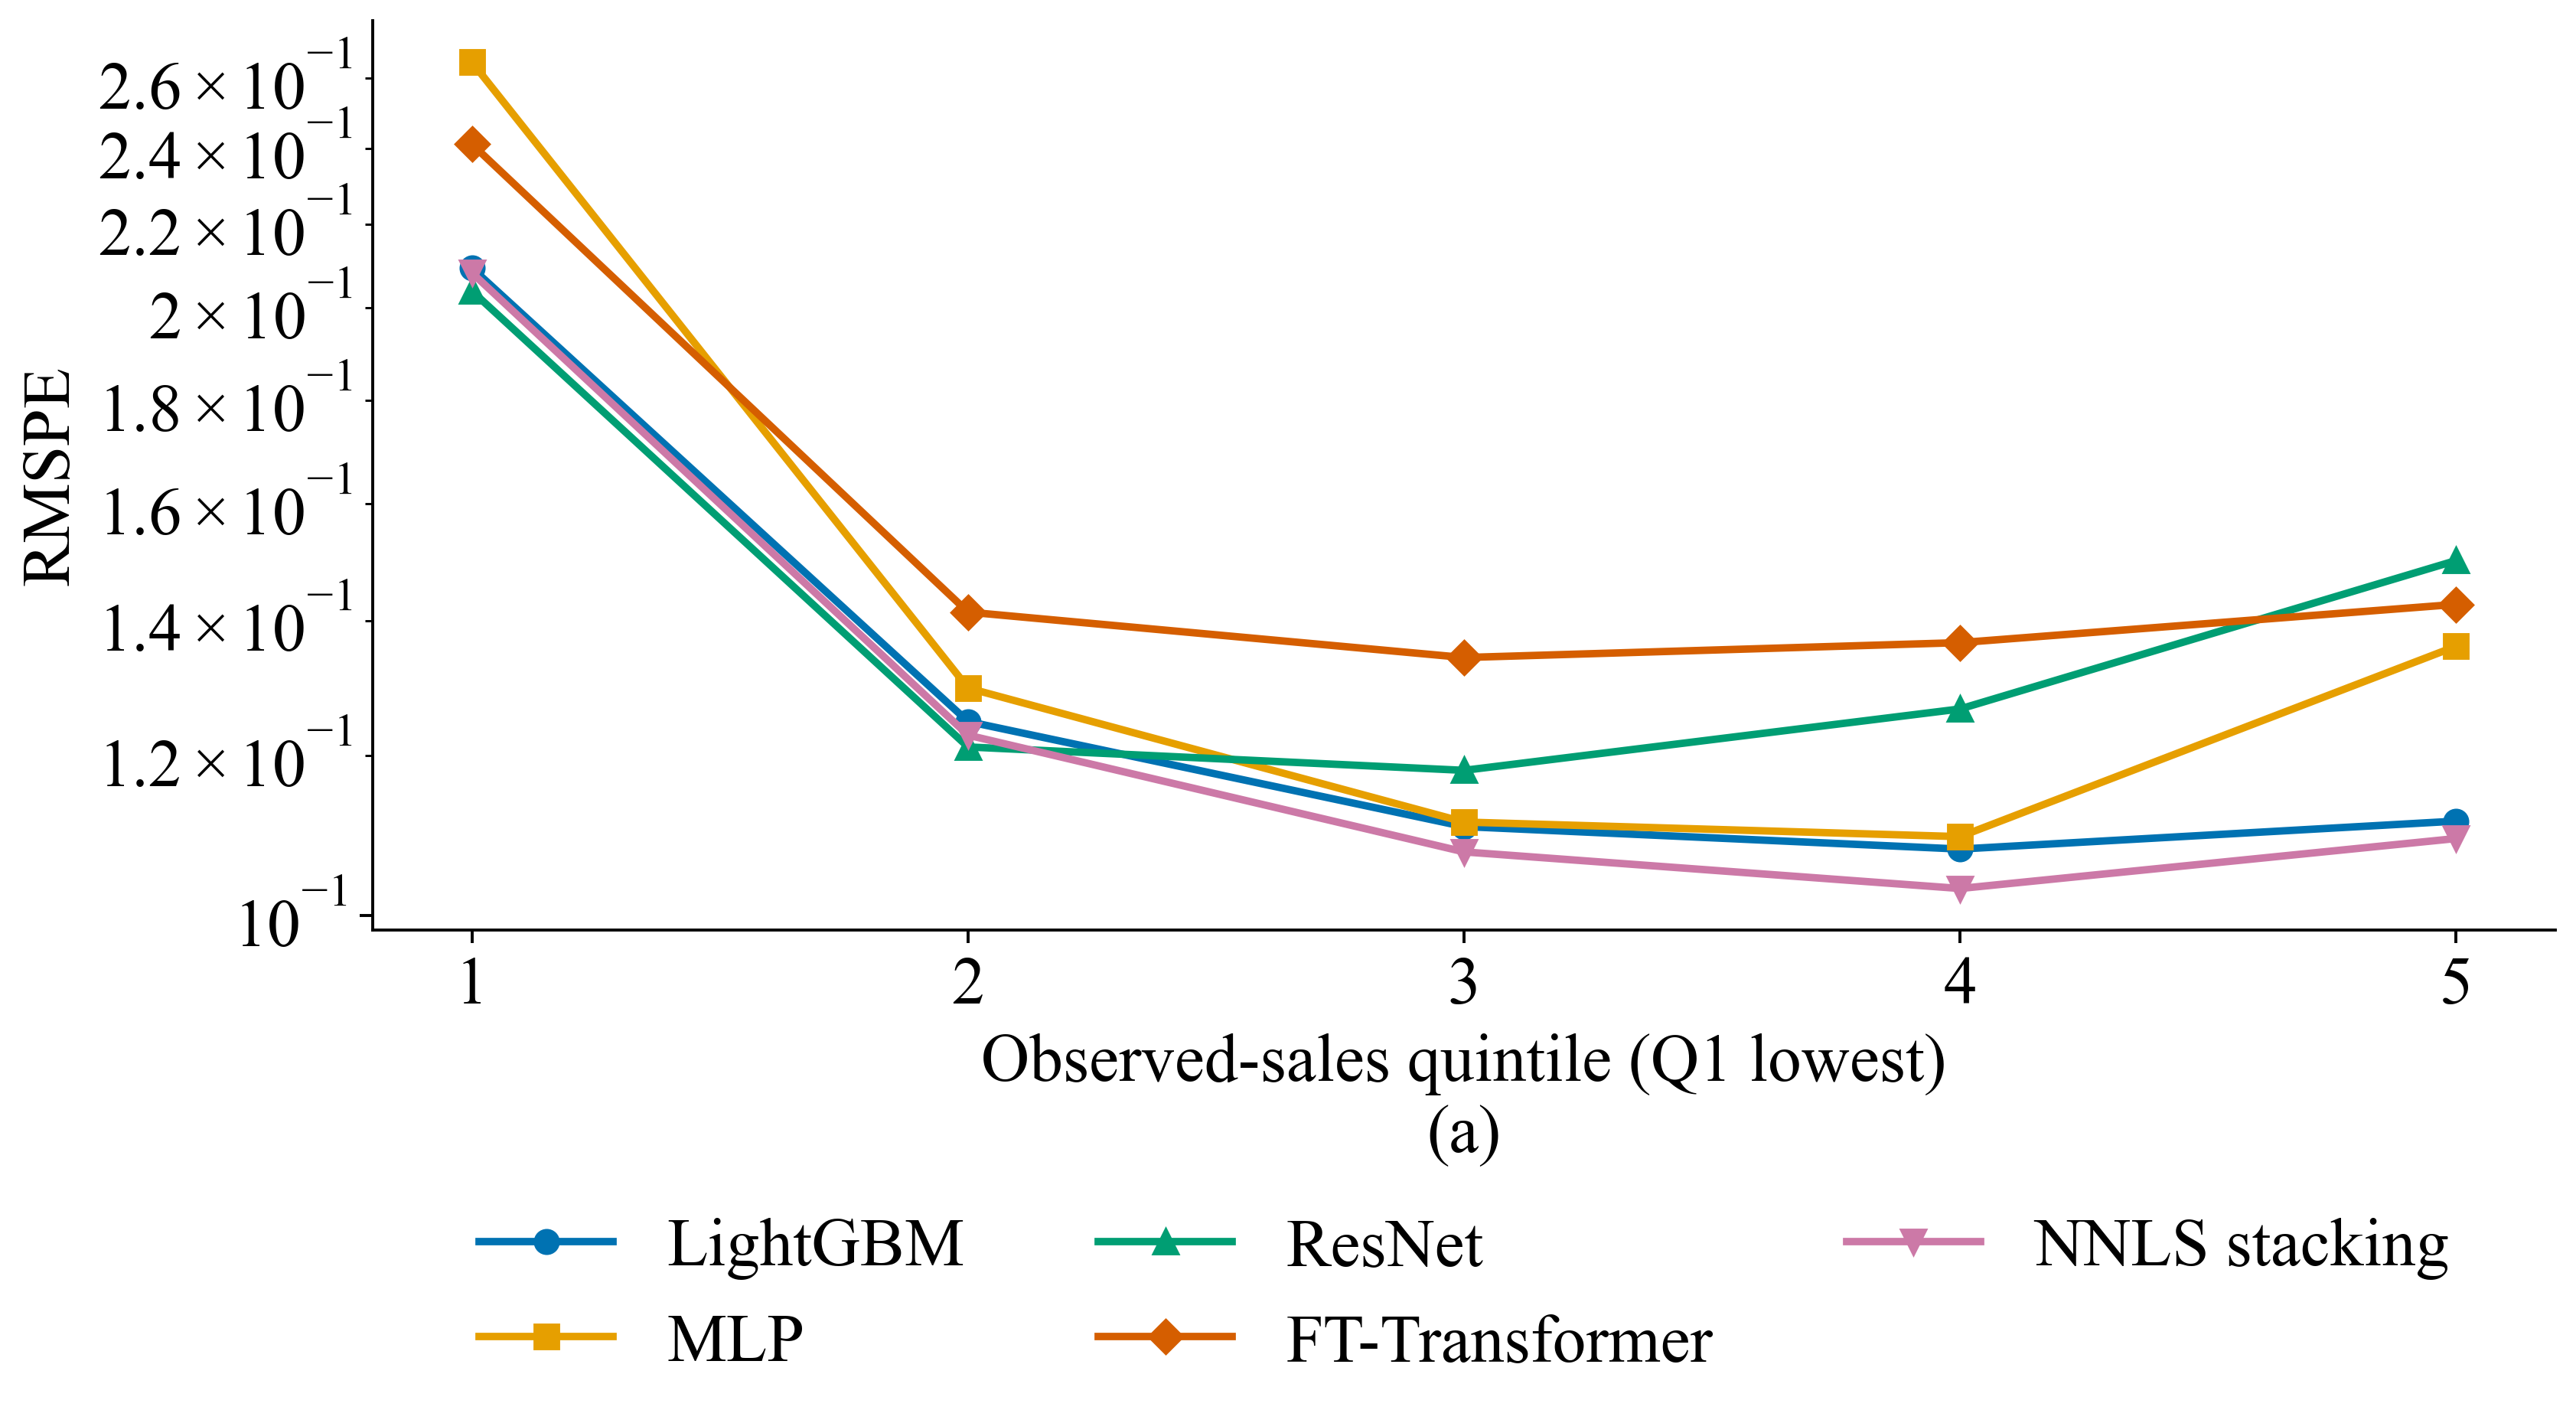

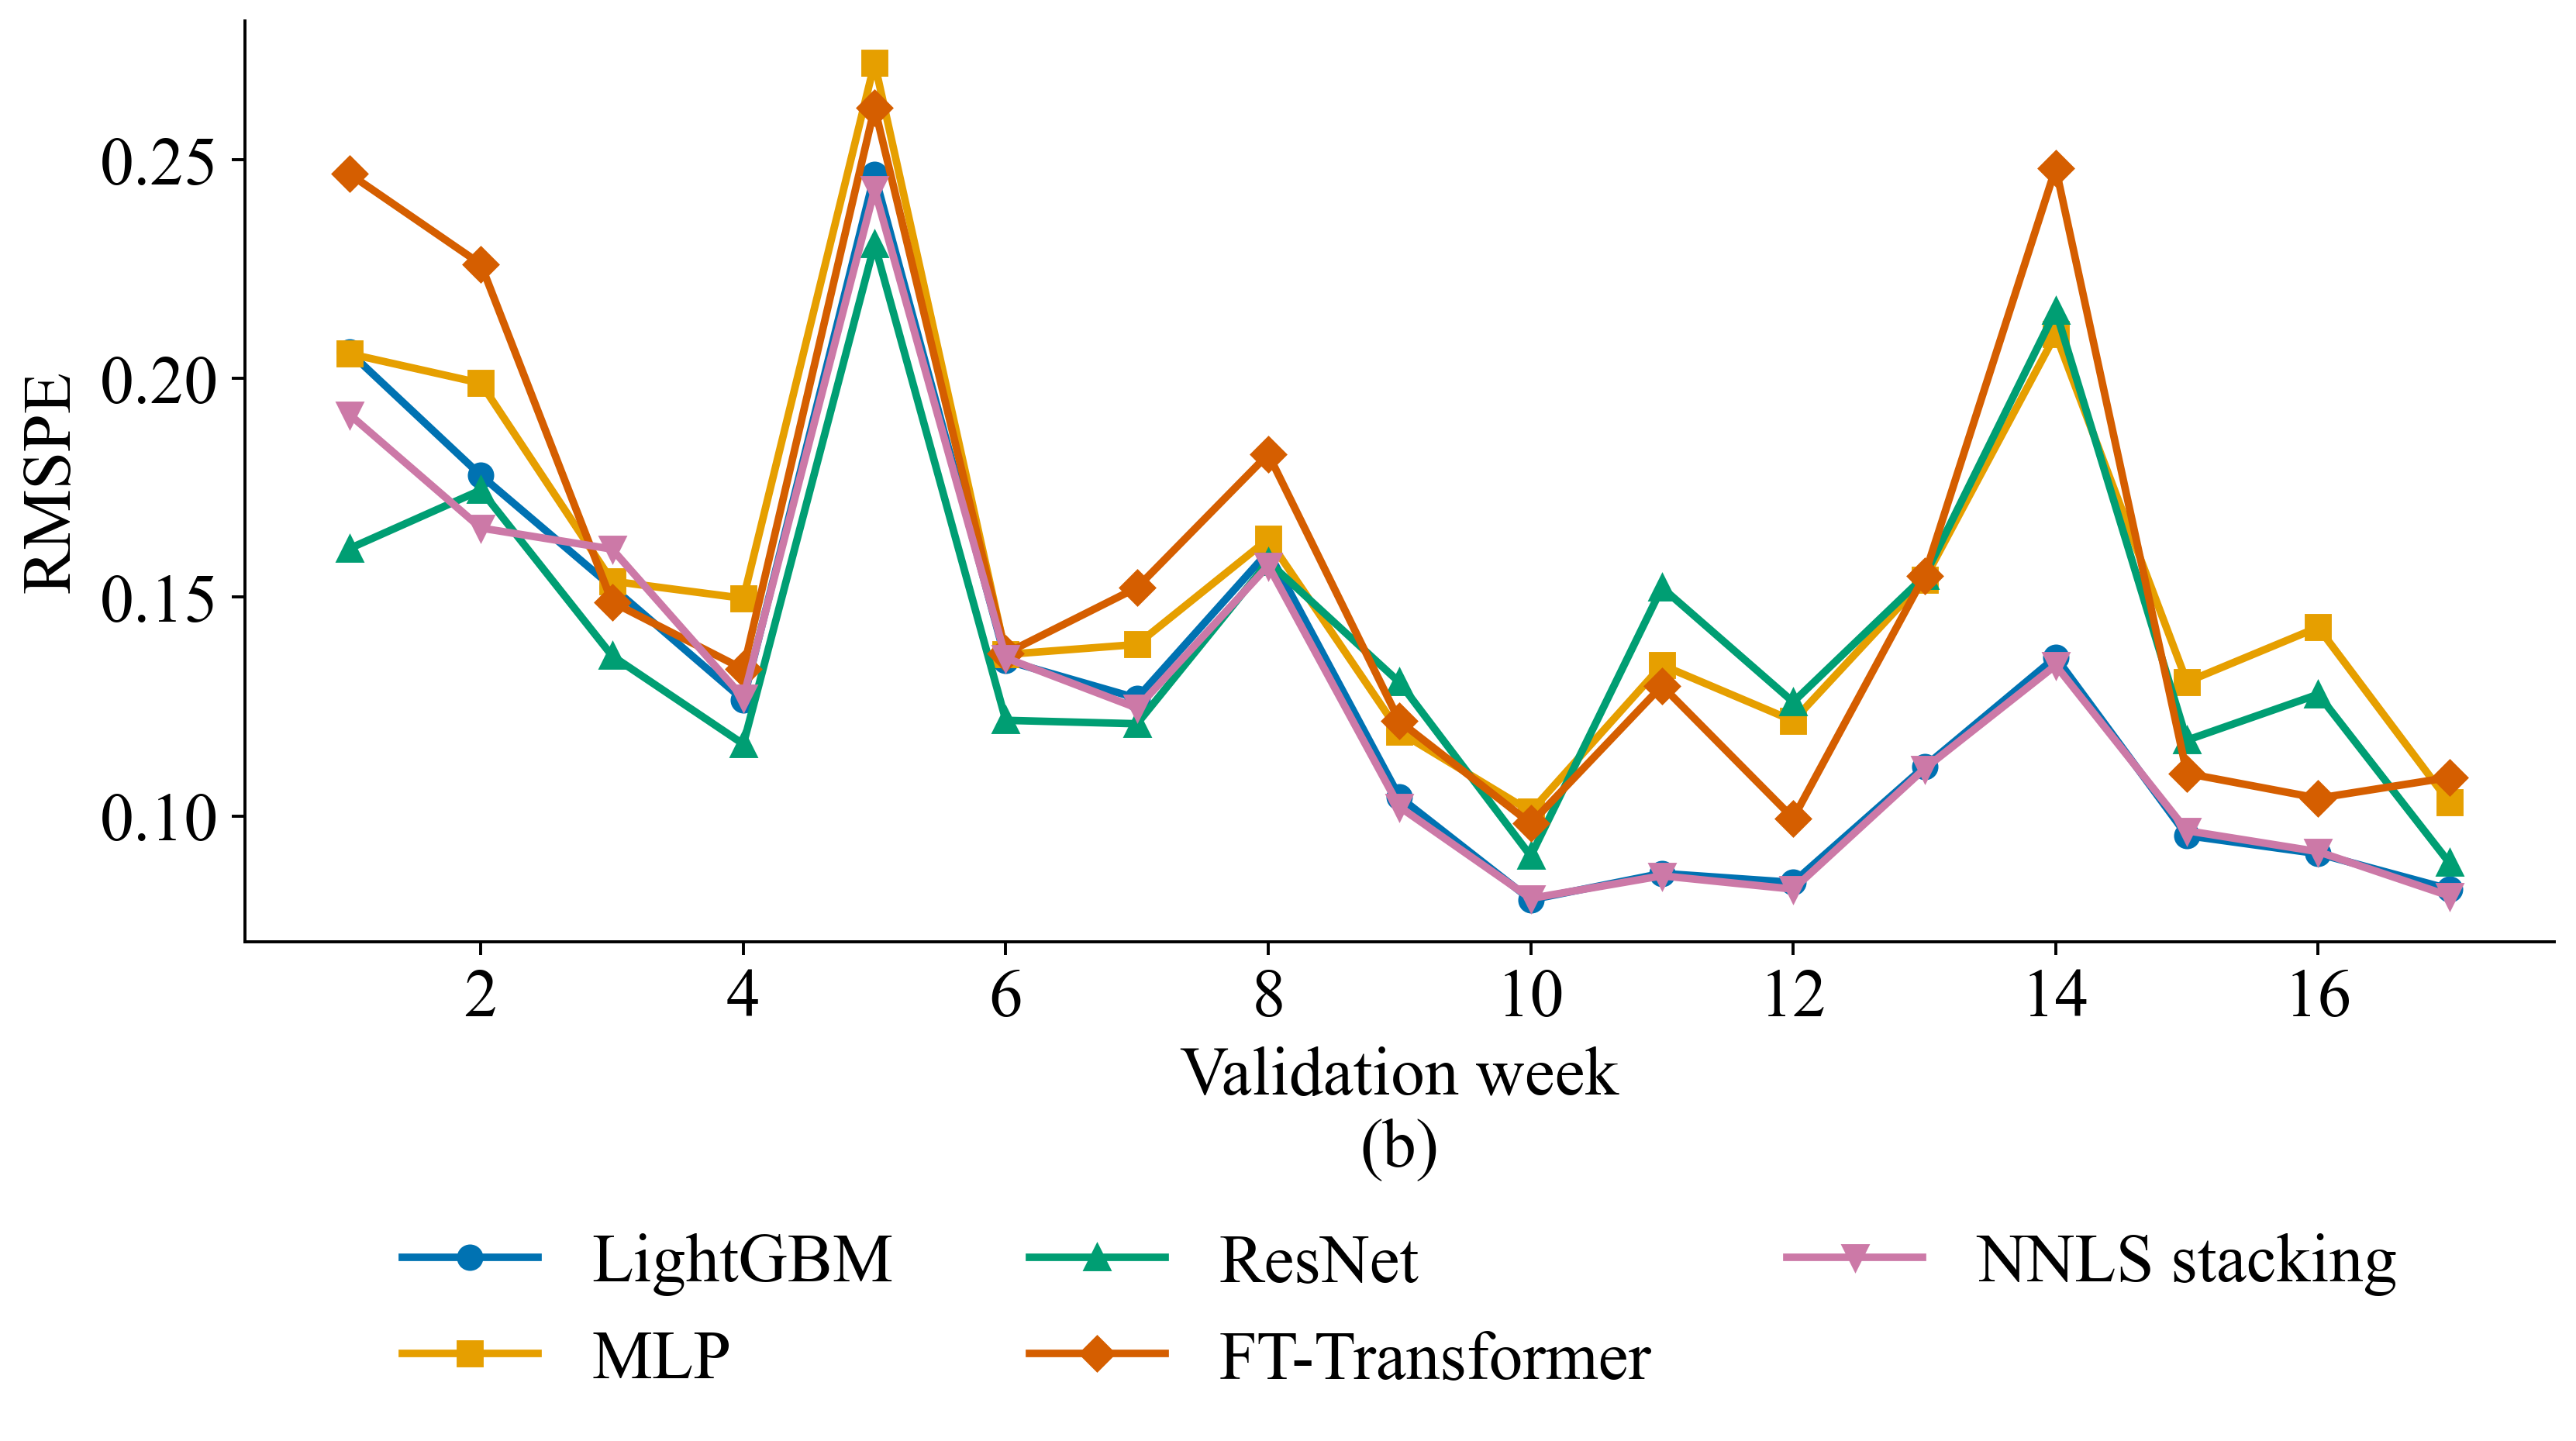

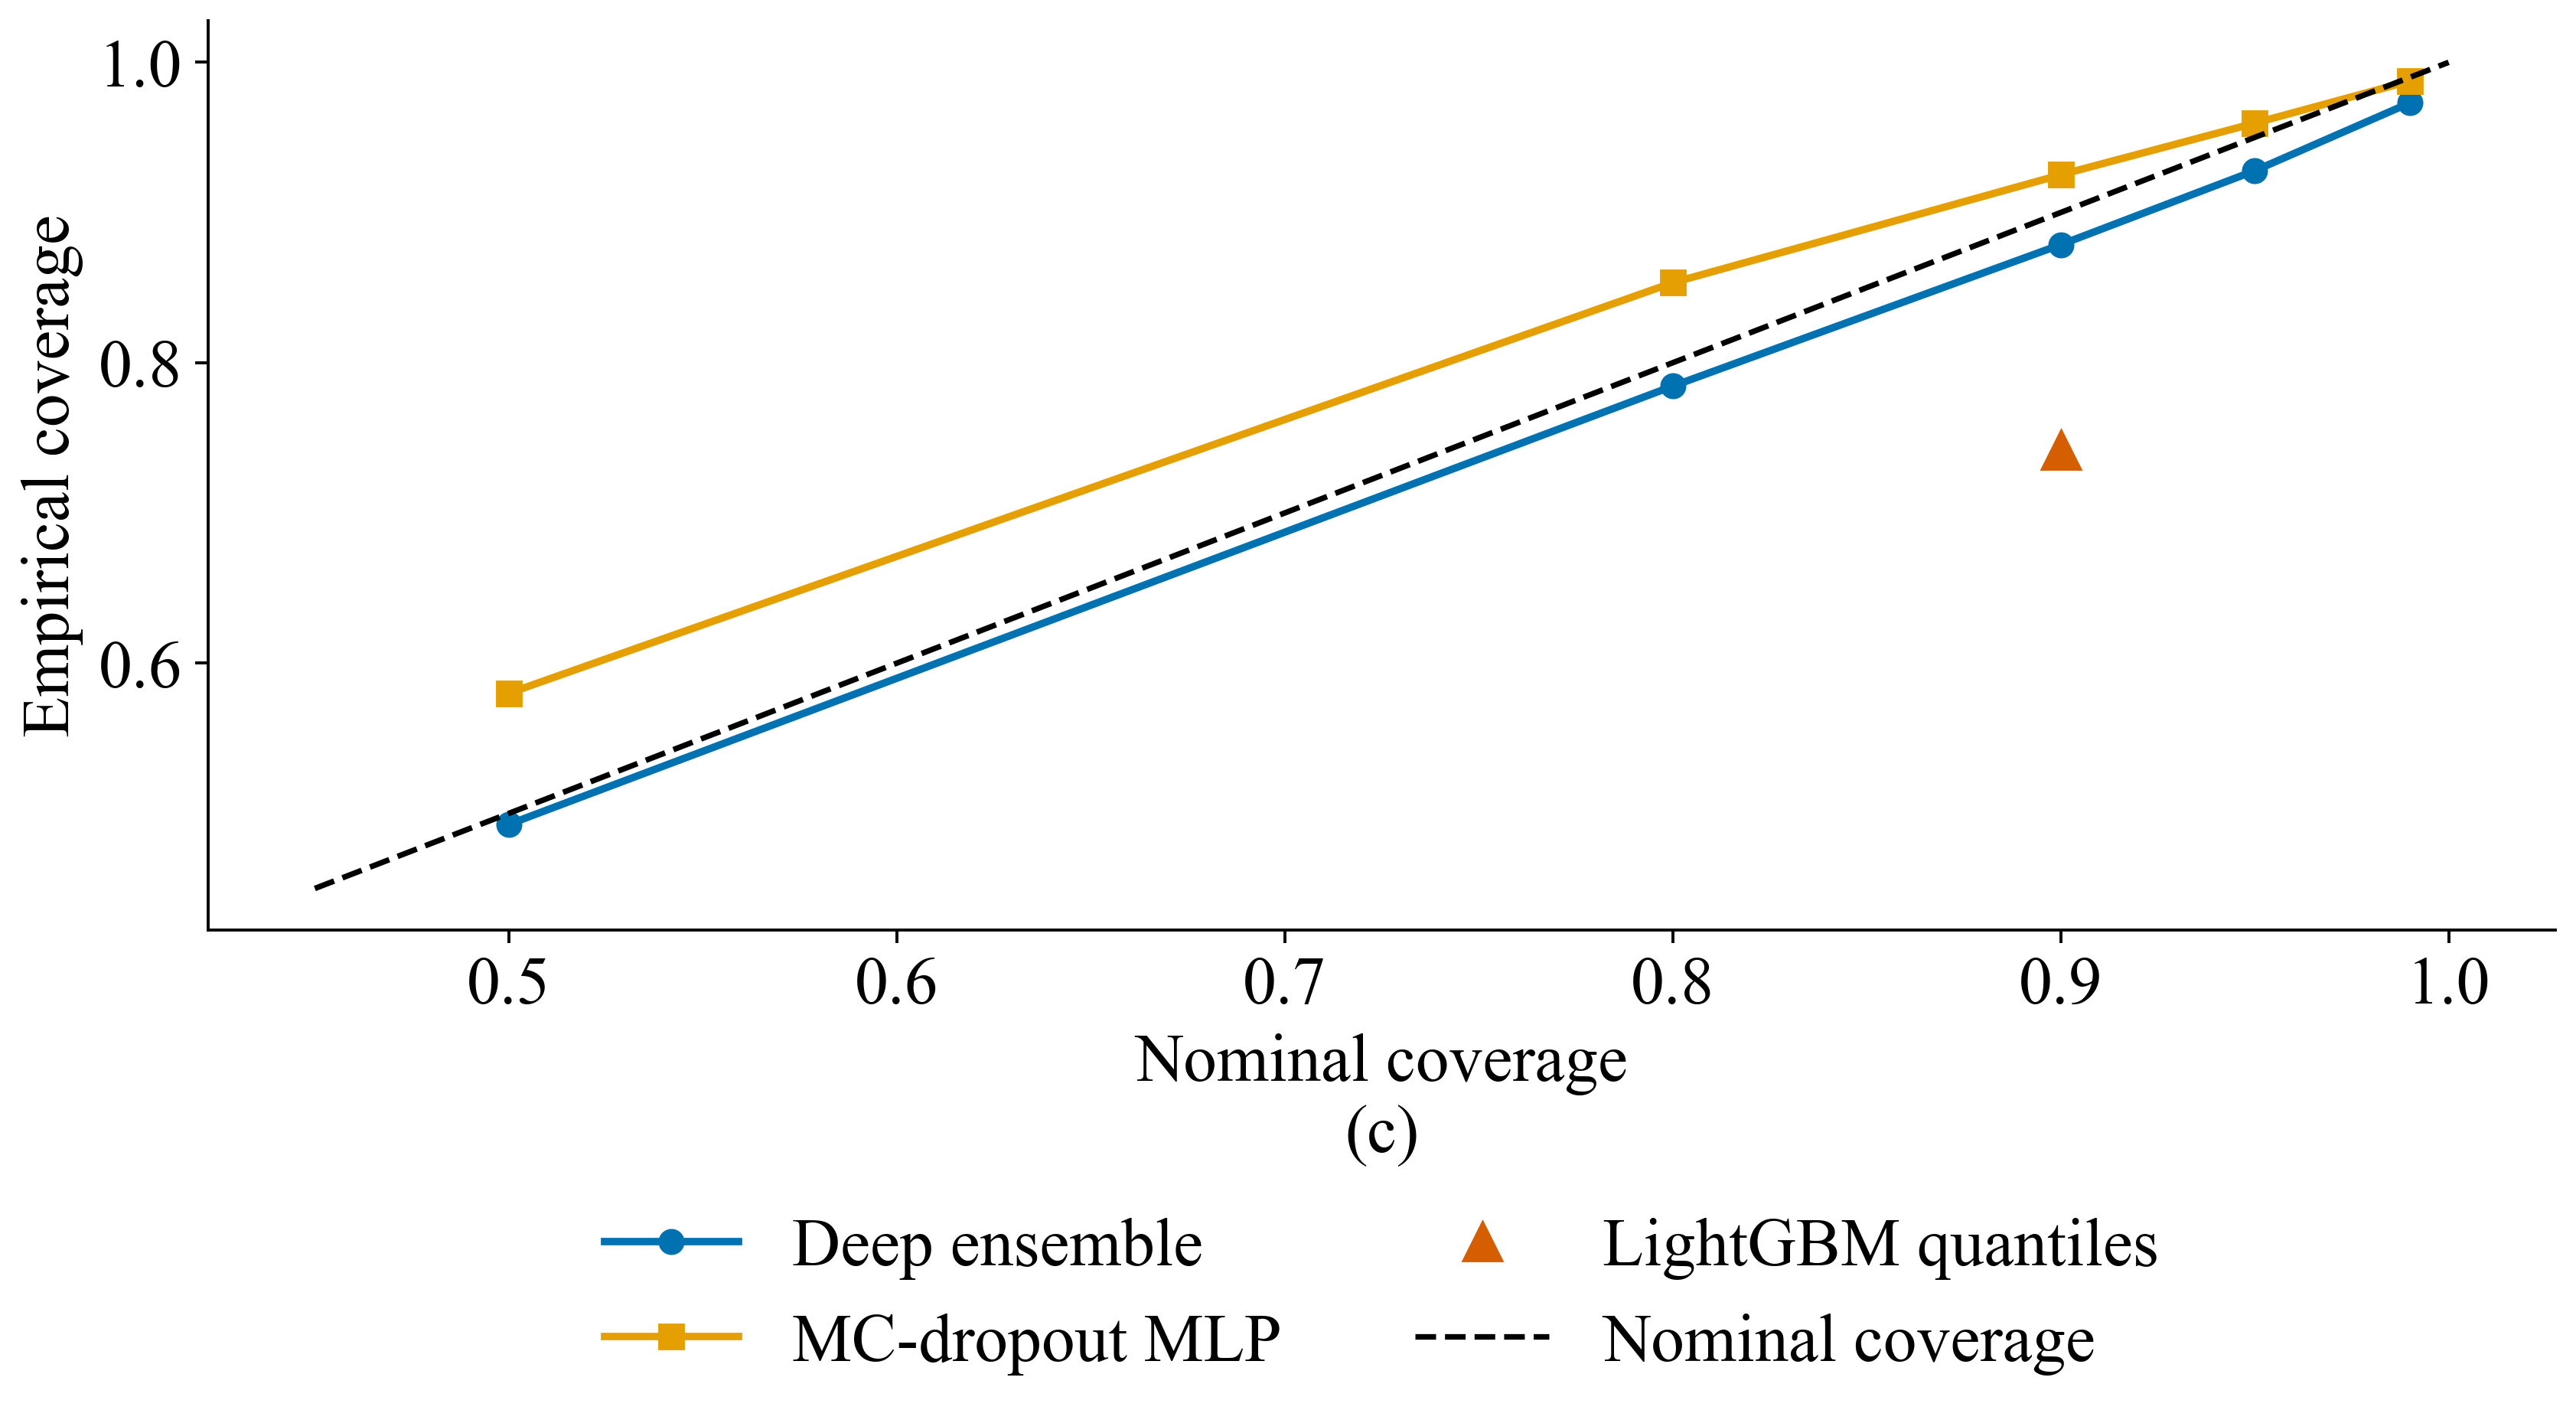

In [17]:
short = {
    "NNLS stacking (rolling, 3 boosters)": "NNLS stacking",
    "Deep ensemble (5 x MLP, Gaussian NLL)": "Deep ensemble",
    "LightGBM (quantile 90% PI)": "LightGBM quantiles",
}
chosen = [
    "LightGBM",
    "MLP",
    "ResNet",
    "FT-Transformer",
    "NNLS stacking (rolling, 3 boosters)",
]
for panel, (table, xlabel) in enumerate(
    [(by_range, "Observed-sales quintile (Q1 lowest)"), (by_week, "Validation week")]
):
    fig, ax = plt.subplots(figsize=(10, 6))
    for j, m in enumerate(chosen):
        xx = range(1, 6) if panel == 0 else table.index
        ax.plot(
            xx,
            table[m].values,
            marker=["o", "s", "^", "D", "v"][j],
            color=PALETTE[j],
            lw=2,
            label=short.get(m, m),
        )
    ax.set_xlabel(xlabel + "\n(" + chr(97 + panel) + ")")
    ax.set_ylabel("RMSPE")
    if panel == 0:
        ax.set_yscale("log")
        ax.set_xticks(range(1, 6))
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
    fig.tight_layout()
    name = "fig4_2_comparative_diagnostics" + chr(97 + panel)
    save_fig(fig, name)
    show_fig(name)
fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(["Deep ensemble (5 x MLP, Gaussian NLL)", "MC-dropout MLP"]):
    r_ = reliability.loc[name]
    ax.plot(
        r_.index,
        r_["empirical coverage"],
        marker=["o", "s"][i],
        lw=2,
        color=PALETTE[i],
        label=short.get(name, name),
    )
ax.plot(
    [0.9],
    [reliability.loc[("LightGBM (quantile 90% PI)", 0.9), "empirical coverage"]],
    "^",
    ms=10,
    color=PALETTE[3],
    label="LightGBM quantiles",
)
ax.plot([0.45, 1], [0.45, 1], "--", color="black", label="Nominal coverage")
ax.set_xlabel("Nominal coverage\n(c)")
ax.set_ylabel("Empirical coverage")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
fig.tight_layout()
save_fig(fig, "fig4_2_comparative_diagnosticsc")
show_fig("fig4_2_comparative_diagnosticsc")
# Week winners are reported in the regime table; no duplicate bar chart.

by_range.to_csv(TABLES / "fig4_2_error_by_sales_quintile_numeric.csv")
by_week.to_csv(TABLES / "fig4_2_error_by_week_numeric.csv")
reliability.to_csv(TABLES / "fig4_2_interval_reliability_numeric.csv")


## 9. Computational cost

In [18]:
cost = pd.DataFrame(
    {
        m: {
            "search seconds": timing[m][0],
            "final fit seconds": timing[m][1],
            "predict seconds (valid)": timing[m][2],
            "parameters": n_params[m],
            "stored model (MiB)": os.path.getsize(
                RUNS
                / f"{NB}_{m.replace(' ', '_').replace('/', '-')}_valid"
                / "model.pkl"
            )
            / 2**20,
        }
        for m in timing
    }
).T
save_table(
    cost,
    "tab4_11_computational_cost",
    f"Computational cost of the modern competitors on Apple M1 Pro (MPS for neural batches when available; {N_JOBS} CPU threads): random-search time, final fit, prediction time on the validation rows, number of parameters, gzip-compressed size in MiB. Shared-machine wall-clock times are descriptive and do not establish controlled speed advantages.",
    float_format="%.2f",
)

,search seconds,final fit seconds,predict seconds (valid),parameters,stored model (MiB)
MLP,123.3359,63.7176,0.3169,"160,009.0000",0.5710
ResNet,208.5680,119.7265,0.5563,"2,159,881.0000",7.6664
FT-Transformer,"1,224.4985",941.1396,4.3376,"76,993.0000",0.2793
"Deep ensemble (5 x MLP, Gaussian NLL)",0.0000,363.5574,2.8315,"801,330.0000",2.8497
MC-dropout MLP,0.0000,64.3729,28.9646,"160,009.0000",0.5710


## 10. Leaderboard after NB03 and NB04 and error correlation

In [19]:
reg = load_registry("valid", ["NB03", "NB04"]).set_index("model")
board = reg[
    [
        "notebook",
        "RMSPE",
        "RMSPE_lo",
        "RMSPE_hi",
        "RMSE",
        "MAE",
        "sMAPE",
        "R2",
        "PICP90",
        "MPIW90_rel",
        "fit_seconds",
    ]
].sort_values("RMSPE")
save_table(
    board,
    "tab4_12_leaderboard_nb03_nb04",
    "Validation leaderboard after baselines and modern competitors (Jan–Apr 2015); PICP90 and relative width only for models with intervals.",
)


,notebook,RMSPE,RMSPE_lo,RMSPE_hi,RMSE,MAE,sMAPE,R2,PICP90,MPIW90_rel,fit_seconds
model,,,,,,,,,,,
Uniform average (3 boosters),NB04,0.1350,0.1188,0.1598,853.8008,583.7067,0.0853,0.9178,n/a,n/a,0.0000
"NNLS stacking (rolling, 3 boosters)",NB04,0.1360,0.1201,0.1601,861.7475,589.5550,0.0861,0.9163,n/a,n/a,0.0000
CatBoost,NB03,0.1381,0.1217,0.1645,892.3209,605.6798,0.0885,0.9102,n/a,n/a,210.4220
LightGBM,NB03,0.1383,0.1225,0.1617,879.9008,602.0649,0.0876,0.9127,n/a,n/a,92.2878
LightGBM (quantile 90% PI),NB03,0.1383,0.1225,0.1617,879.9008,602.0649,0.0876,0.9127,0.7421,0.2633,223.6849
XGBoost,NB03,0.1385,0.1231,0.1615,865.7796,592.9647,0.0868,0.9155,n/a,n/a,41.7530
ResNet,NB04,0.1474,0.1343,0.1673,"1,079.0184",723.6494,0.1036,0.8687,n/a,n/a,119.7265
MC-dropout MLP,NB04,0.1589,0.1429,0.1835,"1,015.7238",696.6950,0.1016,0.8837,0.9251,0.4938,64.3729
MLP,NB04,0.1611,0.1440,0.1888,"1,038.6668",707.3220,0.1035,0.8784,n/a,n/a,63.7176


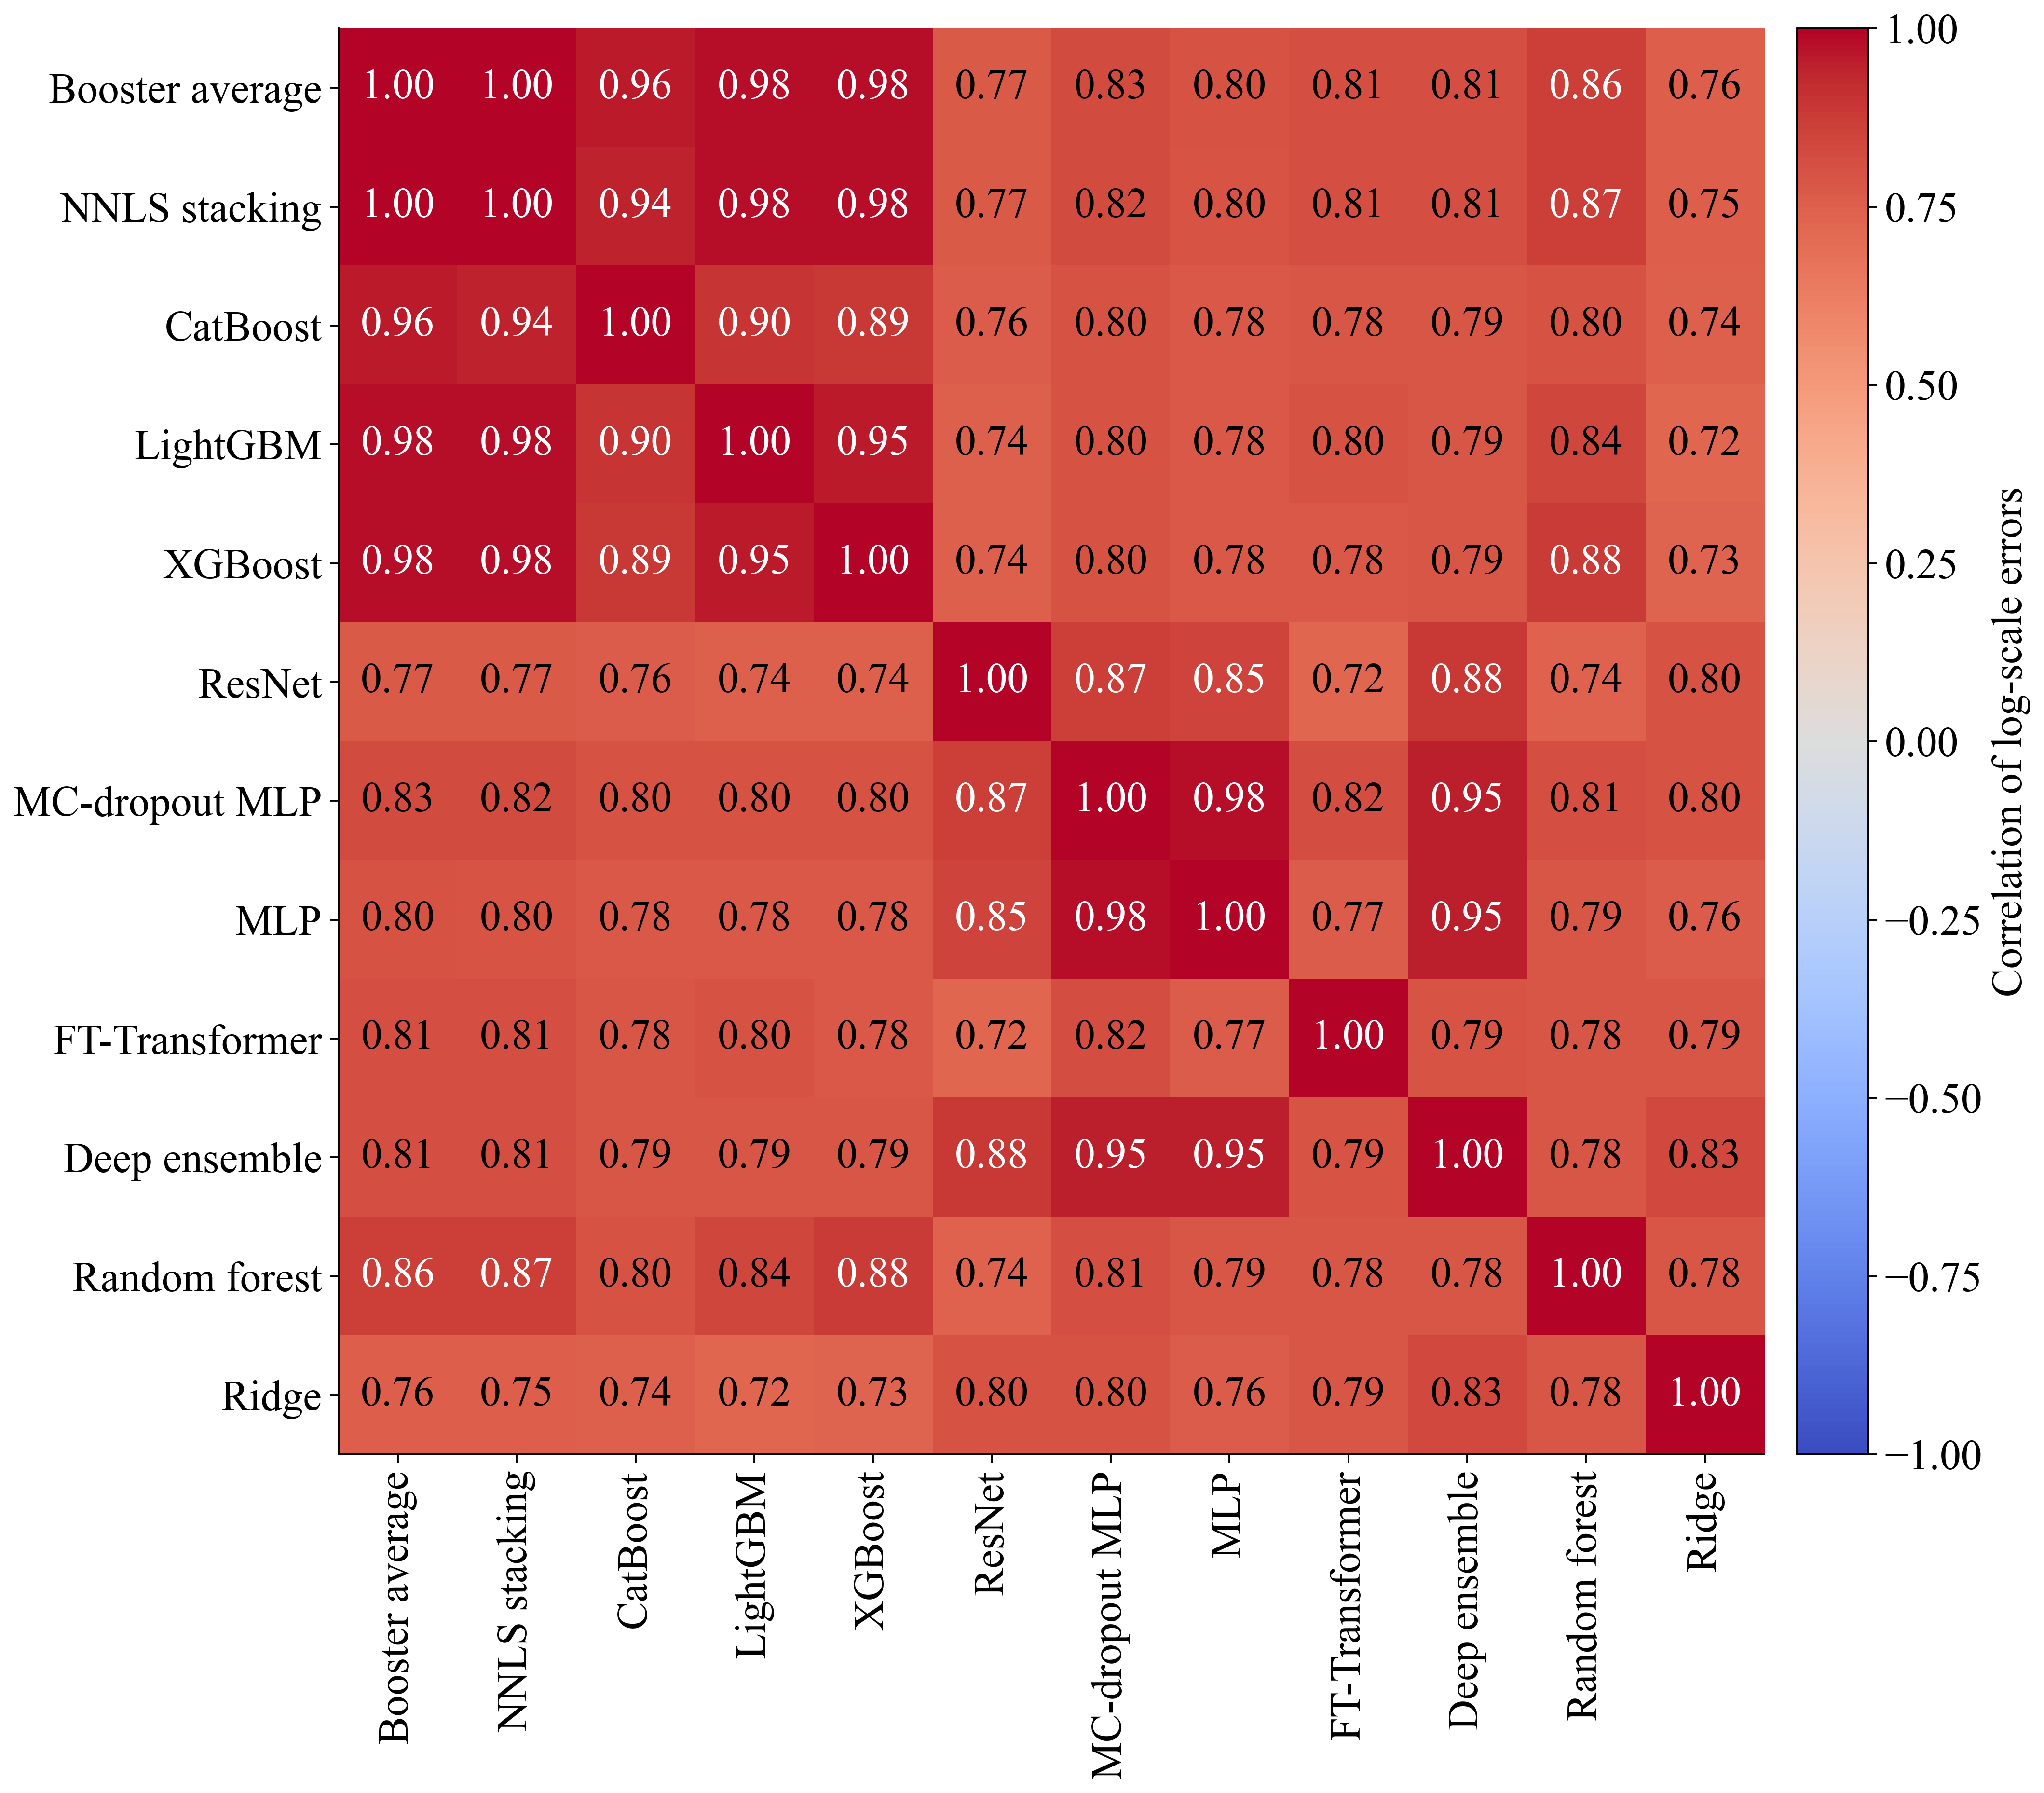

In [20]:
def contrast_text(value, image):
    rgb = np.asarray(image.cmap(image.norm(value))[:3])
    linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    luminance = float(linear @ np.array([0.2126, 0.7152, 0.0722]))
    return "black" if luminance > 0.179 else "white"


names = [n for n in board.index if not n.startswith("Naive") and "quantile" not in n]
E = pd.DataFrame(
    {
        n: np.log(
            pd.read_csv(
                RUNS
                / f"{board.loc[n, 'notebook']}_{n.replace(' ', '_').replace('/', '-')}_valid"
                / "predictions.csv"
            )["pred"].values
        )
        - y_va
        for n in names
    }
)
C = E.corr()
short_names = [
    short.get(x, x)
    .replace(" regression", "")
    .replace("Uniform average (3 boosters)", "Booster average")
    for x in names
]
fig, ax = plt.subplots(figsize=(12.5, 11))
im = ax.imshow(C.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(short_names, rotation=90)
ax.set_yticklabels(short_names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(
            j,
            i,
            f"{0.0 if abs(C.values[i,j])<0.005 else C.values[i,j]:.2f}".replace(
                "-", "−"
            ),
            ha="center",
            va="center",
            fontsize=18,
            color=contrast_text(C.values[i, j], im),
        )
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label("Correlation of log-scale errors")
fig.tight_layout()
save_fig(fig, "fig4_4_error_correlation")
_ = save_table(
    C,
    "tab4_13_error_correlation",
    "Pearson correlation of validation log-scale errors between models.",
    float_format="%.3f",
)
show_fig("fig4_4_error_correlation", width=1200)


In [22]:
latest_path = MANIFESTS / "latest_runs.json"
latest = json.loads(latest_path.read_text()) if latest_path.exists() else {}
latest["NB04"] = RUN_ID
latest_path.write_text(json.dumps(latest, indent=2));

# Part B · UCI Sales Transactions Weekly

## Neural competitors on the causal weekly features

In [1]:
# NB04_SETUP: packages, paths and helpers (same conventions as notebook 03)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'uci'
for sub in ['Artifacts', 'Manifests']:(BASE/sub).mkdir(parents=True,exist_ok=True)
RUN_ID='NB04_UCI_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

import torch,torch.nn as nn,torch.nn.functional as F
from sklearn.preprocessing import QuantileTransformer
torch.set_num_threads(4);DEVICE=torch.device('cpu')
PLAN=json.loads((BASE/'Configs/baseline_search.json').read_text());FM=json.loads((BASE/'Manifests/feature_manifest.json').read_text());BM=json.loads((BASE/'Manifests/baseline_manifest.json').read_text())
NB03_OUT=BASE/'Artifacts'/BM['run_id']

### Common rows, fold-local preprocessing and the inner early-stopping window

In [2]:
# NB04_DATA: exact common rows, NB03 preprocessing and the inner windows
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet').sort_values(['week','Product_Code']).reset_index(drop=True)
panel=pd.read_parquet(BASE/'Data/core_permitted_long.parquet');wide=panel.pivot(index='Product_Code',columns='week',values='quantity').sort_index()
assert rows.Product_Code.nunique()==729 and rows.week.between(6,38).all() and rows.row_id.is_unique and panel.week.max()==38
FEATURES=FM['features'];COUNT=FM['count_features'];MISSING=FM['missing_indicator_features'];NAMES=FEATURES+[f'{x}_missing' for x in MISSING]
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();assert (a[COUNT].ge(0)|a[COUNT].isna()).all().all();a[COUNT]=np.log1p(a[COUNT]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();assert self.median.notna().all()
        b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);self.fit_row_ids=frame.row_id.tolist();return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING:z[k+'_missing']=a[k].isna().astype(float)
        assert np.isfinite(z.to_numpy()).all();return z[NAMES]
    def parameters(self):return {'features':FEATURES,'median':self.median.to_dict(),'scale':self.scale.to_dict(),'fit_row_ids':self.fit_row_ids}
STAGES={'F0':(14,(16,18)),'F1':(18,(20,23)),'F2':(22,(24,27)),'Initial':(26,(28,38))}
NET_EPOCHS={'max_epochs':60,'patience':8,'hold_out_weeks':4,'batch_size':128}
DATA={};PREP={}
for stage,(last,bounds) in STAGES.items():
    tr=rows[rows.week.between(6,last)].copy();ev=rows[rows.week.between(*bounds)].copy();p=FoldPreprocessor().fit(tr)
    assert tr.week.max()<=ev.week.min()-2 and set(tr.row_id).isdisjoint(ev.row_id)
    inner=tr.week>last-NET_EPOCHS['hold_out_weeks'];fit=~inner
    PREP[stage]=p;DATA[stage]={'train':tr,'eval':ev,'X':p.transform(tr),'Xe':p.transform(ev),'y':tr.quantity.to_numpy(dtype=float),'fit':fit.to_numpy(),'inner':inner.to_numpy()}
    dump(OUT/f'preprocessor_{stage}.json',p.parameters())
DEV=DATA['Initial']['eval'];CAL=rows[rows.week.between(20,26)].copy()
table(pd.DataFrame([{'Stage':k,'Latest fit label':v[0],'Network fit weeks':f'W6–W{v[0]-NET_EPOCHS["hold_out_weeks"]}','Inner window':f'W{v[0]-NET_EPOCHS["hold_out_weeks"]+1}–W{v[0]}','Forecast weeks':f'W{v[1][0]}–W{v[1][1]}','Network fit rows':int(DATA[k]['fit'].sum()),'Inner rows':int(DATA[k]['inner'].sum()),'Forecast rows':len(DATA[k]['eval'])} for k,v in STAGES.items()]),'nested_timeline')
print('Processed predictors',len(NAMES),'| epoch budget',NET_EPOCHS)

,Stage,Latest fit label,Network fit weeks,Inner window,Forecast weeks,Network fit rows,Inner rows,Forecast rows
0,F0,14,W6–W10,W11–W14,W16–W18,3645,2916,2187
1,F1,18,W6–W14,W15–W18,W20–W23,6561,2916,2916
2,F2,22,W6–W18,W19–W22,W24–W27,9477,2916,2916
3,Initial,26,W6–W22,W23–W26,W28–W38,12393,2916,8019


Processed predictors 36 | epoch budget {'max_epochs': 60, 'patience': 8, 'hold_out_weeks': 4, 'batch_size': 128}


### Network definitions and the fitting recipe

In [3]:
# NB04_NETWORKS: NB04 architectures without categorical inputs, quantile-normal inputs, inner early stopping
N_NUM=len(NAMES);CARD=[];NUM_POS=[i for i,c in enumerate(NAMES) if not c.endswith('_missing')]
class Embeds(nn.Module):
    def __init__(self,card,d):
        super().__init__();self.embs=nn.ModuleList([nn.Embedding(c,d) for c in card])
    def forward(self,xc):return torch.cat([e(xc[:,i]) for i,e in enumerate(self.embs)],1) if len(self.embs) else xc.new_zeros((xc.shape[0],0),dtype=torch.float32)
class MLP(nn.Module):
    def __init__(self,width=512,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);layers,d_in=[],N_NUM+d_emb*len(CARD)
        for _ in range(depth):layers+=[nn.Linear(d_in,width),nn.ReLU(),nn.Dropout(dropout)];d_in=width
        self.body=nn.Sequential(*layers);self.head=nn.Linear(d_in,out)
    def forward(self,xn,xc):return self.head(self.body(torch.cat([xn,self.emb(xc)],1)))
class ResBlock(nn.Module):
    def __init__(self,d,hidden,dropout):
        super().__init__();self.norm=nn.BatchNorm1d(d);self.l1=nn.Linear(d,hidden);self.l2=nn.Linear(hidden,d);self.dp=nn.Dropout(dropout)
    def forward(self,x):return x+self.l2(self.dp(F.relu(self.l1(self.norm(x)))))
class ResNet(nn.Module):
    def __init__(self,d=256,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);self.inp=nn.Linear(N_NUM+d_emb*len(CARD),d);self.blocks=nn.Sequential(*[ResBlock(d,2*d,dropout) for _ in range(depth)]);self.norm=nn.BatchNorm1d(d);self.head=nn.Linear(d,out)
    def forward(self,xn,xc):return self.head(F.relu(self.norm(self.blocks(self.inp(torch.cat([xn,self.emb(xc)],1))))))
NETS={'MLP':lambda c:MLP(c['width'],c['depth'],c['dropout']),'ResNet':lambda c:ResNet(c['d'],c['depth'],c['dropout'])}
SPACES={'MLP':{'width':[256,512,1024],'depth':[2,3,4],'dropout':(0.0,0.3,'float'),'lr':(1e-4,3e-3,'log'),'weight_decay':(1e-6,1e-3,'log')},
        'ResNet':{'d':[128,256,512],'depth':[2,3,4],'dropout':(0.0,0.3,'float'),'lr':(1e-4,3e-3,'log'),'weight_decay':(1e-6,1e-3,'log')}}
N_TRIALS=8
def draw_configurations(space,n=N_TRIALS,seed=SEED):
    """The NB04 sampler of the main chain: one generator per family, lists by index, ranges uniform or log-uniform."""
    g=np.random.default_rng(seed);out=[]
    for _ in range(n):
        cfg={}
        for k,v in space.items():
            if isinstance(v,list):cfg[k]=v[g.integers(len(v))]
            else:
                lo,hi,kind=v;cfg[k]=float(np.exp(g.uniform(np.log(lo),np.log(hi)))) if kind=='log' else (int(g.integers(lo,hi+1)) if kind=='int' else float(g.uniform(lo,hi)))
        out.append({k:(int(v) if isinstance(v,(np.integer,int)) else float(v)) for k,v in cfg.items()})
    return out
GRID={name:draw_configurations(space) for name,space in SPACES.items()}
class NetInputs:
    """Quantile-normal map of the numeric processed columns, fitted on the fitting rows; missing indicators pass unchanged."""
    def fit(self,X):self.qt=QuantileTransformer(n_quantiles=min(1000,len(X)),output_distribution='normal',subsample=200_000,random_state=SEED).fit(X.to_numpy(float)[:,NUM_POS]);return self
    def transform(self,X):
        Z=X.to_numpy(np.float32).copy();Z[:,NUM_POS]=self.qt.transform(Z[:,NUM_POS].astype(float)).astype(np.float32);assert np.isfinite(Z).all();return torch.tensor(Z),torch.zeros((len(Z),0),dtype=torch.int64)
@torch.no_grad()
def predict_net(net,Xn,Xc,mu_sd,bs=2048):
    net.eval();out=torch.cat([net(Xn[i:i+bs],Xc[i:i+bs])[:,0] for i in range(0,len(Xn),bs)]).numpy()
    return np.maximum(0.,np.expm1(out*mu_sd[1]+mu_sd[0]))
def fit_net_inner(name,cfg,stage,seed):
    """Fit one network on the fitting rows of a stage; epochs chosen by early stopping on the inner window; returns the network, its input map, the target moments, the selected epoch and the per-epoch history."""
    d=DATA[stage];fit,inner=d['fit'],d['inner'];Xf_df,Xi_df=d['X'][fit],d['X'][inner];yq=d['y']
    ni=NetInputs().fit(Xf_df);Xf,Cf=ni.transform(Xf_df);Xi,Ci=ni.transform(Xi_df)
    lf=np.log1p(yq[fit]);mu_sd=(float(lf.mean()),float(lf.std()));yf=torch.tensor(((lf-mu_sd[0])/mu_sd[1]).astype(np.float32));yi=yq[inner]
    torch.manual_seed(seed);net=NETS[name](cfg).to(DEVICE);opt=torch.optim.AdamW(net.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay'])
    n,bs=len(yf),NET_EPOCHS['batch_size'];best,best_state,best_epoch,bad,hist=np.inf,None,0,0,[]
    for ep in range(NET_EPOCHS['max_epochs']):
        net.train();perm=torch.randperm(n);tl=0.
        for i in range(0,n,bs):
            j=perm[i:i+bs]
            if len(j)<2:continue
            opt.zero_grad();out=net(Xf[j],Cf[j]);loss=F.mse_loss(out[:,0],yf[j]);loss.backward();nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step();tl+=float(loss.detach())*len(j)
        score=rmspe(yi,predict_net(net,Xi,Ci,mu_sd));hist.append({'epoch':ep+1,'train_loss':tl/n,'inner_RMSPE':score})
        if score<best-1e-5:best,best_state,best_epoch,bad=score,{k:v.clone() for k,v in net.state_dict().items()},ep+1,0
        else:
            bad+=1
            if bad>=NET_EPOCHS['patience']:break
    net.load_state_dict(best_state);net.eval()
    return net,ni,mu_sd,best_epoch,best,pd.DataFrame(hist)
budget=pd.DataFrame([{'Model':m,'Configurations':len(GRID[m]),'Search seed':SEED,'Final seeds':len(PLAN['seeds']),'Epoch budget':NET_EPOCHS['max_epochs'],'Patience':NET_EPOCHS['patience'],'Batch size':NET_EPOCHS['batch_size'],'Parameters (first configuration)':sum(p.numel() for p in NETS[m](GRID[m][0]).parameters())} for m in NETS])
table(budget,'fixed_network_budget')
for m in NETS:table(pd.DataFrame(GRID[m]).rename_axis('Configuration').reset_index(),f'{m.lower().replace("-","_")}_configurations')

,Model,Configurations,Search seed,Final seeds,Epoch budget,Patience,Batch size,Parameters (first configuration)
0,MLP,8,2026,5,60,8,128,1088513
1,ResNet,8,2026,5,60,8,128,2122753


,Configuration,width,depth,dropout,lr,weight_decay
0,0,1024,2,0.19197,0.00049,0.00001
1,1,512,3,0.23716,0.00217,0.00000
2,2,1024,3,0.08949,0.00268,0.00057
3,3,256,3,0.22582,0.00058,0.00030
4,4,512,3,0.10164,0.00026,0.00000
5,5,1024,3,0.12927,0.00095,0.00000
6,6,512,3,0.10955,0.00019,0.00006
7,7,256,3,0.09000,0.00020,0.00042


,Configuration,d,depth,dropout,lr,weight_decay
0,0,512,2,0.19197,0.00049,0.00001
1,1,256,3,0.23716,0.00217,0.00000
2,2,512,3,0.08949,0.00268,0.00057
3,3,128,3,0.22582,0.00058,0.00030
4,4,256,3,0.10164,0.00026,0.00000
5,5,512,3,0.12927,0.00095,0.00000
6,6,256,3,0.10955,0.00019,0.00006
7,7,128,3,0.09000,0.00020,0.00042


### Search engine: the NB03 chronology for networks

In [4]:
# NB04_ENGINE: chronology-respecting configuration selection and real seed fits
SEARCH={};NESTED={};PREDICTIONS={};CONFIGS={};FROZEN_MODELS={};RESOURCES=[];TRIALS=[];CURVES={};EPOCHS=[]
def fit_predict(name,cfg,seed,stage,tag):
    started=time.perf_counter();net,ni,mu_sd,ep,inner_score,hist=fit_net_inner(name,cfg,stage,seed);fit_seconds=time.perf_counter()-started
    t1=time.perf_counter();point=predict_net(net,*ni.transform(DATA[stage]['Xe']),mu_sd);prediction_seconds=time.perf_counter()-t1
    assert np.isfinite(point).all() and (point>=0).all()
    RESOURCES.append({'Model':name,'Tag':tag,'Stage':stage,'Seed':seed,'Actual learner fit':1,'Fit rows':int(DATA[stage]['fit'].sum()),'Forecast rows':len(point),'Epochs run':len(hist),'Selected epoch':ep,'Inner RMSPE':inner_score,'Fit seconds':fit_seconds,'Prediction seconds':prediction_seconds,'Process peak MiB':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**20})
    CURVES[tag]=hist.to_dict('list');EPOCHS.append({'Model':name,'Tag':tag,'Stage':stage,'Seed':seed,'Selected epoch':ep,'Epochs run':len(hist),'Inner-window RMSPE':inner_score})
    return point,{'state_dict':{k:v.cpu() for k,v in net.state_dict().items()},'configuration':cfg,'inputs':ni,'mu_sd':mu_sd,'selected_epoch':ep}
def score_candidate(name,index,stages,latest):
    ys=[];ps=[]
    for st in stages:
        ev=DATA[st]['eval'];mask=ev.week.to_numpy()<=latest
        ys.append(ev.quantity.to_numpy()[mask]);ps.append(SEARCH[(name,index,st)][mask])
    return metrics(np.concatenate(ys),np.concatenate(ps))
def select_config(name,stages,latest):
    choices=[]
    for j in range(len(GRID[name])):
        m=score_candidate(name,j,stages,latest);choices.append((m['RMSPE'],m['MAE'],j))
    return min(choices)[2]
MODEL_ORDER=list(NETS)
def run_family(name):
    progress=display(pd.DataFrame([{'Model':name,'Completed candidate paths':0,'Total candidate paths':3*len(GRID[name])}]),display_id=True)
    for j,cfg in enumerate(GRID[name]):
        for stage in ['F0','F1','F2']:
            p,_=fit_predict(name,cfg,SEED,stage,f'{name}|search{j}|{stage}');SEARCH[(name,j,stage)]=p
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*(j+1),'Total candidate paths':3*len(GRID[name]),'Latest inner RMSPE':RESOURCES[-1]['Inner RMSPE'],'Latest selected epoch':RESOURCES[-1]['Selected epoch']}]))
    nested_choice={'F1':select_config(name,['F0'],18),'F2':select_config(name,['F0','F1'],22)}
    blocks=[]
    for st in ['F1','F2']:
        ev=DATA[st]['eval'];keep=ev.week<=26;b=ev.loc[keep,['row_id','Product_Code','week','quantity']].copy()
        b['prediction']=SEARCH[(name,nested_choice[st],st)][keep];b['configuration']=nested_choice[st];b['model']=name;blocks.append(b)
    NESTED[name]=pd.concat(blocks,ignore_index=True);assert NESTED[name].row_id.tolist()==CAL.row_id.tolist()
    selected=select_config(name,['F1','F2'],26);cfg=GRID[name][selected]
    CONFIGS[name]={'selected_index':selected,'parameters':cfg,'nested_indices':nested_choice}
    for j in range(len(GRID[name])):
        m=score_candidate(name,j,['F1','F2'],26);TRIALS.append({'Model':name,'Configuration':j,'Selected':j==selected,**m})
    for seed in PLAN['seeds']:
        p,model=fit_predict(name,cfg,seed,'Initial',f'{name}|final|{seed}');PREDICTIONS[(name,seed)]=p
        if seed==SEED:FROZEN_MODELS[name]=model
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*len(GRID[name]),'Latest final seed':seed,'Selected epoch':model['selected_epoch']}]))
    table(pd.DataFrame([{'Model':name,'Selected configuration':selected,'Nested F1 configuration':nested_choice['F1'],'Nested F2 configuration':nested_choice['F2'],'Actual final fits':len(PLAN['seeds']),**{k:v for k,v in cfg.items()}}]),name.lower().replace('-','_')+'_selection')
    table(pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,SEED)])}]).drop(columns=['Positive_n','Zero_n','R2','sMAPE_pct']),name.lower().replace('-','_')+'_development')
    dump(OUT/'selected_configurations.json',CONFIGS);pd.DataFrame(RESOURCES).to_csv(OUT/'fit_resources.csv',index=False);dump(OUT/'training_curves.json',CURVES)
    np.savez_compressed(OUT/'search_predictions.npz',**{f'{MODEL_ORDER.index(k[0])}_{k[1]}_{k[2]}':v for k,v in SEARCH.items()})
    np.savez_compressed(OUT/'development_predictions.npz',**{f'{MODEL_ORDER.index(k[0])}_{k[1]}':v for k,v in PREDICTIONS.items()})
    pd.concat(NESTED.values(),ignore_index=True).to_parquet(OUT/'nested_oof.parquet',index=False)
    with gzip.open(OUT/'fitted_models.pkl.gz','wb') as f:cloudpickle.dump({'models':FROZEN_MODELS,'preprocessor':PREP['Initial'],'configurations':CONFIGS,'feature_names':NAMES,'net_epochs':NET_EPOCHS,'numeric_positions':NUM_POS},f)

### MLP

In [5]:
# NB04_MLP: actual search and seed fits
run_family('MLP')

,Model,Completed candidate paths,Latest final seed,Selected epoch
0,MLP,24,2030,8


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,width,depth,dropout,lr,weight_decay
0,MLP,1,5,1,5,512,3,0.23716,0.00217,0.00000


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,MLP,0.96747,4.37211,2.63594,0.67030


### ResNet

In [6]:
# NB04_RESNET: actual search and seed fits
run_family('ResNet')

,Model,Completed candidate paths,Latest final seed,Selected epoch
0,ResNet,24,2030,3


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,d,depth,dropout,lr,weight_decay
0,ResNet,2,2,2,5,512,3,0.08949,0.00268,0.00057


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,ResNet,0.57813,6.25262,3.28230,0.44250


### Development comparison with the NB03 families, seed stability and selected epochs

In [7]:
# NB04_COMPARISON: rankings against NB03 on identical rows, seed variation, epochs per origin
nb03_dev=pd.read_csv(NB03_OUT/'development_accuracy.csv');nb03_sup=pd.read_csv(NB03_OUT/'development_support.csv')
nb03=nb03_dev.merge(nb03_sup,on='Model');nb03['Notebook']='NB03'
nets=pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,SEED)])} for name in MODEL_ORDER]);nets['Notebook']='NB04'
comparison=pd.concat([nets,nb03],ignore_index=True).sort_values('RMSPE').reset_index(drop=True)
table(comparison[['Model','Notebook','RMSPE','RMSE','MAE','Zero_MAE']],'development_accuracy',['RMSPE','RMSE','MAE','Zero_MAE'])
table(comparison[['Model','Notebook','sMAPE_pct','R2','Positive_n','Zero_n']],'development_support')
seed_rows=[]
for name in MODEL_ORDER:
    values=[metrics(DEV.quantity,PREDICTIONS[(name,s)])['RMSPE'] for s in PLAN['seeds']]
    seed_rows.append({'Model':name,'Actual seeds':len(values),'Mean RMSPE':np.mean(values),'SD RMSPE':np.std(values,ddof=1),'Minimum RMSPE':np.min(values),'Maximum RMSPE':np.max(values)})
table(pd.DataFrame(seed_rows),'seed_stability')
trial_table=pd.DataFrame(TRIALS);trial_table.to_csv(OUT/'all_search_trials.csv',index=False)
table(trial_table[['Model','Configuration','Selected','RMSPE','RMSE','MAE','Zero_MAE']],'all_search_trials_summary')
ep=pd.DataFrame(EPOCHS)
sel=ep[ep.Tag.str.contains(r'\|final\|')|ep.apply(lambda r:r.Tag==f"{r.Model}|search{CONFIGS[r.Model]['nested_indices'].get(r.Stage,CONFIGS[r.Model]['selected_index'])}|{r.Stage}" if r.Stage in ('F1','F2') else (r.Tag==f"{r.Model}|search{CONFIGS[r.Model]['nested_indices']['F1']}|F0" if r.Stage=='F0' else False),axis=1)]
table(sel[['Model','Stage','Seed','Selected epoch','Epochs run','Inner-window RMSPE']].sort_values(['Model','Stage','Seed']).reset_index(drop=True),'network_epochs')
stability=[]
for name in MODEL_ORDER:
    for st in ['F1','F2']:
        ev=DATA[st]['eval'];keep=(ev.week<=26).to_numpy();stability.append({'Model':name,'Stage':st,'Configuration':CONFIGS[name]['nested_indices'][st],'Rows':int(keep.sum()),**{k:v for k,v in metrics(ev.quantity.to_numpy()[keep],SEARCH[(name,CONFIGS[name]['nested_indices'][st],st)][keep]).items() if k in ('RMSPE','RMSE','MAE','Zero_MAE')}})
    stability.append({'Model':name,'Stage':'Initial','Configuration':CONFIGS[name]['selected_index'],'Rows':len(DEV),**{k:v for k,v in metrics(DEV.quantity,PREDICTIONS[(name,SEED)]).items() if k in ('RMSPE','RMSE','MAE','Zero_MAE')}})
table(pd.DataFrame(stability),'inner_fold_stability')
resource_table=pd.DataFrame(RESOURCES).groupby('Model',sort=False).agg(actual_fits=('Actual learner fit','sum'),fit_seconds=('Fit seconds','sum'),prediction_seconds=('Prediction seconds','sum'),mean_selected_epoch=('Selected epoch','mean'),process_peak_MiB=('Process peak MiB','max')).reset_index()
table(resource_table,'resource_totals')
DEV[['row_id','Product_Code','week','quantity']].to_parquet(OUT/'development_rows.parquet',index=False)
for stage in ['F0','F1','F2']:DATA[stage]['eval'][['row_id','Product_Code','week','quantity']].to_parquet(OUT/f'search_rows_{stage}.parquet',index=False)

,Model,Notebook,RMSPE,RMSE,MAE,Zero_MAE
0,CatBoost,NB03,0.49364,4.52379,2.58150,0.38674
1,Positive-history action,NB03,0.49903,3.37799,2.20497,1.05097
2,XGBoost,NB03,0.50984,4.12230,2.42616,0.42171
3,LightGBM,NB03,0.53055,4.12949,2.37376,0.42608
4,Croston-SBA,NB03,0.56782,5.75900,3.22502,0.33835
5,ResNet,NB04,0.57813,6.25262,3.28230,0.44250
6,Random forest,NB03,0.76286,3.36043,2.05308,0.55597
7,Historical mean,NB03,0.84728,3.93524,2.36592,0.39547
8,Lag 2,NB03,0.87925,4.28464,2.53847,0.38249
9,MLP,NB04,0.96747,4.37211,2.63594,0.67030


,Model,Notebook,sMAPE_pct,R2,Positive_n,Zero_n
0,CatBoost,NB03,94.58067,0.81732,5598,2421
1,Positive-history action,NB03,82.61011,0.89814,5598,2421
2,XGBoost,NB03,93.38737,0.84831,5598,2421
3,LightGBM,NB03,91.27145,0.84778,5598,2421
4,Croston-SBA,NB03,98.69831,0.70394,5598,2421
5,ResNet,NB04,96.28500,0.65101,5598,2421
6,Random forest,NB03,87.54155,0.89920,5598,2421
7,Historical mean,NB03,88.27592,0.86176,5598,2421
8,Lag 2,NB03,53.43488,0.83612,5598,2421
9,MLP,NB04,90.54760,0.82936,5598,2421


,Model,Actual seeds,Mean RMSPE,SD RMSPE,Minimum RMSPE,Maximum RMSPE
0,MLP,5,0.74804,0.14025,0.64054,0.96747
1,ResNet,5,0.63896,0.05614,0.57813,0.70013


,Model,Configuration,Selected,RMSPE,RMSE,MAE,Zero_MAE
0,MLP,0,False,0.68065,5.43739,2.96430,0.33446
1,MLP,1,True,0.59606,5.42357,3.16794,0.46489
2,MLP,2,False,0.63758,5.40749,3.08514,0.31737
3,MLP,3,False,0.63798,5.12585,2.95279,0.36902
4,MLP,4,False,0.65006,4.71265,2.73683,0.23547
5,MLP,5,False,0.64581,5.83031,3.30386,0.28757
6,MLP,6,False,0.68569,4.47709,2.64189,0.39850
7,MLP,7,False,0.71133,4.98225,2.76102,0.29905
8,ResNet,0,False,0.62639,4.71674,2.78057,0.45351
9,ResNet,1,False,0.59033,5.85621,2.82729,0.42258


,Model,Stage,Seed,Selected epoch,Epochs run,Inner-window RMSPE
0,MLP,F0,2026,2,10,0.57447
1,MLP,F1,2026,6,14,0.55892
2,MLP,F2,2026,6,14,0.53786
3,MLP,Initial,2026,5,13,0.68414
4,MLP,Initial,2027,4,12,0.62950
5,MLP,Initial,2028,3,11,0.67454
6,MLP,Initial,2029,17,25,0.64906
7,MLP,Initial,2030,8,16,0.65135
8,ResNet,F0,2026,17,25,0.51665
9,ResNet,F1,2026,3,11,0.49804


,Model,Stage,Configuration,Rows,RMSPE,RMSE,MAE,Zero_MAE
0,MLP,F1,5,2916,0.64569,6.19205,3.48254,0.39968
1,MLP,F2,1,2187,0.58406,5.36381,3.20347,0.31532
2,MLP,Initial,1,8019,0.96747,4.37211,2.63594,0.67030
3,ResNet,F1,2,2916,0.53363,5.54192,3.24944,0.44429
4,ResNet,F2,2,2187,0.57856,5.04208,3.02205,0.18571
5,ResNet,Initial,2,8019,0.57813,6.25262,3.28230,0.44250


,Model,actual_fits,fit_seconds,prediction_seconds,mean_selected_epoch,process_peak_MiB
0,MLP,29,162.32414,0.73888,7.00000,742.12500
1,ResNet,29,426.37848,1.35001,7.86207,742.12500


### Training dynamics, weekly errors and error complementarity

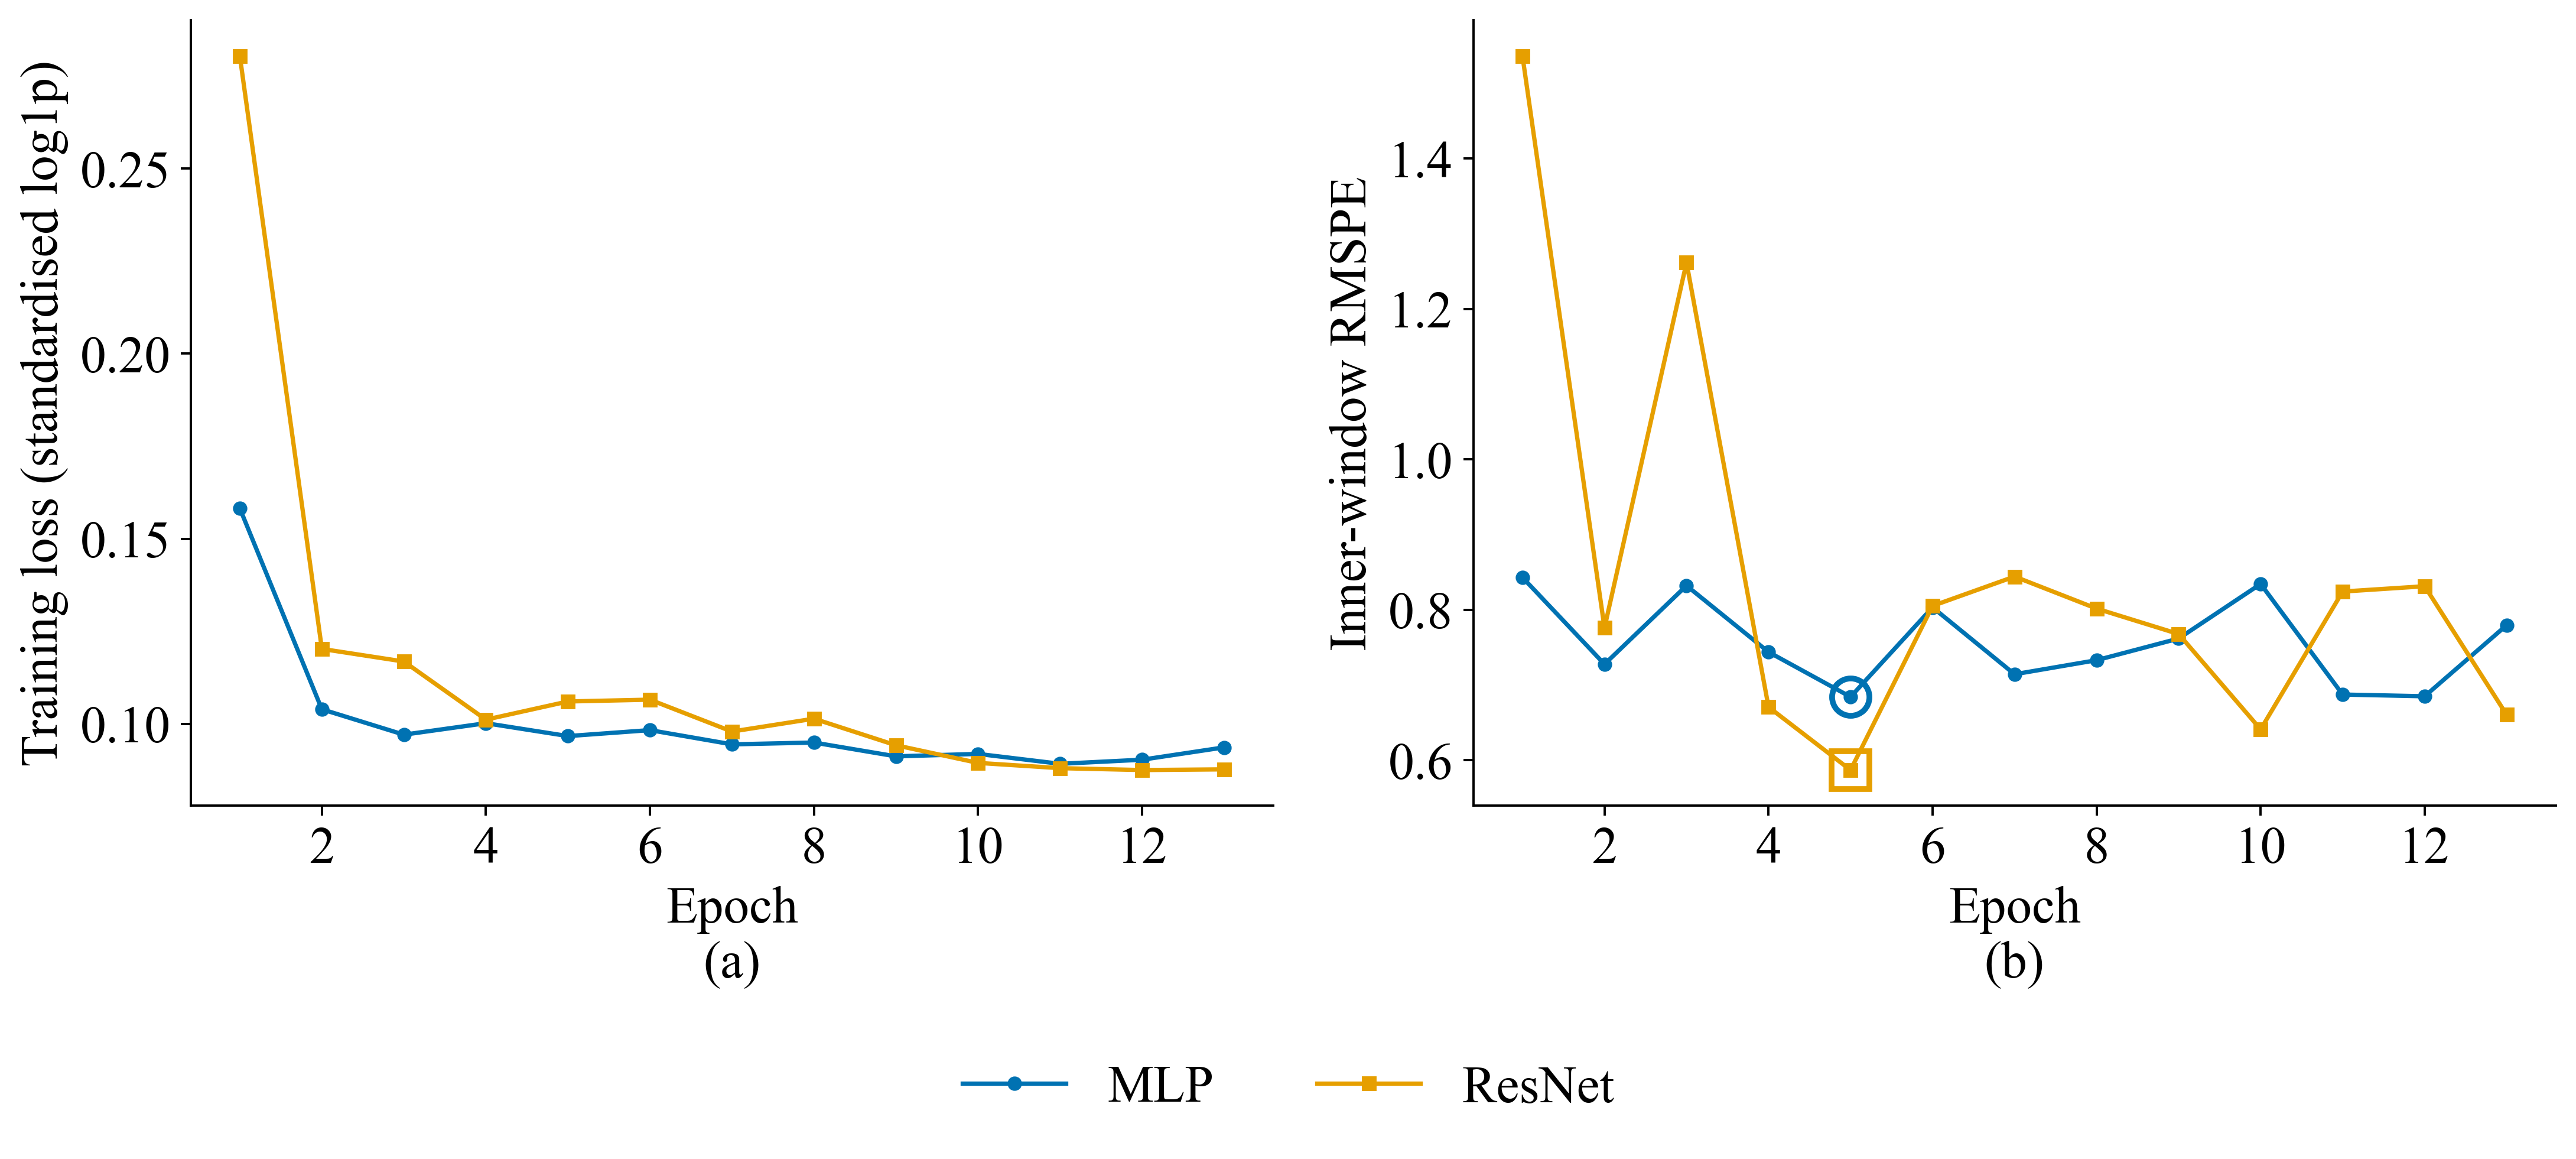

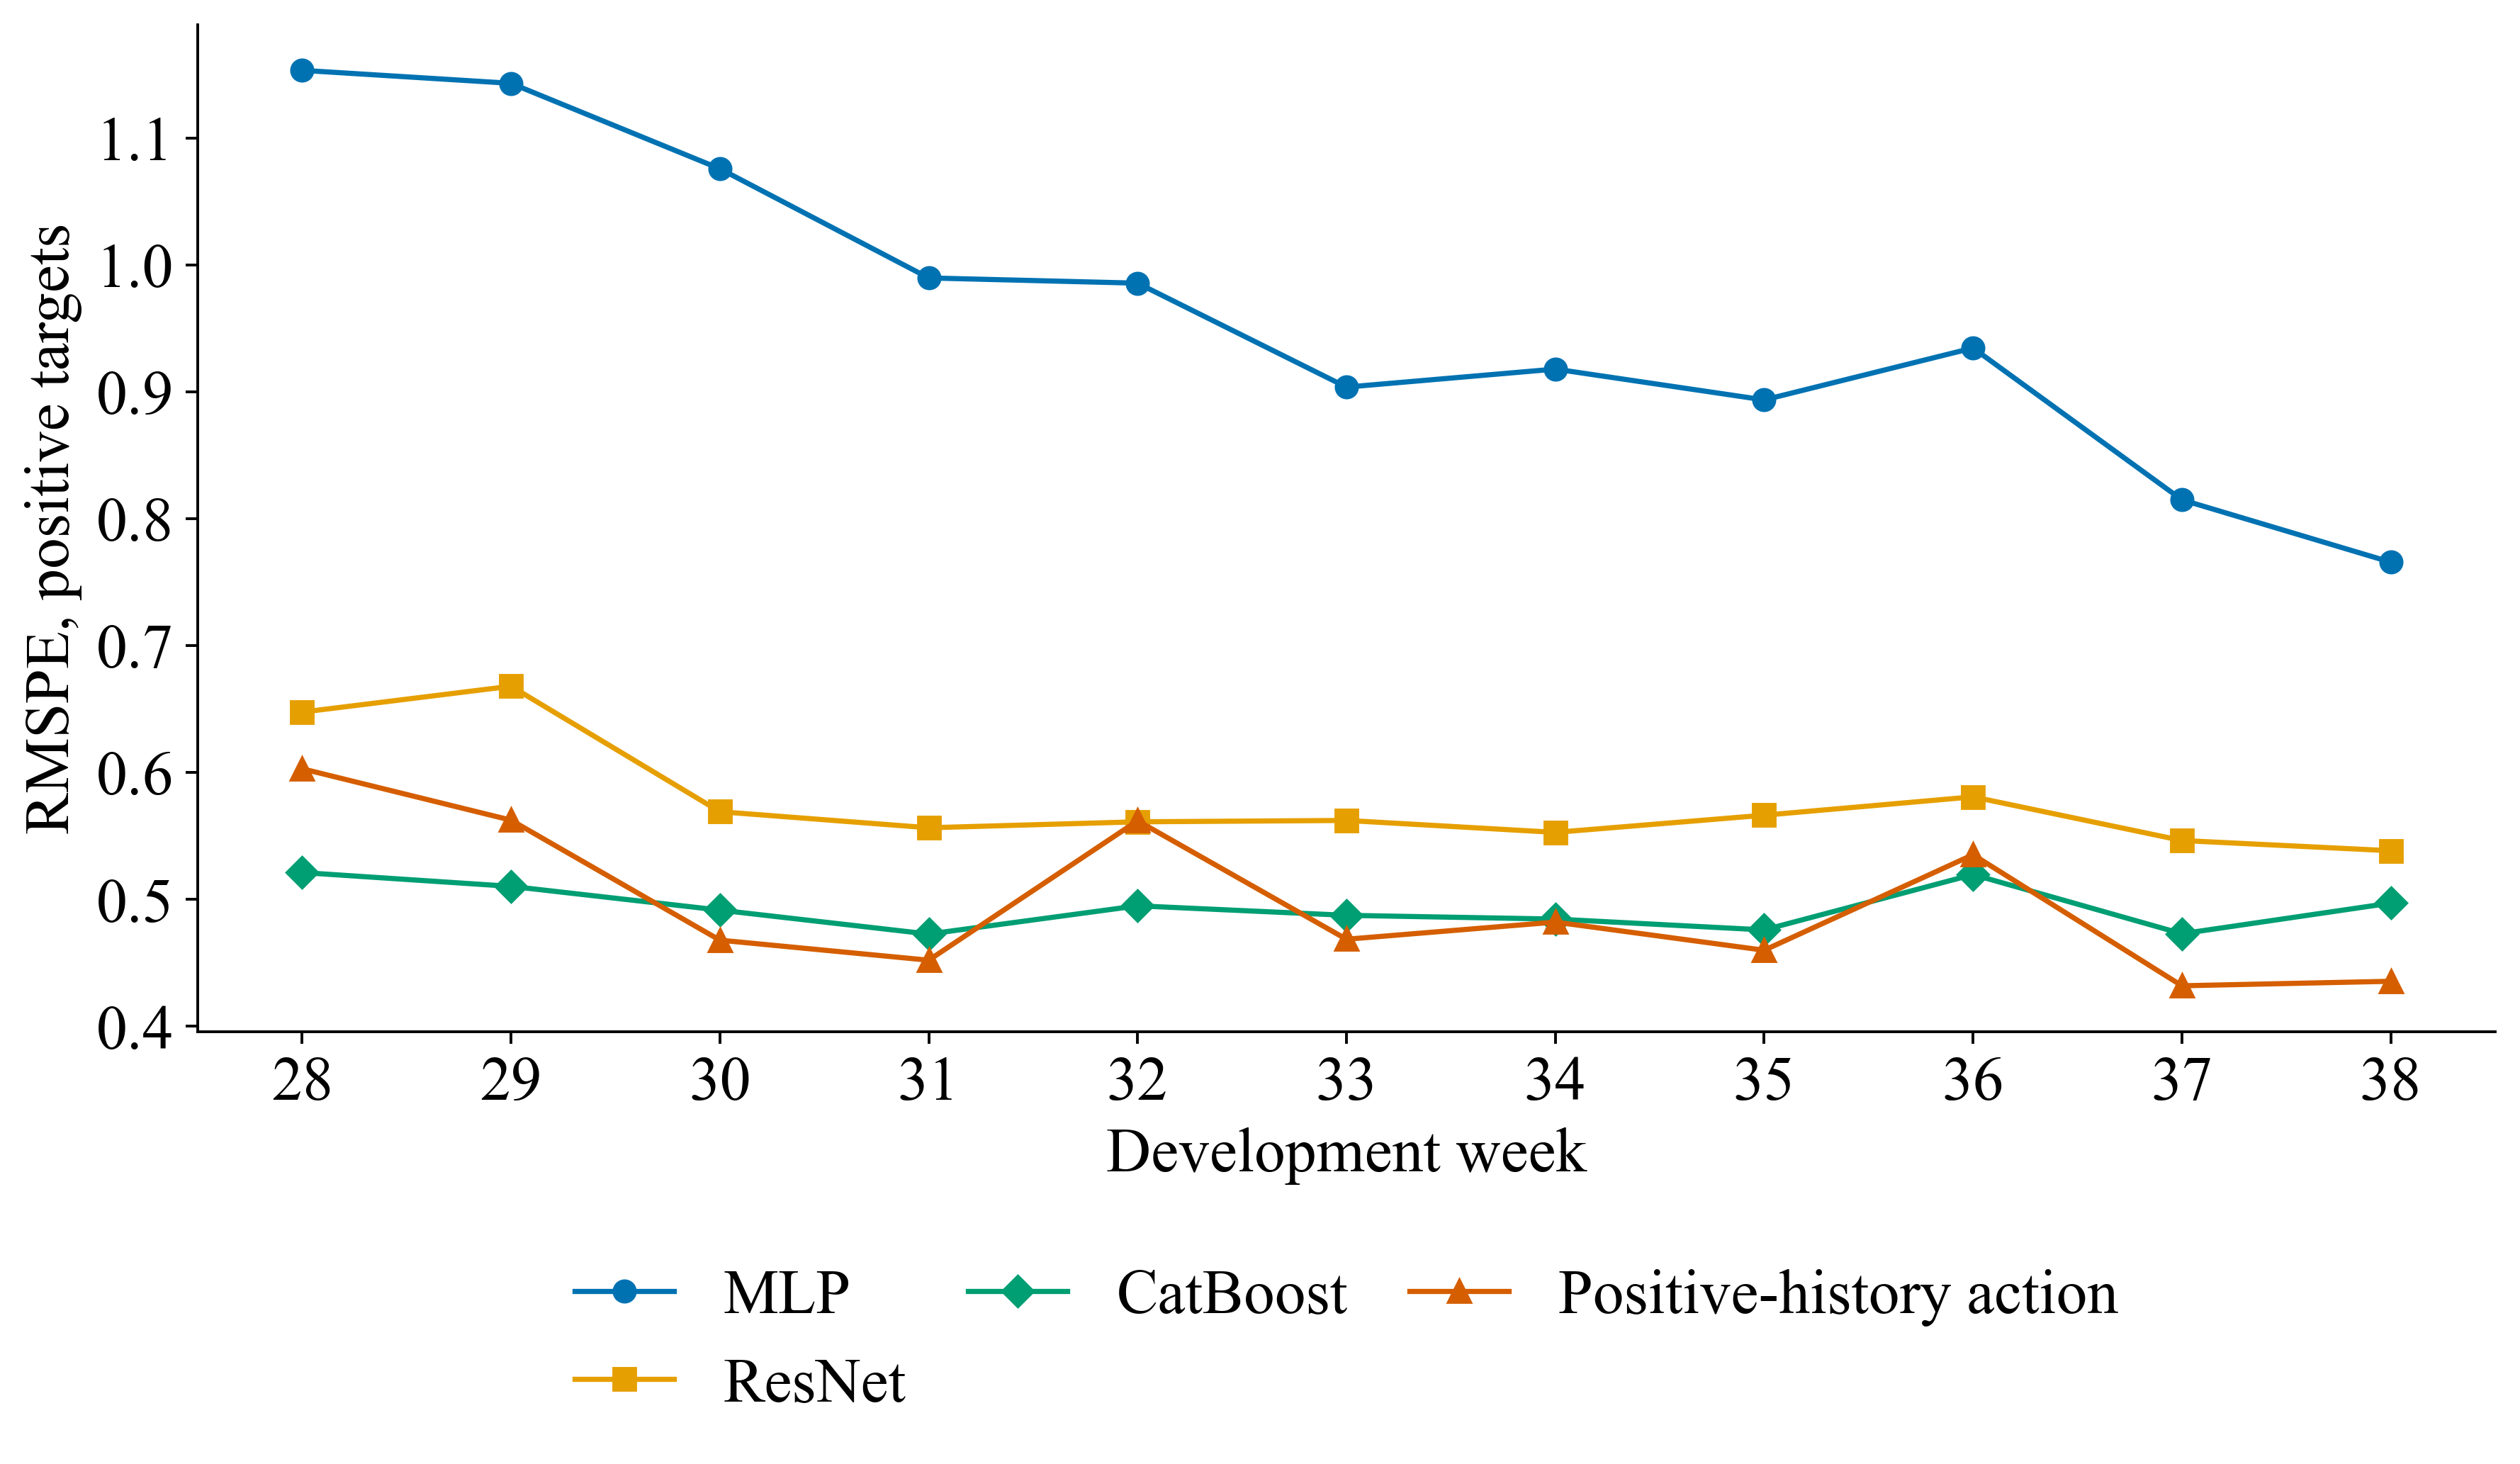

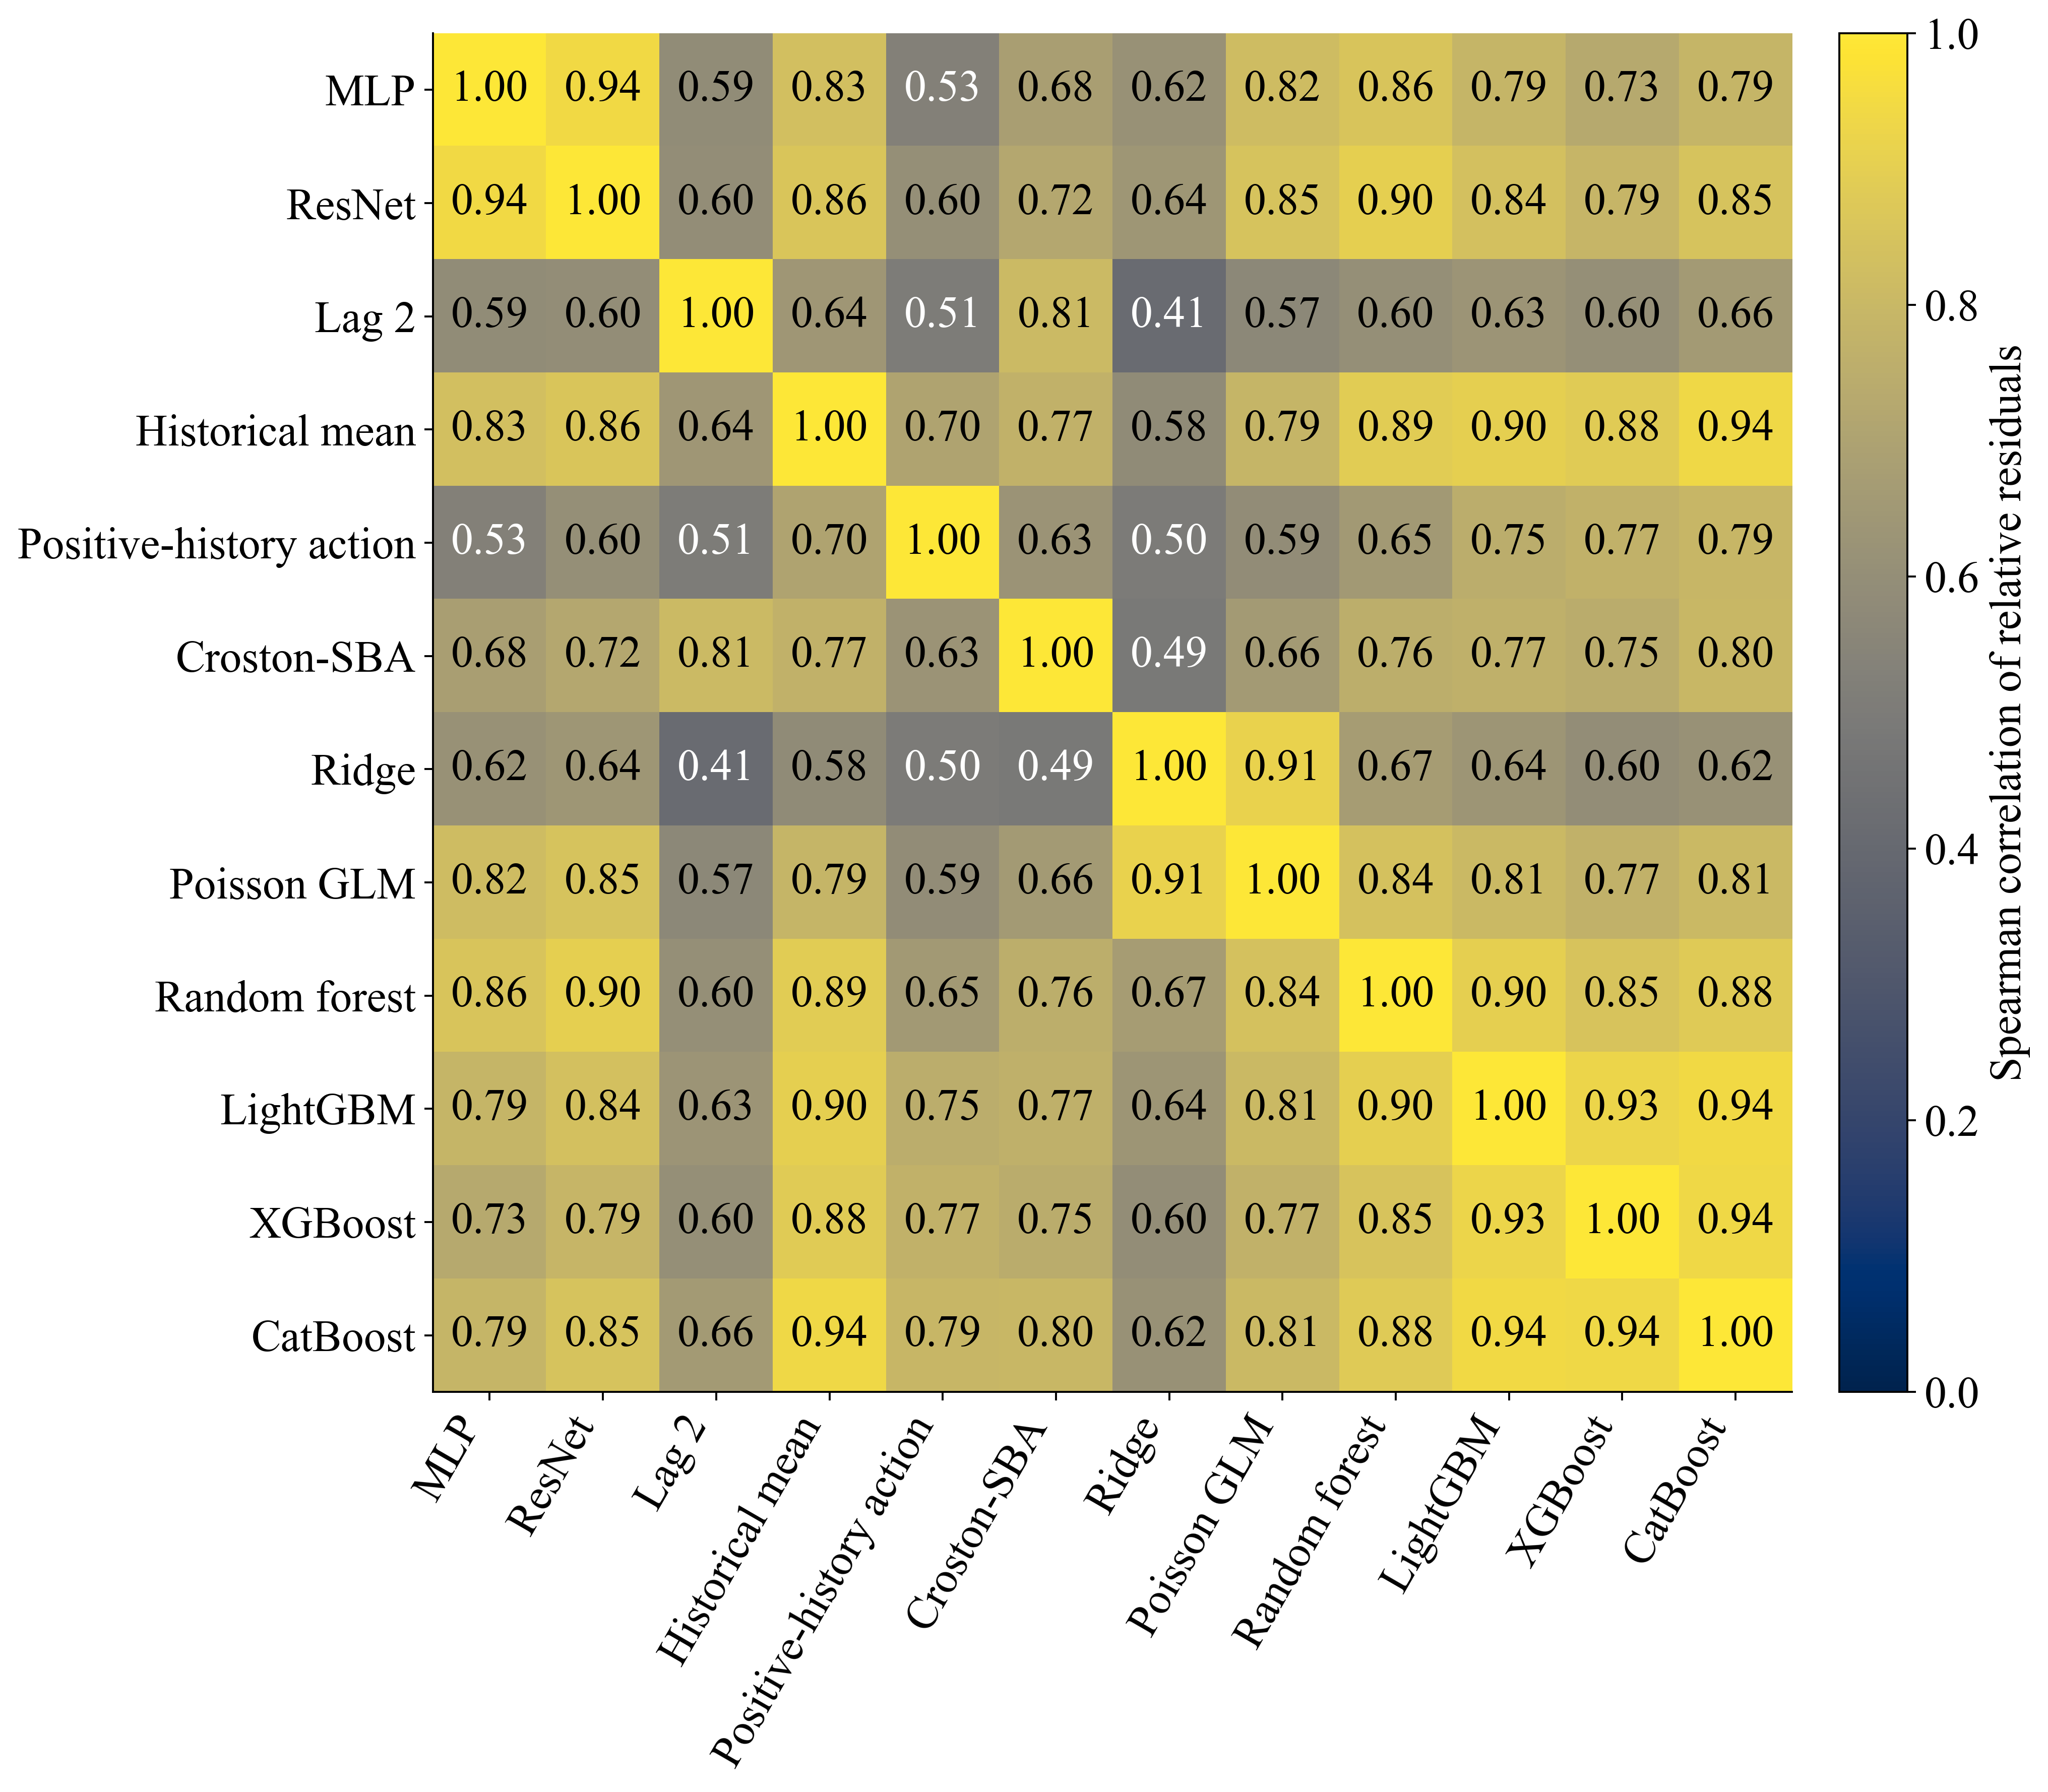

,Network,Most correlated model,Correlation,Least correlated model,Correlation (least)
0,MLP,ResNet,0.94359,Positive-history action,0.52944
1,ResNet,MLP,0.94359,Lag 2,0.59592


In [8]:
# NB04_DIAGNOSTICS: actual training trajectories, weekly RMSPE and residual correlation of all twelve models
fig,axes=plt.subplots(1,2,figsize=(12.8,5.8))
for name,col,mk in zip(MODEL_ORDER,PALETTE,'osD'):
    h=pd.DataFrame(CURVES[f'{name}|final|{SEED}']);e=FROZEN_MODELS[name]['selected_epoch']
    axes[0].plot(h.epoch,h.train_loss,color=col,marker=mk,ms=4,label=name);axes[1].plot(h.epoch,h.inner_RMSPE,color=col,marker=mk,ms=4,label=name);axes[1].plot([e],[h.inner_RMSPE[e-1]],color=col,marker=mk,ms=13,mfc='none',mew=2)
axes[0].set(xlabel='Epoch',ylabel='Training loss (standardised log1p)');axes[1].set(xlabel='Epoch',ylabel='Inner-window RMSPE')
for ax in axes:ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
h_,l_=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h_,l_,loc='lower center',ncol=2,frameon=False);fig.tight_layout(rect=[0,0.10,1,1]);figure(fig,'fig_uci_network_training')
nb03_pred=np.load(NB03_OUT/'development_predictions.npz');nb03_order=BM['model_order'];nb03_rows=pd.read_parquet(NB03_OUT/'development_rows.parquet');assert nb03_rows.row_id.tolist()==DEV.row_id.tolist()
ALL_PRED={name:PREDICTIONS[(name,SEED)] for name in MODEL_ORDER};ALL_PRED.update({m:nb03_pred[f'{nb03_order.index(m)}_{SEED}'] for m in nb03_order})
weeks=sorted(DEV.week.unique());y=DEV.quantity.to_numpy(float);wk=DEV.week.to_numpy()
weekly=pd.DataFrame({m:[rmspe(y[wk==w],p[wk==w]) for w in weeks] for m,p in ALL_PRED.items()},index=weeks);weekly.rename_axis('Week').reset_index().to_csv(OUT/'weekly_metrics.csv',index=False)
show=MODEL_ORDER+nb03_dev.Model.head(2).tolist()
fig,ax=plt.subplots(figsize=(10.5,6.4))
for m,col,mk in zip(show,PALETTE,'osD^v'):ax.plot(weeks,weekly[m],color=col,marker=mk,label=m)
ax.set(xlabel='Development week',ylabel='RMSPE, positive targets');ax.set_xticks(weeks);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=3,frameon=False,columnspacing=1.0,handlelength=1.6);fig.tight_layout();figure(fig,'fig_uci_network_weekly')
positive=y>0;err=pd.DataFrame({m:(p[positive]-y[positive])/y[positive] for m,p in ALL_PRED.items()});corr=err.corr(method='spearman')
corr.rename_axis('Model').reset_index().to_csv(OUT/'error_correlations_full.csv',index=False)
fig,ax=plt.subplots(figsize=(12,10.5));im=ax.imshow(corr.to_numpy(),cmap='cividis',vmin=0,vmax=1)
ax.set_xticks(range(len(corr)),corr.columns,rotation=60,ha='right');ax.set_yticks(range(len(corr)),corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=18,color='white' if corr.iloc[i,j]<0.55 else 'black')
cb=fig.colorbar(im,ax=ax,fraction=0.046,pad=0.03);cb.set_label('Spearman correlation of relative residuals');fig.tight_layout();figure(fig,'fig_uci_error_correlation')
pairs=[{'Network':a,'Most correlated model':corr[a].drop(a).idxmax(),'Correlation':corr[a].drop(a).max(),'Least correlated model':corr[a].drop(a).idxmin(),'Correlation (least)':corr[a].drop(a).min()} for a in MODEL_ORDER]
table(pd.DataFrame(pairs),'error_complementarity')

### Common nested residual distributions

In [9]:
# NB04_UNCERTAINTY: empirical count laws of the networks on the NB03 rule
CALIBRATORS={};uncertainty=[];q=(np.arange(257)+.5)/257
for name in MODEL_ORDER:
    nested=NESTED[name];res=(nested.quantity.to_numpy()-nested.prediction.to_numpy())/np.sqrt(nested.prediction.to_numpy()+1);residual_grid=np.quantile(res,q);CALIBRATORS[name]=residual_grid
    p=PREDICTIONS[(name,SEED)];draws=np.maximum(0,np.rint(p[:,None]+np.sqrt(p[:,None]+1)*residual_grid[None,:]));assert np.all(np.diff(draws,axis=1)>=0)
    low,high=np.quantile(draws,[.05,.95],axis=1,method='inverted_cdf');coverage=np.mean((y>=low)&(y<=high));width=high-low
    crps=np.mean(np.abs(draws-y[:,None]),axis=1)-np.sum((2*np.arange(1,258)-258)*draws,axis=1)/257**2;interval=width+20*np.maximum(low-y,0)+20*np.maximum(y-high,0);p0=(draws==0).mean(axis=1)
    uncertainty.append({'Model':name,'PICP90':coverage,'Coverage error':abs(coverage-.9),'MPIW90':width.mean(),'CRPS':crps.mean(),'Interval score':interval.mean(),'Zero Brier':np.mean((p0-(y==0))**2)})
    pd.DataFrame({'row_id':DEV.row_id,'lower90':low,'upper90':high,'crps':crps,'interval_score':interval,'zero_probability':p0}).to_parquet(OUT/f'uncertainty_{MODEL_ORDER.index(name)}.parquet',index=False)
uncertainty=pd.DataFrame(uncertainty);nb03_unc=pd.read_csv(NB03_OUT/'uncertainty_coverage.csv').merge(pd.read_csv(NB03_OUT/'uncertainty_scores.csv'),on='Model')
both=pd.concat([uncertainty.assign(Notebook='NB04'),nb03_unc.assign(Notebook='NB03')],ignore_index=True)
table(both[['Model','Notebook','PICP90','Coverage error','MPIW90']],'uncertainty_coverage',['Coverage error'])
table(both[['Model','Notebook','CRPS','Interval score','Zero Brier']],'uncertainty_scores',['CRPS','Interval score','Zero Brier'])
np.savez_compressed(OUT/'nested_residual_calibrators.npz',**{str(MODEL_ORDER.index(k)):v for k,v in CALIBRATORS.items()})

,Model,Notebook,PICP90,Coverage error,MPIW90
0,MLP,NB04,0.819429,0.08057,11.592717
1,ResNet,NB04,0.901733,0.00173,9.154508
2,Lag 2,NB03,0.924804,0.02480,9.664173
3,Historical mean,NB03,0.947749,0.04775,9.197780
4,Positive-history action,NB03,0.953610,0.05361,10.366380
5,Croston-SBA,NB03,0.902856,0.00286,8.166480
6,Ridge,NB03,0.467141,0.43286,16.816311
7,Poisson GLM,NB03,0.726275,0.17372,10.792618
8,Random forest,NB03,0.961965,0.06197,8.631874
9,LightGBM,NB03,0.952114,0.05211,8.706572


,Model,Notebook,CRPS,Interval score,Zero Brier
0,MLP,NB04,2.22266,20.82828,0.13329
1,ResNet,NB04,2.16522,16.76643,0.12753
2,Lag 2,NB03,1.84940,14.06871,0.10278
3,Historical mean,NB03,1.68464,12.02856,0.08245
4,Positive-history action,NB03,1.58852,12.90286,0.14094
5,Croston-SBA,NB03,2.10785,16.04277,0.11355
6,Ridge,NB03,17.55933,257.57950,0.22391
7,Poisson GLM,NB03,4.81532,56.53149,0.11473
8,Random forest,NB03,1.45825,10.67702,0.09020
9,LightGBM,NB03,1.58832,11.36276,0.10677


In [10]:
# NB04_REGISTRY: model order, selected configurations and epoch budget for notebooks 05-06; run registry
manifest={'run_id':RUN_ID,'model_order':MODEL_ORDER,'selected_configurations':CONFIGS,'net_epochs':NET_EPOCHS,'nb03_run':BM['run_id']}
dump(BASE/'Manifests/network_manifest.json',manifest)
latest_path=BASE/'Manifests/latest_runs.json';latest=json.loads(latest_path.read_text()) if latest_path.exists() else {};latest['NB04']=RUN_ID;dump(latest_path,latest)

# Part C · M5 (Walmart) weekly item-store sales

## Neural competitors on the causal weekly features

In [1]:
# NB04_SETUP: packages, paths and helpers (same conventions as notebook 03)
import os
os.environ['OMP_NUM_THREADS']='4';os.environ['OPENBLAS_NUM_THREADS']='4'
import json,hashlib,time,platform,sys,resource,gzip,importlib.metadata,inspect,warnings,io,csv,zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import cloudpickle
from IPython.display import display,Markdown,Image
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits,threadpool_info
from scipy import special,stats
THREAD_LIMIT=threadpool_limits(limits=4)
SEED=2026
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'dataset').is_dir() and (p/'notebooks').is_dir())
BASE=ROOT/'outputs'/'m5'
for sub in ['Artifacts', 'Manifests']:(BASE/sub).mkdir(parents=True,exist_ok=True)
RUN_ID='NB04_M5_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ');OUT=BASE/'Artifacts'/RUN_ID;OUT.mkdir(parents=True,exist_ok=True)
def dump(p,v):p.write_text(json.dumps(v,indent=2,allow_nan=False,default=str))
FONT=font_manager.findfont('Times New Roman',fallback_to_default=False)
plt.rcParams.update({'font.family':'Times New Roman','font.size':18,'axes.labelsize':18,'axes.titlesize':20,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':18,'figure.dpi':350,'savefig.dpi':350,'pdf.fonttype':42,'axes.unicode_minus':True,'axes.spines.top':False,'axes.spines.right':False,'mathtext.fontset':'custom','mathtext.rm':'Times New Roman','mathtext.it':'Times New Roman:italic','mathtext.bf':'Times New Roman:bold','mathtext.default':'regular'})
PALETTE=['#0072B2','#E69F00','#009E73','#D55E00','#CC79A7','#56B4E9','#000000']  # Okabe-Ito, colour-blind safe
pd.set_option('display.max_rows',200,'display.max_columns',20,'display.max_colwidth',None,'display.width',220,'display.float_format',lambda v:f'{v:.5f}')
def tidy(df,note='n/a'):
    """Display copy of a table: missing cells are marked explicitly instead of NaN; underflowed p-values are shown as bounds."""
    out=df.copy()
    for c in out.columns:
        if str(c)=='p' or str(c).startswith('p ') or 'p-value' in str(c) or str(c).startswith('Holm p'):
            out[c]=['< 1e-300' if (isinstance(v,float) and v==0.0) else (f'{v:.4g}' if isinstance(v,(float,np.floating)) else v) for v in out[c]]
    return out.astype(object).where(out.notna(),note)
def table(df,name,best=None,fmt='%.5f'):
    clean=tidy(df.reset_index() if df.index.name is not None else df)
    clean.to_csv(OUT/(name+'.csv'),index=False);(OUT/(name+'.tex')).write_text(clean.to_latex(index=False,float_format=fmt,escape=True))
    if best:display(clean.style.format({k:(lambda v:(fmt%v) if isinstance(v,(float,np.floating)) else v) for k in best}).highlight_min(subset=best,props='font-weight:bold;'))
    else:display(clean)
def figure(fig,name):
    for ext,dpi in [('pdf',350),('png',350),('png',600)]:fig.savefig(OUT/(name+('_600dpi' if dpi==600 else '')+'.'+ext),dpi=dpi,bbox_inches='tight')
    plt.close(fig);display(Image(filename=str(OUT/(name+'.png')),width=900))
def label_panels(axes,labels='abcdefgh'):
    """Letter each panel below its x-axis label, (a), (b), ..., so that panels can be cited."""
    for ax,l in zip(np.ravel(axes),labels):ax.set_xlabel((ax.get_xlabel()+'\n' if ax.get_xlabel() else '')+f'({l})')
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);assert len(y)==len(p) and np.isfinite(p).all() and (p>=0).all()
    positive=y>0;zero=~positive;den=np.abs(y)+np.abs(p);sm=np.divide(2*np.abs(y-p),den,out=np.zeros(len(y)),where=den>0)
    return {'RMSPE':float(np.sqrt(np.mean(((p[positive]-y[positive])/y[positive])**2))),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'sMAPE_pct':float(100*sm.mean()),'R2':float(1-np.sum((p-y)**2)/np.sum((y-y.mean())**2)),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def rmspe(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))

import torch,torch.nn as nn,torch.nn.functional as F
from sklearn.preprocessing import QuantileTransformer
torch.set_num_threads(4);DEVICE=torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
PLAN=json.loads((BASE/'Configs/baseline_search.json').read_text());FM=json.loads((BASE/'Manifests/feature_manifest.json').read_text());BM=json.loads((BASE/'Manifests/baseline_manifest.json').read_text())
NB03_OUT=BASE/'Artifacts'/BM['run_id']

### Common rows, NB03 preprocessing and the inner early-stopping window

In [2]:
# NB04_DATA
rows=pd.read_parquet(BASE/'Data/causal_features_core.parquet').sort_values(['week','id']).reset_index(drop=True)
FEATURES=FM['features'];COUNT=FM['count_features'];MISSING=FM['missing_indicator_features'];ONE_HOT=FM['one_hot'];NAMES=FEATURES+[f'{x}_missing' for x in MISSING]+ONE_HOT
class FoldPreprocessor:
    def fixed(self,frame):
        a=frame[FEATURES].astype(float).copy();a[COUNT]=np.log1p(a[COUNT]);return a
    def fit(self,frame):
        a=self.fixed(frame);self.median=a.median();b=a.fillna(self.median);self.scale=(b.quantile(.75)-b.quantile(.25));self.scale=self.scale.where(self.scale>0,1.);return self
    def transform(self,frame):
        a=self.fixed(frame);z=(a.fillna(self.median)-self.median)/self.scale
        for k in MISSING:z[k+'_missing']=a[k].isna().astype(float)
        z[ONE_HOT]=frame[ONE_HOT].to_numpy(np.float32);out=z[NAMES].astype(np.float32);assert np.isfinite(out.to_numpy()).all();return out
STAGES={'F0':(239,(241,243)),'F1':(243,(245,248)),'F2':(247,(249,252)),'Initial':(251,(253,263))};FITW=PLAN['fit_window_weeks'];NET_EPOCHS={'max_epochs':20,'patience':4,'hold_out_weeks':4,'batch_size':1024}
hash_key=lambda x:hashlib.sha256(('assem-m5-search-2026:'+x).encode()).hexdigest();CORE_IDS=sorted(rows.id.unique());SEARCH_IDS=set(sorted(CORE_IDS,key=hash_key)[:int(np.ceil(PLAN['search_cohort_share']*len(CORE_IDS)))]);rows['search']=rows.id.isin(SEARCH_IDS)
DATA={};PREP={}
for stage,(last,bounds) in STAGES.items():
    tr=rows[rows.week.between(last-FITW+1,last)];ev=rows[rows.week.between(*bounds)];p=FoldPreprocessor().fit(tr)
    PREP[stage]=p;DATA[stage]={'train':tr,'eval':ev,'inner':(tr.week>last-NET_EPOCHS['hold_out_weeks']).to_numpy()}
DEV=DATA['Initial']['eval'];CAL=rows[rows.week.between(245,251)]
table(pd.DataFrame([{'Stage':k,'Network fit weeks':f"W{v[0]-FITW+1}–W{v[0]-NET_EPOCHS['hold_out_weeks']}",'Inner window':f"W{v[0]-NET_EPOCHS['hold_out_weeks']+1}–W{v[0]}",'Forecast weeks':f'W{v[1][0]}–W{v[1][1]}','Fit rows (all / search)':f"{int((~DATA[k]['inner']).sum()):,} / {int((~DATA[k]['inner']&DATA[k]['train'].search.to_numpy()).sum()):,}",'Forecast rows':len(DATA[k]['eval'])} for k,v in STAGES.items()]),'nested_timeline')

,Stage,Network fit weeks,Inner window,Forecast weeks,Fit rows (all / search),Forecast rows
0,F0,W136–W235,W236–W239,W241–W243,"2,744,100 / 548,900",82323
1,F1,W140–W239,W240–W243,W245–W248,"2,744,100 / 548,900",109764
2,F2,W144–W243,W244–W247,W249–W252,"2,744,100 / 548,900",109764
3,Initial,W148–W247,W248–W251,W253–W263,"2,744,100 / 548,900",301851


### Network definitions and the fitting recipe

In [3]:
# NB04_NETWORKS
N_NUM=len(NAMES);CARD=[];NUM_POS=[i for i,c in enumerate(NAMES) if not c.endswith('_missing') and c not in ONE_HOT]
class Embeds(nn.Module):
    def __init__(self,card,d):
        super().__init__();self.embs=nn.ModuleList([nn.Embedding(c,d) for c in card])
    def forward(self,xc):return torch.cat([e(xc[:,i]) for i,e in enumerate(self.embs)],1) if len(self.embs) else xc.new_zeros((xc.shape[0],0),dtype=torch.float32)
class MLP(nn.Module):
    def __init__(self,width=512,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);layers,d_in=[],N_NUM+d_emb*len(CARD)
        for _ in range(depth):layers+=[nn.Linear(d_in,width),nn.ReLU(),nn.Dropout(dropout)];d_in=width
        self.body=nn.Sequential(*layers);self.head=nn.Linear(d_in,out)
    def forward(self,xn,xc):return self.head(self.body(torch.cat([xn,self.emb(xc)],1)))
class ResBlock(nn.Module):
    def __init__(self,d,hidden,dropout):
        super().__init__();self.norm=nn.BatchNorm1d(d);self.l1=nn.Linear(d,hidden);self.l2=nn.Linear(hidden,d);self.dp=nn.Dropout(dropout)
    def forward(self,x):return x+self.l2(self.dp(F.relu(self.l1(self.norm(x)))))
class ResNet(nn.Module):
    def __init__(self,d=256,depth=3,dropout=0.1,d_emb=8,out=1):
        super().__init__();self.emb=Embeds(CARD,d_emb);self.inp=nn.Linear(N_NUM+d_emb*len(CARD),d);self.blocks=nn.Sequential(*[ResBlock(d,2*d,dropout) for _ in range(depth)]);self.norm=nn.BatchNorm1d(d);self.head=nn.Linear(d,out)
    def forward(self,xn,xc):return self.head(F.relu(self.norm(self.blocks(self.inp(torch.cat([xn,self.emb(xc)],1))))))
NETS={'MLP':lambda c:MLP(c['width'],c['depth'],c['dropout']),'ResNet':lambda c:ResNet(c['d'],c['depth'],c['dropout'])}
SPACES={'MLP':{'width':[256,512,1024],'depth':[2,3,4],'dropout':(0.0,0.3,'float'),'lr':(1e-4,3e-3,'log'),'weight_decay':(1e-6,1e-3,'log')},'ResNet':{'d':[128,256,512],'depth':[2,3,4],'dropout':(0.0,0.3,'float'),'lr':(1e-4,3e-3,'log'),'weight_decay':(1e-6,1e-3,'log')}}
N_TRIALS=8;NET_SEEDS=[2026,2027,2028]
def draw_configurations(space,n=N_TRIALS,seed=SEED):
    g=np.random.default_rng(seed);out=[]
    for _ in range(n):
        cfg={}
        for k,v in space.items():
            if isinstance(v,list):cfg[k]=v[g.integers(len(v))]
            else:lo,hi,kind=v;cfg[k]=float(np.exp(g.uniform(np.log(lo),np.log(hi)))) if kind=='log' else (int(g.integers(lo,hi+1)) if kind=='int' else float(g.uniform(lo,hi)))
        out.append({k:(int(v) if isinstance(v,(np.integer,int)) else float(v)) for k,v in cfg.items()})
    return out
GRID={name:draw_configurations(space) for name,space in SPACES.items()}
class NetInputs:
    def fit(self,X):self.qt=QuantileTransformer(n_quantiles=1000,output_distribution='normal',subsample=200_000,random_state=SEED).fit(X.to_numpy(np.float32)[:,NUM_POS]);return self
    def transform(self,X):
        Z=X.to_numpy(np.float32).copy();Z[:,NUM_POS]=self.qt.transform(Z[:,NUM_POS]).astype(np.float32);return torch.tensor(Z),torch.zeros((len(Z),0),dtype=torch.int64)
@torch.no_grad()
def predict_net(net,Xn,Xc,mu_sd,bs=8192):
    net.eval();outs=[]
    for i in range(0,len(Xn),bs):outs.append(net(Xn[i:i+bs].to(DEVICE),Xc[i:i+bs].to(DEVICE))[:,0].cpu())
    return np.maximum(0.,np.expm1(torch.cat(outs).numpy()*mu_sd[1]+mu_sd[0]))
def rmspe(y,p):m=y>0;return float(np.sqrt(np.mean(((p[m]-y[m])/y[m])**2)))
def fit_net_inner(name,cfg,stage,seed,cohort):
    d=DATA[stage];tr=d['train'];sel=tr.search.to_numpy() if cohort=='search' else np.ones(len(tr),bool);fit=sel&~d['inner'];inner=sel&d['inner']
    X=PREP[stage].transform(tr);ni=NetInputs().fit(X[fit]);Xf,Cf=ni.transform(X[fit]);Xi,Ci=ni.transform(X[inner]);yq=tr.quantity.to_numpy(float);lf=np.log1p(yq[fit]);mu_sd=(float(lf.mean()),float(lf.std()));yf=torch.tensor(((lf-mu_sd[0])/mu_sd[1]).astype(np.float32));yi=yq[inner]
    torch.manual_seed(seed);net=NETS[name](cfg).to(DEVICE);opt=torch.optim.AdamW(net.parameters(),lr=cfg['lr'],weight_decay=cfg['weight_decay']);n,bs=len(yf),NET_EPOCHS['batch_size'];best,best_state,best_epoch,bad,hist=np.inf,None,0,0,[]
    for ep in range(NET_EPOCHS['max_epochs']):
        net.train();perm=torch.randperm(n);tl=0.
        for i in range(0,n,bs):
            j=perm[i:i+bs]
            if len(j)<2:continue
            opt.zero_grad();out=net(Xf[j].to(DEVICE),Cf[j].to(DEVICE));loss=F.mse_loss(out[:,0],yf[j].to(DEVICE));loss.backward();nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step();tl+=float(loss.detach())*len(j)
        score=rmspe(yi,predict_net(net,Xi,Ci,mu_sd));hist.append({'epoch':ep+1,'train_loss':tl/n,'inner_RMSPE':score})
        if score<best-1e-5:best,best_state,best_epoch,bad=score,{k:v.detach().clone() for k,v in net.state_dict().items()},ep+1,0
        else:
            bad+=1
            if bad>=NET_EPOCHS['patience']:break
    net.load_state_dict(best_state);net.eval();return net,ni,mu_sd,best_epoch,best,pd.DataFrame(hist)
table(pd.DataFrame([{'Model':m,'Configurations':len(GRID[m]),'Search seed':SEED,'Final seeds':len(NET_SEEDS),'Epoch budget':NET_EPOCHS['max_epochs'],'Patience':NET_EPOCHS['patience'],'Batch size':NET_EPOCHS['batch_size'],'Parameters (first configuration)':sum(p.numel() for p in NETS[m](GRID[m][0]).parameters())} for m in NETS]),'fixed_network_budget')
for m in NETS:table(pd.DataFrame(GRID[m]).rename_axis('Configuration').reset_index(),f'{m.lower().replace("-","_")}_configurations')

,Model,Configurations,Search seed,Final seeds,Epoch budget,Patience,Batch size,Parameters (first configuration)
0,MLP,8,2026,3,20,4,1024,1120257
1,ResNet,8,2026,3,20,4,1024,2138625


,Configuration,width,depth,dropout,lr,weight_decay
0,0,1024,2,0.19197,0.00049,0.00001
1,1,512,3,0.23716,0.00217,0.00000
2,2,1024,3,0.08949,0.00268,0.00057
3,3,256,3,0.22582,0.00058,0.00030
4,4,512,3,0.10164,0.00026,0.00000
5,5,1024,3,0.12927,0.00095,0.00000
6,6,512,3,0.10955,0.00019,0.00006
7,7,256,3,0.09000,0.00020,0.00042


,Configuration,d,depth,dropout,lr,weight_decay
0,0,512,2,0.19197,0.00049,0.00001
1,1,256,3,0.23716,0.00217,0.00000
2,2,512,3,0.08949,0.00268,0.00057
3,3,128,3,0.22582,0.00058,0.00030
4,4,256,3,0.10164,0.00026,0.00000
5,5,512,3,0.12927,0.00095,0.00000
6,6,256,3,0.10955,0.00019,0.00006
7,7,128,3,0.09000,0.00020,0.00042


### Search engine: the NB03 chronology for networks

In [4]:
# NB04_ENGINE
SEARCH={};NESTED={};PREDICTIONS={};CONFIGS={};FROZEN_MODELS={};RESOURCES=[];TRIALS=[];CURVES={};EPOCHS=[]
def metrics(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float);positive=y>0;zero=~positive
    return {'RMSPE':rmspe(y,p),'RMSE':float(np.sqrt(np.mean((p-y)**2))),'MAE':float(np.mean(np.abs(p-y))),'Zero_MAE':float(np.mean(p[zero])) if zero.any() else 0.,'Positive_n':int(positive.sum()),'Zero_n':int(zero.sum())}
def fit_predict(name,cfg,seed,stage,tag,cohort):
    t0=time.perf_counter();net,ni,mu_sd,ep,inner_score,hist=fit_net_inner(name,cfg,stage,seed,cohort);fit_seconds=time.perf_counter()-t0
    ev=DATA[stage]['eval'];ev=ev[ev.search] if cohort=='search' else ev;point=predict_net(net,*ni.transform(PREP[stage].transform(ev)),mu_sd);assert np.isfinite(point).all()
    RESOURCES.append({'Model':name,'Tag':tag,'Stage':stage,'Cohort':cohort,'Seed':seed,'Actual learner fit':1,'Forecast rows':len(point),'Epochs run':len(hist),'Selected epoch':ep,'Inner RMSPE':inner_score,'Fit seconds':fit_seconds,'Process peak MiB':resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/2**20})
    CURVES[tag]=hist.to_dict('list');EPOCHS.append({'Model':name,'Tag':tag,'Stage':stage,'Cohort':cohort,'Seed':seed,'Selected epoch':ep,'Epochs run':len(hist),'Inner-window RMSPE':inner_score})
    return point,{'state_dict':{k:v.cpu() for k,v in net.state_dict().items()},'configuration':cfg,'qt':ni.qt,'mu_sd':mu_sd,'selected_epoch':ep}
def score_candidate(name,index,stages,latest):
    ys=[];ps=[]
    for st in stages:
        ev=DATA[st]['eval'];ev=ev[ev.search];mask=ev.week.to_numpy()<=latest;ys.append(ev.quantity.to_numpy()[mask]);ps.append(SEARCH[(name,index,st)][mask])
    return metrics(np.concatenate(ys),np.concatenate(ps))
def select_config(name,stages,latest):return min((score_candidate(name,j,stages,latest)['RMSPE'],score_candidate(name,j,stages,latest)['MAE'],j) for j in range(len(GRID[name])))[2]
MODEL_ORDER=list(NETS)
def run_family(name):
    progress=display(pd.DataFrame([{'Model':name,'Completed candidate paths':0,'Total candidate paths':3*len(GRID[name])}]),display_id=True);t0=time.time()
    for j,cfg in enumerate(GRID[name]):
        for stage in ['F0','F1','F2']:SEARCH[(name,j,stage)]=fit_predict(name,cfg,SEED,stage,f'{name}|search{j}|{stage}','search')[0]
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*(j+1),'Total candidate paths':3*len(GRID[name]),'Latest inner RMSPE':RESOURCES[-1]['Inner RMSPE'],'Elapsed s':int(time.time()-t0)}]))
    nested_choice={'F1':select_config(name,['F0'],243),'F2':select_config(name,['F0','F1'],247)};blocks=[]
    for st in ['F1','F2']:
        p,_=fit_predict(name,GRID[name][nested_choice[st]],SEED,st,f'{name}|nested|{st}','all');ev=DATA[st]['eval'];keep=(ev.week<=251).to_numpy();b=ev.loc[keep,['row_id','id','week','quantity']].copy();b['prediction']=p[keep];b['configuration']=nested_choice[st];b['model']=name;blocks.append(b)
    NESTED[name]=pd.concat(blocks,ignore_index=True);assert NESTED[name].row_id.tolist()==CAL.row_id.tolist()
    scores=[(score_candidate(name,j,['F1','F2'],251)['RMSPE'],score_candidate(name,j,['F1','F2'],251)['MAE'],j) for j in range(len(GRID[name]))];selected=min(scores)[2];cfg=GRID[name][selected]
    for j in range(len(GRID[name])):TRIALS.append({'Model':name,'Configuration':j,'Selected':j==selected,**score_candidate(name,j,['F1','F2'],251)})
    CONFIGS[name]={'selected_index':selected,'parameters':cfg,'nested_indices':nested_choice}
    for seed in NET_SEEDS:
        p,model=fit_predict(name,cfg,seed,'Initial',f'{name}|final|{seed}','all');PREDICTIONS[(name,seed)]=p
        if seed==SEED:FROZEN_MODELS[name]=model
        progress.update(pd.DataFrame([{'Model':name,'Completed candidate paths':3*len(GRID[name]),'Latest final seed':seed,'Selected epoch':model['selected_epoch'],'Elapsed s':int(time.time()-t0)}]))
    table(pd.DataFrame([{'Model':name,'Selected configuration':selected,'Nested F1 configuration':nested_choice['F1'],'Nested F2 configuration':nested_choice['F2'],'Actual final fits':len(NET_SEEDS),**cfg}]),name.lower().replace('-','_')+'_selection')
    table(pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,SEED)])}]).drop(columns=['Positive_n','Zero_n']),name.lower().replace('-','_')+'_development')
    dump(OUT/'selected_configurations.json',CONFIGS);pd.DataFrame(RESOURCES).to_csv(OUT/'fit_resources.csv',index=False);dump(OUT/'training_curves.json',CURVES)
    np.savez_compressed(OUT/'development_predictions.npz',**{f'{MODEL_ORDER.index(k[0])}_{k[1]}':v.astype(np.float32) for k,v in PREDICTIONS.items()})
    pd.concat(NESTED.values(),ignore_index=True).to_parquet(OUT/'nested_oof.parquet',index=False)
    with gzip.open(OUT/'fitted_models.pkl.gz','wb') as f:cloudpickle.dump({'models':FROZEN_MODELS,'configurations':CONFIGS,'feature_names':NAMES,'net_epochs':NET_EPOCHS,'numeric_positions':NUM_POS},f)

### MLP

In [5]:
# NB04_MLP
run_family('MLP')

,Model,Completed candidate paths,Latest final seed,Selected epoch,Elapsed s
0,MLP,24,2028,1,2149


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,width,depth,dropout,lr,weight_decay
0,MLP,0,2,2,3,1024,2,0.19197,0.00049,0.00001


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,MLP,0.98660,11.12078,4.09909,1.56140


### ResNet

In [6]:
# NB04_RESNET
run_family('ResNet')

,Model,Completed candidate paths,Latest final seed,Selected epoch,Elapsed s
0,ResNet,24,2028,1,4642


Error: command buffer exited with error status.
	The Metal Performance Shaders operations encoded on it may not have completed.
	Error: 
	(null)
	Discarded (victim of GPU error/recovery) (00000005:kIOGPUCommandBufferCallbackErrorInnocentVictim)
	<AGXG13XFamilyCommandBuffer: 0x71b971f900>
    label = <none> 
    device = <AGXG13XDevice: 0x155849200>
        name = Apple M1 Pro 
    commandQueue = <AGXG13XFamilyCommandQueue: 0x123fdb200>
        label = <none> 
        device = <AGXG13XDevice: 0x155849200>
            name = Apple M1 Pro 
    retainedReferences = 1


,Model,Selected configuration,Nested F1 configuration,Nested F2 configuration,Actual final fits,d,depth,dropout,lr,weight_decay
0,ResNet,5,1,4,3,512,3,0.12927,0.00095,0.00000


,Model,RMSPE,RMSE,MAE,Zero_MAE
0,ResNet,0.95853,12.22643,4.19096,1.46464


### Development comparison with the NB03 families, seed stability, selected epochs and training dynamics

,Model,Notebook,RMSPE,RMSE,MAE,Zero_MAE
0,Positive-history action,NB03,0.65215,20.83487,7.42326,1.82827
1,LightGBM,NB03,0.72329,20.79464,7.54594,0.45456
2,XGBoost,NB03,0.72339,20.85676,7.56612,0.45350
3,CatBoost,NB03,0.73424,21.24598,7.79965,0.45496
4,ResNet,NB04,0.95853,12.22643,4.19096,1.46464
5,Random forest,NB03,0.96930,10.26930,3.84016,1.45765
6,MLP,NB04,0.98660,11.12078,4.09909,1.56140
7,Croston-SBA,NB03,1.13515,12.23502,4.89478,2.70793
8,Ridge,NB03,1.19578,10.43800,3.84286,1.50191
9,Poisson GLM,NB03,1.55270,9.67846,3.75936,2.52536


,Model,Actual seeds,Mean RMSPE,SD RMSPE,Minimum RMSPE,Maximum RMSPE
0,MLP,3,1.03986,0.06817,0.98660,1.11669
1,ResNet,3,0.98323,0.02854,0.95853,1.01448


,Model,Stage,Seed,Selected epoch,Epochs run,Inner-window RMSPE
0,MLP,F1,2026,3,7,0.79879
1,MLP,F2,2026,4,8,0.89281
2,MLP,Initial,2026,8,12,0.94342
3,MLP,Initial,2027,1,5,0.99859
4,MLP,Initial,2028,1,5,1.04772
5,ResNet,F1,2026,8,12,0.96358
6,ResNet,F2,2026,3,7,1.10179
7,ResNet,Initial,2026,2,6,0.93626
8,ResNet,Initial,2027,4,8,0.98244
9,ResNet,Initial,2028,1,5,0.94602


,Model,actual_fits,fit_seconds,mean_selected_epoch,process_peak_MiB
0,MLP,29,2138.78042,4.48276,4998.54688
1,ResNet,29,4629.31984,4.17241,4998.54688


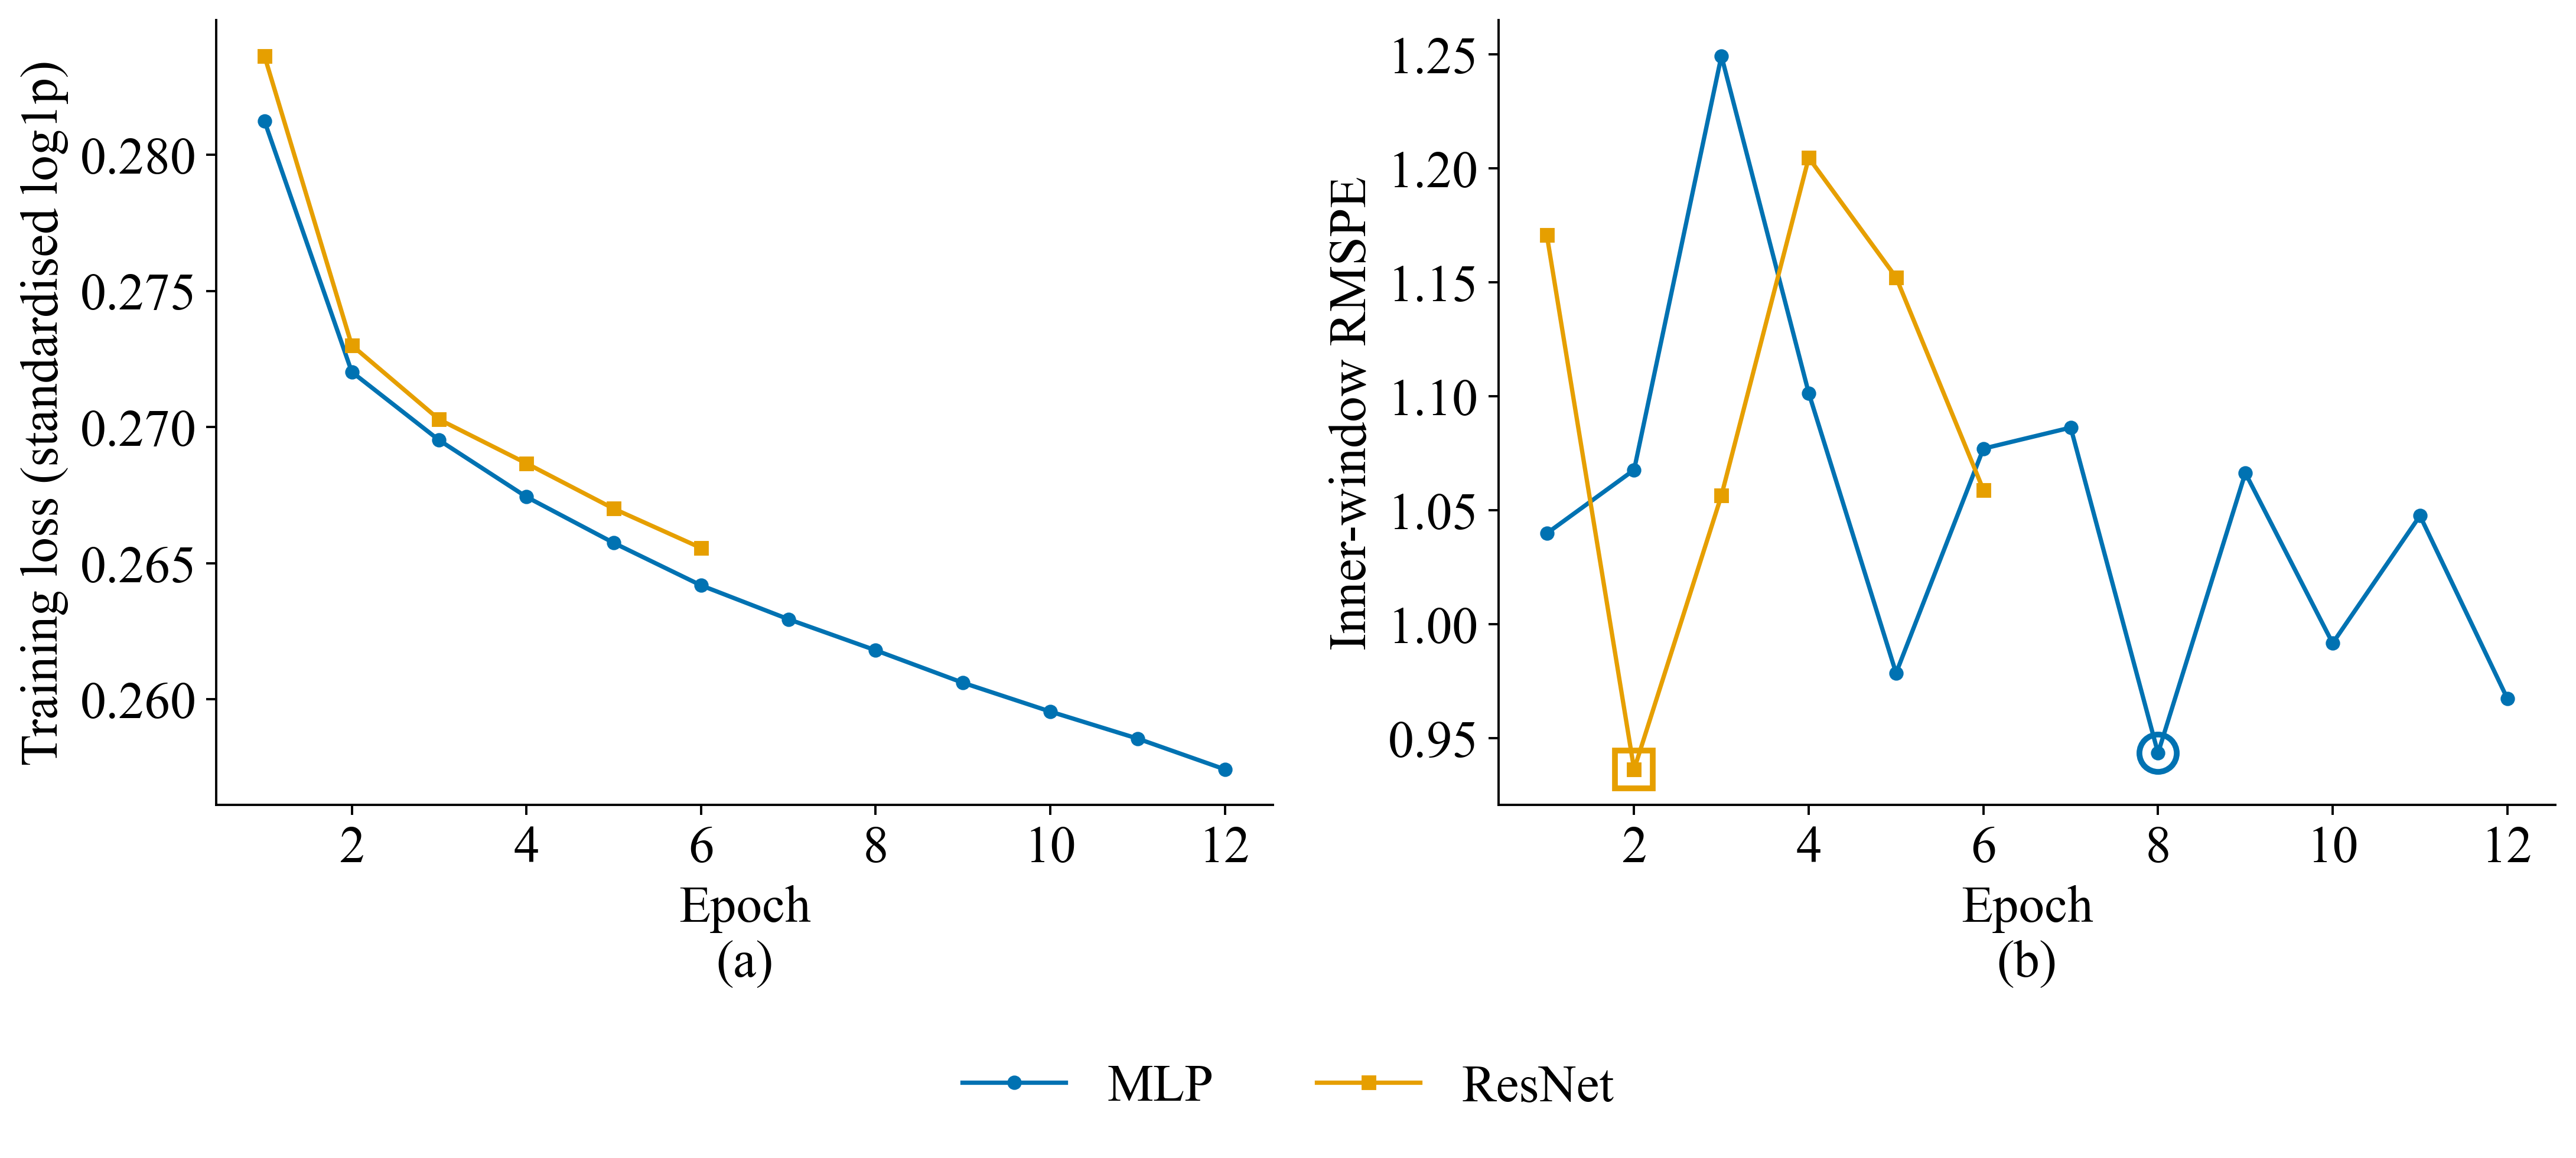

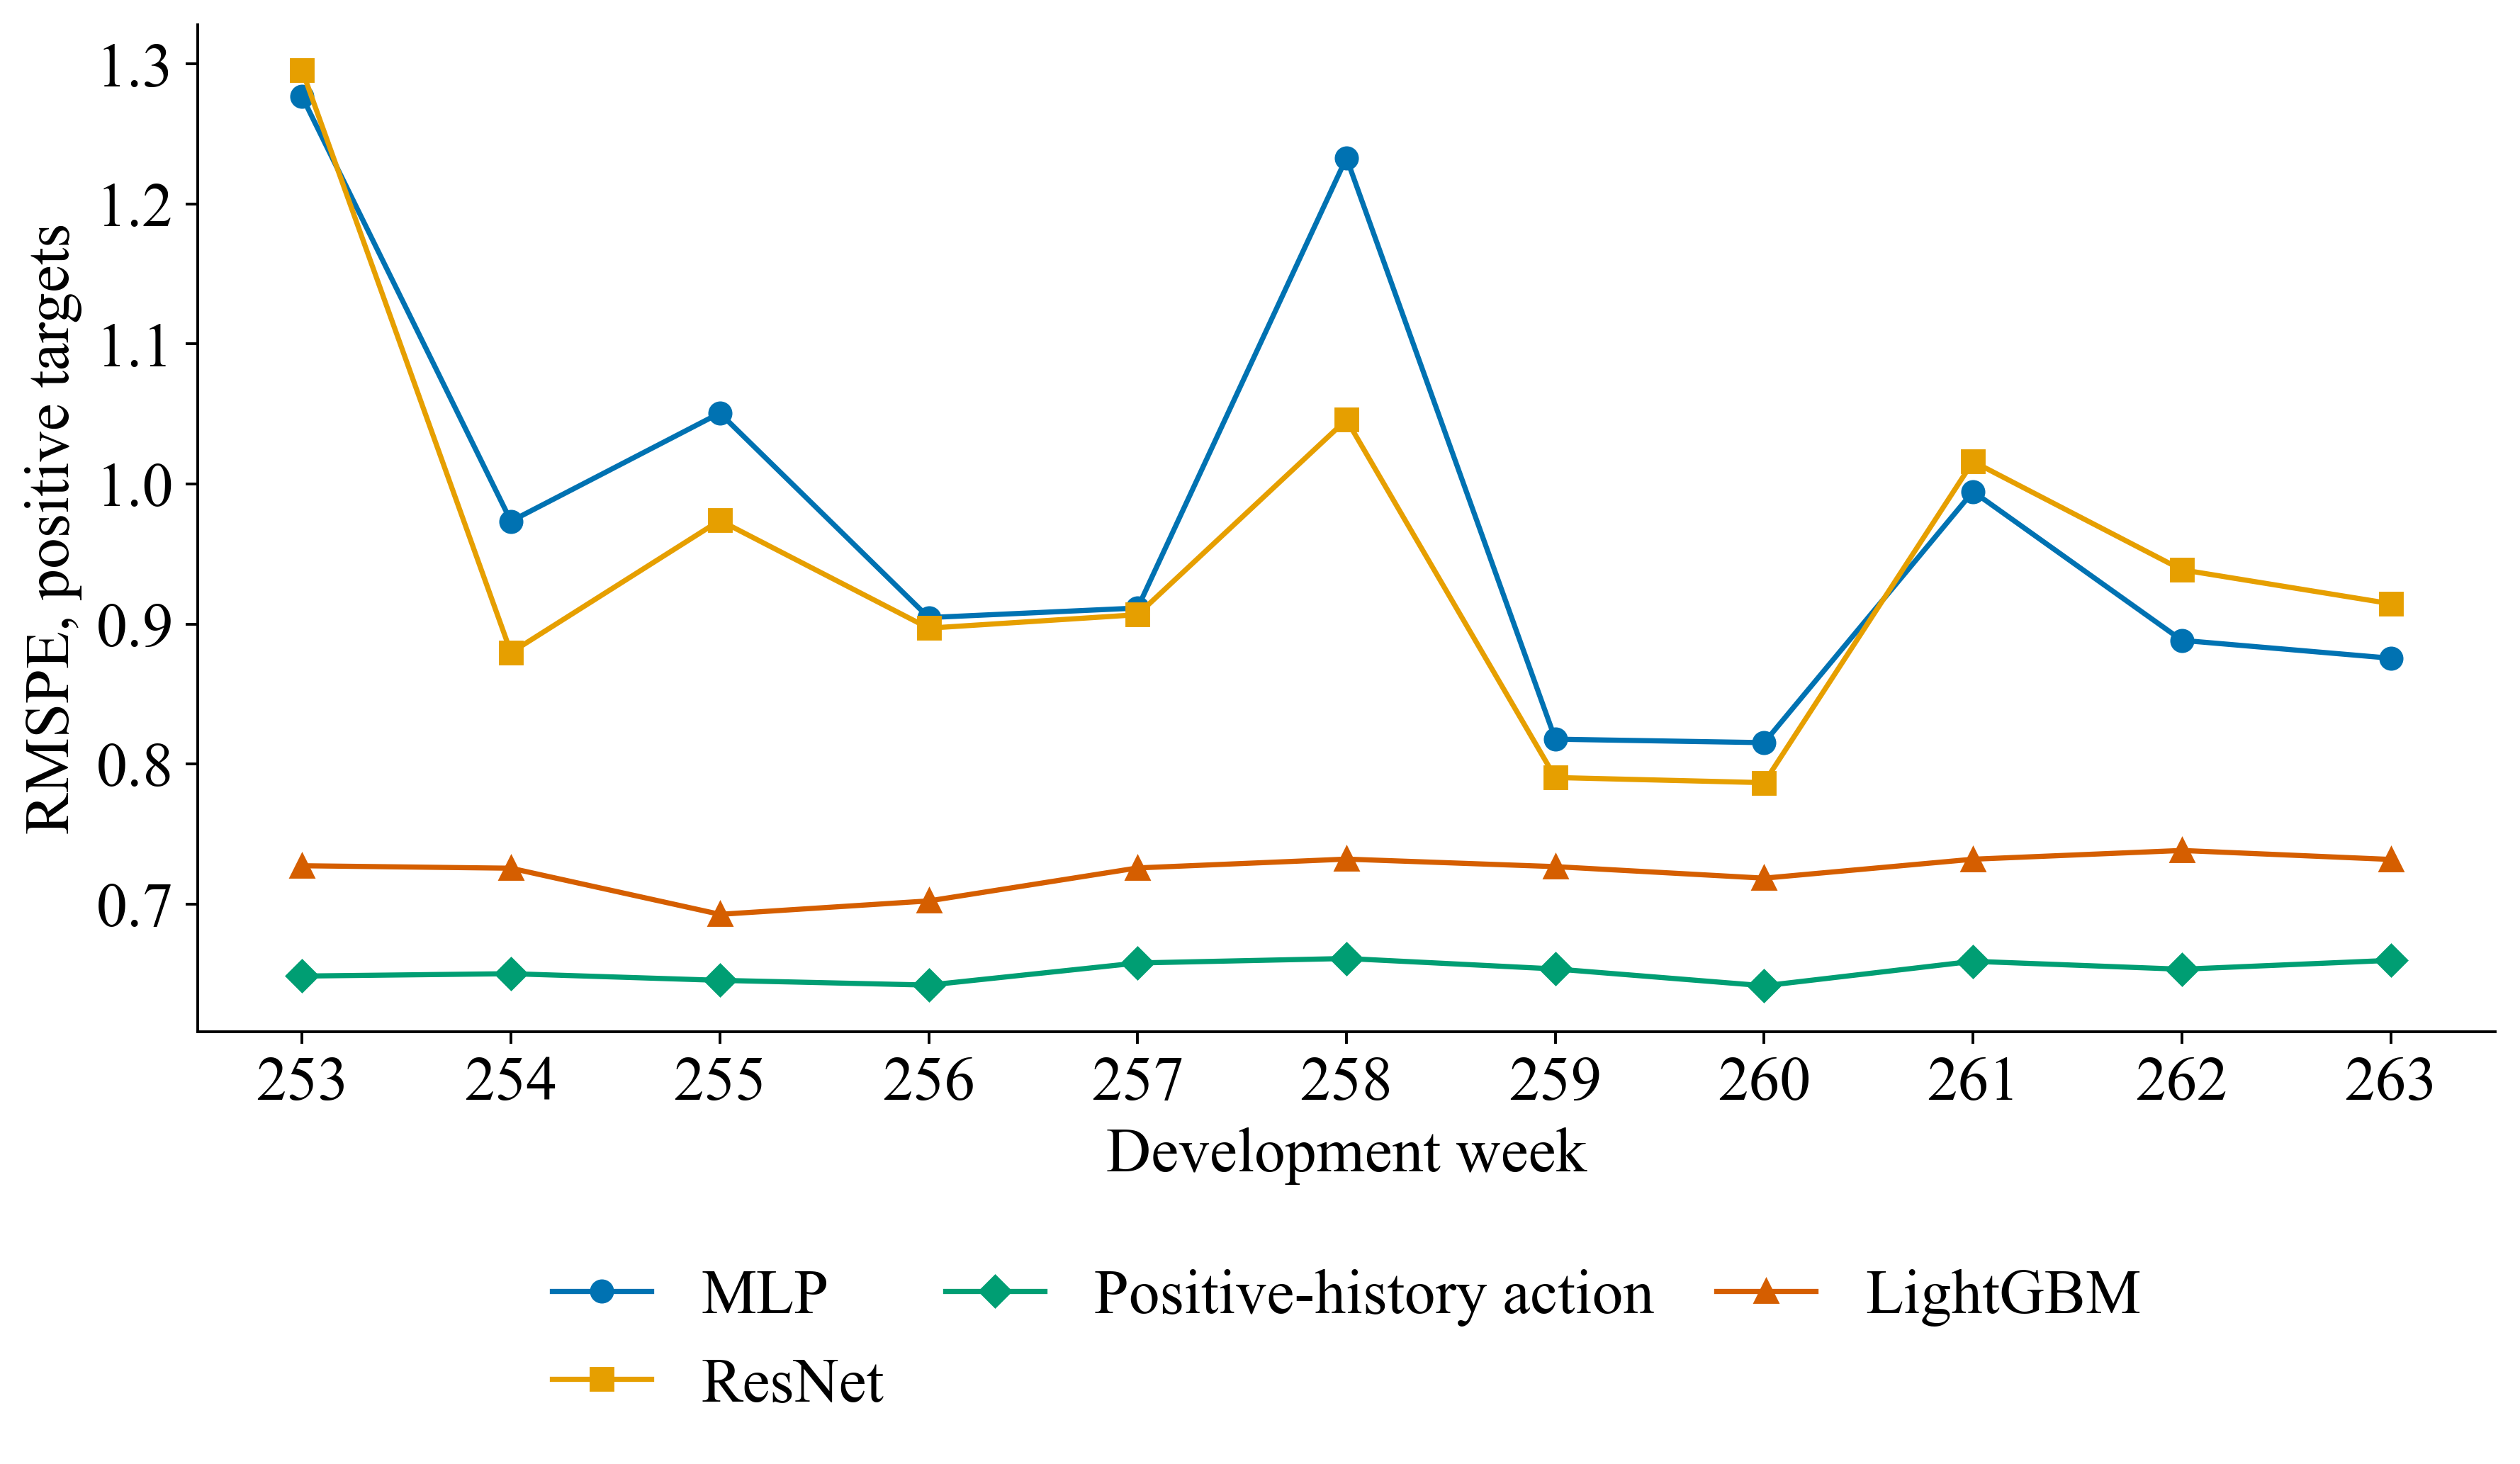

,Network,Most correlated model,Correlation,Least correlated model,Correlation (least)
0,MLP,ResNet,0.95448,Positive-history action,0.52882
1,ResNet,MLP,0.95448,Positive-history action,0.50858


In [7]:
# NB04_COMPARISON
nb03_dev=pd.read_csv(NB03_OUT/'development_accuracy.csv');nb03_dev['Notebook']='NB03';nets=pd.DataFrame([{'Model':name,**metrics(DEV.quantity,PREDICTIONS[(name,SEED)])} for name in MODEL_ORDER]).drop(columns=['Positive_n','Zero_n']);nets['Notebook']='NB04'
comparison=pd.concat([nets,nb03_dev],ignore_index=True).sort_values('RMSPE').reset_index(drop=True);table(comparison[['Model','Notebook','RMSPE','RMSE','MAE','Zero_MAE']],'development_accuracy',['RMSPE','RMSE','MAE','Zero_MAE'])
table(pd.DataFrame([{'Model':name,'Actual seeds':len(NET_SEEDS),'Mean RMSPE':np.mean(v),'SD RMSPE':np.std(v,ddof=1),'Minimum RMSPE':np.min(v),'Maximum RMSPE':np.max(v)} for name in MODEL_ORDER for v in [[metrics(DEV.quantity,PREDICTIONS[(name,s)])['RMSPE'] for s in NET_SEEDS]]]),'seed_stability')
pd.DataFrame(TRIALS).to_csv(OUT/'all_search_trials.csv',index=False);ep=pd.DataFrame(EPOCHS);table(ep[ep.Cohort=='all'][['Model','Stage','Seed','Selected epoch','Epochs run','Inner-window RMSPE']].reset_index(drop=True),'network_epochs')
table(pd.DataFrame(RESOURCES).groupby('Model',sort=False).agg(actual_fits=('Actual learner fit','sum'),fit_seconds=('Fit seconds','sum'),mean_selected_epoch=('Selected epoch','mean'),process_peak_MiB=('Process peak MiB','max')).reset_index(),'resource_totals',fmt='%.1f')
DEV[['row_id','id','week','quantity']].to_parquet(OUT/'development_rows.parquet',index=False)
fig,axes=plt.subplots(1,2,figsize=(12.8,5.8))
for name,col,mk in zip(MODEL_ORDER,PALETTE,'osD'):
    h=pd.DataFrame(CURVES[f'{name}|final|{SEED}']);e=FROZEN_MODELS[name]['selected_epoch'];axes[0].plot(h.epoch,h.train_loss,color=col,marker=mk,ms=4,label=name);axes[1].plot(h.epoch,h.inner_RMSPE,color=col,marker=mk,ms=4,label=name);axes[1].plot([e],[h.inner_RMSPE[e-1]],color=col,marker=mk,ms=13,mfc='none',mew=2)
axes[0].set(xlabel='Epoch',ylabel='Training loss (standardised log1p)');axes[1].set(xlabel='Epoch',ylabel='Inner-window RMSPE')
for ax in axes:ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
h_,l_=axes[0].get_legend_handles_labels();label_panels(axes);fig.legend(h_,l_,loc='lower center',ncol=2,frameon=False);fig.tight_layout(rect=[0,0.10,1,1]);figure(fig,'fig_m5_network_training')
y=DEV.quantity.to_numpy(float);wk=DEV.week.to_numpy();weeks=sorted(DEV.week.unique());nb03_pred=np.load(NB03_OUT/'development_predictions.npz');nb03_order=BM['model_order'];assert pd.read_parquet(NB03_OUT/'development_rows.parquet').row_id.tolist()==DEV.row_id.tolist()
ALL={name:PREDICTIONS[(name,SEED)] for name in MODEL_ORDER};ALL.update({m:nb03_pred[f'{nb03_order.index(m)}_{SEED}'] for m in nb03_order})
show=MODEL_ORDER+nb03_dev.sort_values('RMSPE').Model.head(2).tolist();fig,ax=plt.subplots(figsize=(10.5,6.4))
for m,col,mk in zip(show,PALETTE,'osD^v'):ax.plot(weeks,[rmspe(y[wk==w],ALL[m][wk==w]) for w in weeks],color=col,marker=mk,label=m)
ax.set(xlabel='Development week',ylabel='RMSPE, positive targets');ax.set_xticks(weeks);ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=3,frameon=False,columnspacing=1.0,handlelength=1.6);fig.tight_layout();figure(fig,'fig_m5_network_weekly')
positive=y>0;corr=pd.DataFrame({m:(p[positive]-y[positive])/y[positive] for m,p in ALL.items()}).corr(method='spearman');corr.rename_axis('Model').reset_index().to_csv(OUT/'error_correlations_full.csv',index=False)
table(pd.DataFrame([{'Network':a,'Most correlated model':corr[a].drop(a).idxmax(),'Correlation':corr[a].drop(a).max(),'Least correlated model':corr[a].drop(a).idxmin(),'Correlation (least)':corr[a].drop(a).min()} for a in MODEL_ORDER]),'error_complementarity')

### Nested residual laws

In [8]:
# NB04_CALIBRATION: nested residual laws of the networks
CALIBRATORS={};q=(np.arange(257)+.5)/257
for name in MODEL_ORDER:
    nested=NESTED[name];CALIBRATORS[name]=np.quantile((nested.quantity.to_numpy()-nested.prediction.to_numpy())/np.sqrt(nested.prediction.to_numpy()+1),q)
np.savez_compressed(OUT/'nested_residual_calibrators.npz',**{str(MODEL_ORDER.index(k)):v for k,v in CALIBRATORS.items()})
# model order, selected configurations and network settings for notebooks 05-06; run registry
manifest={'run_id':RUN_ID,'model_order':MODEL_ORDER,'selected_configurations':CONFIGS,'net_epochs':NET_EPOCHS,'net_seeds':NET_SEEDS,'numeric_positions':NUM_POS,'nb03_run':BM['run_id']}
dump(BASE/'Manifests/network_manifest.json',manifest)
latest_path=BASE/'Manifests/latest_runs.json';latest=json.loads(latest_path.read_text()) if latest_path.exists() else {};latest['NB04']=RUN_ID;dump(latest_path,latest)